
## Certamen II: Monitoreo del cumplimiento de Elementos de Protección Personal (EPP) mediante Inteligencia Artificial

**Integrantes** <br>
Catalina Cornejo<br>
Hellen Quiñones<br>
Gustavo Sanchez


### Objetivo del proyecto

Desarrollar un sistema de inteligencia artificial basado en YOLO para detectar elementos de protección personal (EPP) en imágenes de entornos laborales, con el propósito de apoyar la identificación de posibles incumplimientos de seguridad según las exigencias de cada zona de trabajo.

El sistema utilizará técnicas de visión por computador para identificar los objetos presentes en una imagen. Posteriormente, sus resultados podrán integrarse con reglas de seguridad, herramientas de IA generativa y un flujo de automatización que permita informar posibles riesgos a un responsable de prevención.

### Dataset seleccionado

Se utilizará el dataset público **SH17: Dataset for PPE Detection**, disponible en Kaggle:

https://www.kaggle.com/datasets/mugheesahmad/sh17-dataset-for-ppe-detection


### Objetivo de esta etapa

---

## **1. Preparación y exploración del dataset**

Se prepara un subconjunto reducido y representativo del dataset original para disminuir los recursos computacionales necesarios durante el entrenamiento de YOLO.

La selección buscará:

- Conservar todas las imágenes que contengan categorías minoritarias, según el criterio que se defina después del análisis.
- Seleccionar imágenes adicionales de las categorías mayoritarias de manera balanceada.
- Mantener las anotaciones originales de las imágenes seleccionadas.
- Conservar una separación adecuada entre entrenamiento, validación y prueba.
- Generar un dataset compatible con YOLO.

La preparación comenzará con la exploración de los archivos y la distribución de categorías. No se realizará ningún recorte del dataset antes de conocer su estructura y composición.


### 1.1. Instalación de librerías

Se instalan las librerías necesarias para descargar, explorar y analizar el dataset SH17.

Se utilizará `kagglehub` para acceder al conjunto de datos, `pandas` para organizar los resultados, `NumPy` para operaciones numéricas, `Matplotlib` para visualizaciones y `PyYAML` para leer archivos de configuración.



In [2]:
# Instalación de librerías para trabajar con el dataset
%pip -q install kagglehub pandas pyyaml matplotlib pillow



### 1.2. Descarga y localización del dataset SH17

Se descarga el dataset SH17 desde Kaggle o se utiliza una copia local si ya se encuentra disponible.Para garantizar la reproducibilidad, se establece una semilla aleatoria = 2026

Luego, una vez localizado el dataset, se muestran los archivos y carpetas principales para comprobar que la descarga se haya realizado correctamente.

*Durante este procedimiento no se modifican ni eliminan archivos originales.*


In [3]:

import kagglehub
from pathlib import Path
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla para reproducir los resultados
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Dataset seleccionado
DATASET_SLUG = "mugheesahmad/sh17-dataset-for-ppe-detection"

# Si ya tienes el dataset descomprimido, coloca aquí su ruta.
# De lo contrario, se descargará desde Kaggle.
RUTA_LOCAL = None

if RUTA_LOCAL is not None:
    ruta = Path(RUTA_LOCAL)
else:
    ruta_kaggle = Path(
        "/kaggle/input/sh17-dataset-for-ppe-detection"
    )

    if ruta_kaggle.exists():
        ruta = ruta_kaggle
    else:
        ruta = Path(
            kagglehub.dataset_download(DATASET_SLUG)
        )

assert ruta.exists(), "No se encontró el dataset."

print("Dataset ubicado en:", ruta)
print("\nContenido principal:")

for archivo in sorted(ruta.iterdir()):
    print("-", archivo.name)


Using Colab cache for faster access to the 'sh17-dataset-for-ppe-detection' dataset.
Dataset ubicado en: /kaggle/input/sh17-dataset-for-ppe-detection

Contenido principal:
- images
- labels
- meta-data
- train_files.txt
- val_files.txt
- voc_labels



### 1.3. Exploración de la estructura del dataset

Se examina la organización de carpetas y archivos del dataset SH17 para identificar dónde se encuentran las imágenes, las anotaciones y los archivos de configuración.

Se realiza un recuento preliminar de los archivos de imagen, archivos TXT y configuraciones YAML, con el objetivo de comprender cómo están almacenados los datos.

Esta exploración permitirá determinar las rutas que se utilizarán en las siguientes etapas y verificar el formato de las anotaciones.

Una vez identificada la estructura, se analizará la cantidad de imágenes y objetos asociados a cada clase para definir una estrategia de selección balanceada.


In [4]:

# Revisamos los primeros niveles de carpetas del dataset

print("ESTRUCTURA DEL DATASET SH17\n")

for ubicacion, subcarpetas, archivos in os.walk(ruta):
    carpeta = Path(ubicacion)
    nivel = len(carpeta.relative_to(ruta).parts)

    # Mostrar máximo tres niveles
    if nivel > 3:
        subcarpetas[:] = []
        continue

    espacio = "  " * nivel

    print(f"{espacio}{carpeta.name}/")
    print(f"{espacio}  Cantidad de archivos: {len(archivos)}")

    # Ejemplos de archivos
    for archivo in sorted(archivos)[:4]:
        print(f"{espacio}  - {archivo}")

# Identificamos archivos relevantes
extensiones = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

imagenes = sorted(
    p for p in ruta.rglob("*")
    if p.is_file() and p.suffix.lower() in extensiones
)

etiquetas = sorted(ruta.rglob("*.txt"))
configuraciones = sorted(
    p for p in ruta.rglob("*")
    if p.is_file() and p.suffix.lower() in {".yaml", ".yml"}
)

print("\nRESUMEN PRELIMINAR")
print("Archivos de imagen:", len(imagenes))
print("Archivos TXT:", len(etiquetas))

print("\nArchivos YAML encontrados:")
for archivo in configuraciones[:15]:
    print("-", archivo.relative_to(ruta))


ESTRUCTURA DEL DATASET SH17

sh17-dataset-for-ppe-detection/
  Cantidad de archivos: 2
  - train_files.txt
  - val_files.txt
  labels/
    Cantidad de archivos: 8099
    - building-construction-building-site-constructing.txt
    - career-firefighter-relaxing-job-162540.txt
    - carrying-head-indian-farm-worker-158011.txt
    - construction-site-build-construction-work-159306.txt
  images/
    Cantidad de archivos: 8099
    - building-construction-building-site-constructing.jpg
    - career-firefighter-relaxing-job-162540.jpeg
    - carrying-head-indian-farm-worker-158011.jpeg
    - construction-site-build-construction-work-159306.jpeg
  meta-data/
    Cantidad de archivos: 8099
    - building-construction-building-site-constructing.json
    - career-firefighter-relaxing-job-162540.json
    - carrying-head-indian-farm-worker-158011.json
    - construction-site-build-construction-work-159306.json
  voc_labels/
    Cantidad de archivos: 8099
    - building-construction-building-site-cons


### 1.4. Identificación de clases y análisis de distribución

Se identifican las 17 categorías del dataset SH17 utilizando los identificadores definidos en el archivo `sh17.yaml` oficial.

Posteriormente, se recorren las anotaciones YOLO para calcular:

- La cantidad de imágenes que contienen cada categoría.
- La cantidad total de objetos anotados por categoría.
- La existencia de etiquetas faltantes o incorrectas.
- La distribución de las clases mediante un gráfico de barras.

Este análisis es fundamental para identificar las categorías minoritarias y establecer un criterio de selección balanceada.

Es importante considerar que una imagen puede contener objetos de múltiples categorías. Por ello, el número total de imágenes contabilizadas por clase puede superar la cantidad de fotografías del dataset.

Los resultados permitirán diseñar un subconjunto de entrenamiento que conserve la representación de las clases menos frecuentes, sin modificar las anotaciones originales.


DISTRIBUCIÓN DE CLASES SH17


,ID,Clase,Imágenes,Objetos
0,13,medical-suit,98,137
1,4,face-guard,127,133
2,15,safety-suit,135,232
3,16,safety-vest,208,519
4,2,ear-mufs,220,314
5,6,foot,343,749
6,5,face-mask,393,666
7,10,helmet,465,924
8,9,gloves,1311,2754
9,14,shoes,1556,4489



RESUMEN DE VALIDACIÓN
Total de imágenes: 8099
Objetos válidos: 73810
Etiquetas faltantes: 0
Etiquetas inválidas: 2184
Imágenes sin objetos válidos: 18

Ejemplos de errores:
('pexels-photo-10341095.jpeg', 6, 'Coordenadas fuera de rango')
('pexels-photo-10341095.jpeg', 7, 'Coordenadas fuera de rango')
('pexels-photo-10341095.jpeg', 8, 'Coordenadas fuera de rango')
('pexels-photo-10341096.jpeg', 5, 'Coordenadas fuera de rango')
('pexels-photo-10341105.jpeg', 3, 'Coordenadas fuera de rango')


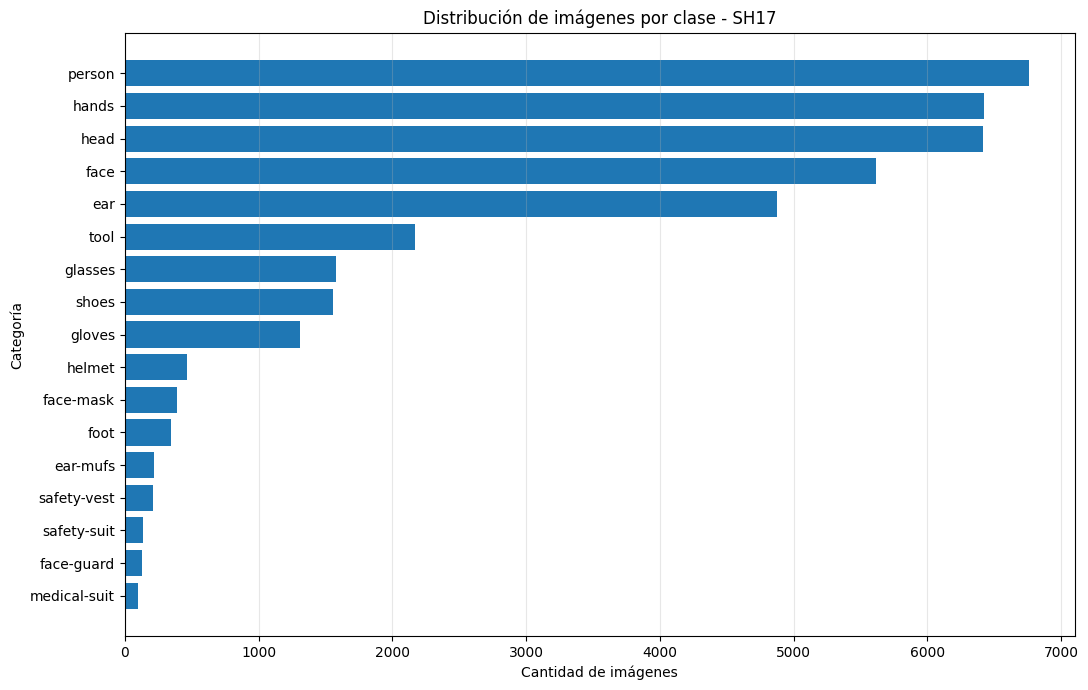

In [5]:

from collections import Counter

# Clases oficiales de SH17 según sh17.yaml
CLASES = {
    0: "person",
    1: "ear",
    2: "ear-mufs",
    3: "face",
    4: "face-guard",
    5: "face-mask",
    6: "foot",
    7: "tool",
    8: "glasses",
    9: "gloves",
    10: "helmet",
    11: "hands",
    12: "head",
    13: "medical-suit",
    14: "shoes",
    15: "safety-suit",
    16: "safety-vest"
}

# Contadores de imágenes y objetos por categoría
imagenes_por_clase = Counter()
objetos_por_clase = Counter()

# Guardaremos las clases presentes en cada imagen
clases_por_imagen = {}

etiquetas_faltantes = []
etiquetas_invalidas = []
imagenes_sin_objetos = 0

# Recorremos las imágenes del dataset
for imagen in imagenes:

    archivo_label = ruta / "labels" / f"{imagen.stem}.txt"
    clases_presentes = set()

    if not archivo_label.exists():
        etiquetas_faltantes.append(imagen.name)
        continue

    with open(archivo_label, "r", encoding="utf-8") as f:
        lineas = f.readlines()

    objetos_validos = 0

    for numero_linea, linea in enumerate(lineas, start=1):

        datos = linea.strip().split()

        if not datos:
            continue

        try:
            # YOLO detección: clase x_centro y_centro ancho alto
            if len(datos) != 5:
                raise ValueError("Formato incorrecto")

            clase_id = int(datos[0])
            coordenadas = [float(v) for v in datos[1:]]

            if clase_id not in CLASES:
                raise ValueError("Clase desconocida")

            x, y, ancho, alto = coordenadas

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < ancho <= 1 and
                0 < alto <= 1 and
                0 <= x - ancho / 2 <= 1 and
                0 <= x + ancho / 2 <= 1 and
                0 <= y - alto / 2 <= 1 and
                0 <= y + alto / 2 <= 1
            ):
                raise ValueError("Coordenadas fuera de rango")

            objetos_por_clase[clase_id] += 1
            clases_presentes.add(clase_id)
            objetos_validos += 1

        except (ValueError, TypeError) as error:
            etiquetas_invalidas.append(
                (imagen.name, numero_linea, str(error))
            )

    # Cada clase se cuenta una sola vez por fotografía
    for clase_id in clases_presentes:
        imagenes_por_clase[clase_id] += 1

    clases_por_imagen[imagen.name] = clases_presentes

    if objetos_validos == 0:
        imagenes_sin_objetos += 1

# Tabla resumen
df_clases = pd.DataFrame([
    {
        "ID": id_clase,
        "Clase": nombre,
        "Imágenes": imagenes_por_clase[id_clase],
        "Objetos": objetos_por_clase[id_clase]
    }
    for id_clase, nombre in CLASES.items()
])

# De menor a mayor frecuencia
df_clases = df_clases.sort_values(
    "Imágenes", ascending=True
).reset_index(drop=True)

print("DISTRIBUCIÓN DE CLASES SH17")
display(df_clases)

print("\nRESUMEN DE VALIDACIÓN")
print("Total de imágenes:", len(imagenes))
print("Objetos válidos:", sum(objetos_por_clase.values()))
print("Etiquetas faltantes:", len(etiquetas_faltantes))
print("Etiquetas inválidas:", len(etiquetas_invalidas))
print("Imágenes sin objetos válidos:", imagenes_sin_objetos)

if etiquetas_invalidas:
    print("\nEjemplos de errores:")
    for error in etiquetas_invalidas[:5]:
        print(error)

# Gráfico de distribución
plt.figure(figsize=(11, 7))

plt.barh(
    df_clases["Clase"],
    df_clases["Imágenes"]
)

plt.xlabel("Cantidad de imágenes")
plt.ylabel("Categoría")
plt.title("Distribución de imágenes por clase - SH17")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



### 1.5. Verificación de los conjuntos de entrenamiento y validación

Se revisan los archivos `train_files.txt` y `val_files.txt`, que contienen la distribución original de imágenes del dataset SH17.

El objetivo es comprobar:

- La cantidad de imágenes asignadas a entrenamiento y validación.
- La existencia de imágenes duplicadas entre ambos conjuntos.
- La correspondencia entre los nombres registrados y los archivos disponibles.
- La representación de cada clase dentro de ambas particiones.

Se conservará la separación original mientras se diseña el subconjunto reducido. Esto permitirá evitar la fuga de información entre entrenamiento y evaluación.

La selección balanceada se realizará posteriormente sobre el conjunto de entrenamiento, sin utilizar imágenes de validación para entrenar el modelo.


In [6]:

from collections import Counter, defaultdict

# Archivos originales de partición
archivo_train = ruta / "train_files.txt"
archivo_val = ruta / "val_files.txt"

# Índice de imágenes disponibles
imagenes_por_nombre = {p.name: p for p in imagenes}

imagenes_por_stem = defaultdict(list)
for p in imagenes:
    imagenes_por_stem[p.stem].append(p.name)


def leer_particion(archivo):
    """Lee una lista de imágenes y verifica su existencia."""

    with open(archivo, "r", encoding="utf-8-sig") as f:
        lineas = [
            linea.strip().strip('"').strip("'")
            for linea in f
            if linea.strip()
        ]

    encontrados = []
    faltantes = []
    ambiguos = []

    for entrada in lineas:
        # Admite nombres y rutas de Windows o Linux
        nombre = entrada.replace("\\", "/").split("/")[-1]

        if nombre in imagenes_por_nombre:
            encontrados.append(nombre)

        elif nombre in imagenes_por_stem:
            candidatos = imagenes_por_stem[nombre]

            if len(candidatos) == 1:
                encontrados.append(candidatos[0])
            else:
                ambiguos.append(entrada)

        else:
            faltantes.append(entrada)

    return lineas, encontrados, faltantes, ambiguos


# Lectura de ambos conjuntos
lineas_train, lista_train, faltantes_train, ambiguos_train = (
    leer_particion(archivo_train)
)

lineas_val, lista_val, faltantes_val, ambiguos_val = (
    leer_particion(archivo_val)
)

train = set(lista_train)
val = set(lista_val)

# Comprobaciones
repetidas_train = len(lista_train) - len(train)
repetidas_val = len(lista_val) - len(val)
interseccion = train & val

todas = set(imagenes_por_nombre.keys())
sin_asignar = todas - (train | val)

print("VERIFICACIÓN DE PARTICIONES SH17\n")

print("Entrenamiento:", len(train), "imágenes")
print("Validación:", len(val), "imágenes")
print("Total asignadas:", len(train | val))
print("Total del dataset:", len(todas))

print("\nCONTROL DE INTEGRIDAD")
print("Duplicadas dentro de train:", repetidas_train)
print("Duplicadas dentro de val:", repetidas_val)
print("Compartidas entre train y val:", len(interseccion))
print("No encontradas en el dataset:",
      len(faltantes_train) + len(faltantes_val))
print("Nombres ambiguos:",
      len(ambiguos_train) + len(ambiguos_val))
print("Imágenes sin partición:", len(sin_asignar))

# Distribución de imágenes por clase y partición
def contar_clases(nombres):
    contador = Counter()

    for nombre in nombres:
        for clase_id in clases_por_imagen.get(nombre, set()):
            contador[clase_id] += 1

    return contador


conteo_train = contar_clases(train)
conteo_val = contar_clases(val)

df_particiones = pd.DataFrame([
    {
        "Clase": nombre,
        "Train": conteo_train[id_clase],
        "Val": conteo_val[id_clase],
        "Total": imagenes_por_clase[id_clase]
    }
    for id_clase, nombre in CLASES.items()
])

df_particiones = df_particiones.sort_values(
    "Total", ascending=True
).reset_index(drop=True)

print("\nDISTRIBUCIÓN POR CLASE Y PARTICIÓN")
display(df_particiones)

# Conclusión de la verificación
integridad_ok = (
    repetidas_train == 0
    and repetidas_val == 0
    and len(interseccion) == 0
    and len(faltantes_train) == 0
    and len(faltantes_val) == 0
    and len(ambiguos_train) == 0
    and len(ambiguos_val) == 0
    and len(sin_asignar) == 0
)

if integridad_ok:
    print("\nPARTICIONES VERIFICADAS CORRECTAMENTE")
else:
    print("\nATENCIÓN: revisar las inconsistencias detectadas")

    print("Ejemplos de archivos faltantes:",
          (faltantes_train + faltantes_val)[:5])

    print("Ejemplos de imágenes compartidas:",
          sorted(interseccion)[:5])


VERIFICACIÓN DE PARTICIONES SH17

Entrenamiento: 6479 imágenes
Validación: 1620 imágenes
Total asignadas: 8099
Total del dataset: 8099

CONTROL DE INTEGRIDAD
Duplicadas dentro de train: 0
Duplicadas dentro de val: 0
Compartidas entre train y val: 0
No encontradas en el dataset: 0
Nombres ambiguos: 0
Imágenes sin partición: 0

DISTRIBUCIÓN POR CLASE Y PARTICIÓN


,Clase,Train,Val,Total
0,medical-suit,70,28,98
1,face-guard,104,23,127
2,safety-suit,109,26,135
3,safety-vest,163,45,208
4,ear-mufs,182,38,220
5,foot,280,63,343
6,face-mask,318,75,393
7,helmet,372,93,465
8,gloves,1058,253,1311
9,shoes,1237,319,1556



PARTICIONES VERIFICADAS CORRECTAMENTE



### 1.6. Diagnóstico de anotaciones inválidas

Durante la exploración inicial se identificaron 2.184 anotaciones que no cumplieron las condiciones de validación establecidas para las cajas delimitadoras.

En esta etapa se analizarán dichas anotaciones para determinar:

- Cuántas presentan coordenadas fuera del rango normalizado.
- Cuántas corresponden a cajas que sobrepasan los bordes de la imagen.
- Qué categorías concentran la mayor cantidad de problemas.
- Cómo se distribuyen los errores entre entrenamiento y validación.

Este diagnóstico permitirá establecer una estrategia de limpieza antes de generar el subconjunto reducido.

No se modificarán ni eliminarán anotaciones durante esta etapa, ya que primero es necesario comprender la naturaleza y magnitud de los errores.


In [7]:

import math
from pathlib import Path
import pandas as pd

# Identificación de las particiones
train_stems = {Path(nombre).stem for nombre in train}
val_stems = {Path(nombre).stem for nombre in val}

# Variables para registrar problemas
errores = []
total_anotaciones = 0
anotaciones_validas = 0

# Recorremos todas las etiquetas
for archivo in sorted((ruta / "labels").glob("*.txt")):

    if archivo.stem in train_stems:
        conjunto = "Train"
    elif archivo.stem in val_stems:
        conjunto = "Val"
    else:
        conjunto = "Sin asignar"

    with open(archivo, "r", encoding="utf-8") as f:
        lineas = f.readlines()

    for numero_linea, linea in enumerate(lineas, start=1):

        datos = linea.strip().split()

        if not datos:
            continue

        total_anotaciones += 1

        motivo = None
        clase_id = None
        exceso = None

        if len(datos) != 5:
            motivo = "Formato incorrecto"

        else:
            try:
                clase_id = int(datos[0])
                x, y, w, h = map(float, datos[1:])

                if not all(math.isfinite(v) for v in (x, y, w, h)):
                    motivo = "Valores no finitos"

                elif clase_id not in CLASES:
                    motivo = "ID de clase desconocido"

                elif not (
                    0 <= x <= 1 and
                    0 <= y <= 1 and
                    0 < w <= 1 and
                    0 < h <= 1
                ):
                    motivo = "Valores normalizados fuera de rango"

                else:
                    # Límites reales de la caja
                    x_min = x - w / 2
                    x_max = x + w / 2
                    y_min = y - h / 2
                    y_max = y + h / 2

                    # Magnitud máxima fuera de la imagen
                    exceso = max(
                        0,
                        -x_min,
                        x_max - 1,
                        -y_min,
                        y_max - 1
                    )

                    if exceso > 0:
                        motivo = "Caja sobrepasa los bordes"

            except ValueError:
                motivo = "Datos no numéricos"

        if motivo is None:
            anotaciones_validas += 1
        else:
            errores.append({
                "Imagen": archivo.stem,
                "Conjunto": conjunto,
                "Línea": numero_linea,
                "Clase": CLASES.get(clase_id, "Desconocida"),
                "Motivo": motivo,
                "Exceso": exceso,
                "Anotación": linea.strip()
            })


# Resultados
df_errores = pd.DataFrame(errores)

print("DIAGNÓSTICO DE ANOTACIONES SH17\n")

print("Total de anotaciones:", total_anotaciones)
print("Anotaciones válidas:", anotaciones_validas)
print("Anotaciones con problemas:", len(errores))

if not df_errores.empty:

    print("\n1. TIPOS DE PROBLEMAS")
    display(
        df_errores["Motivo"]
        .value_counts()
        .rename_axis("Motivo")
        .reset_index(name="Cantidad")
    )

    print("\n2. ERRORES POR CONJUNTO")
    display(
        pd.crosstab(
            df_errores["Conjunto"],
            df_errores["Motivo"]
        )
    )

    print("\n3. ERRORES POR CLASE")
    display(
        df_errores["Clase"]
        .value_counts()
        .rename_axis("Clase")
        .reset_index(name="Cantidad")
    )

    print("\n4. IMÁGENES AFECTADAS")
    print(df_errores["Imagen"].nunique())

    print("\n5. EJEMPLOS DE ANOTACIONES PROBLEMÁTICAS")
    display(df_errores.head(10))

    cajas_fuera = df_errores[
        df_errores["Motivo"] == "Caja sobrepasa los bordes"
    ]

    if not cajas_fuera.empty:
        print("\n6. MAGNITUD DEL EXCESO DE LAS CAJAS")
        display(cajas_fuera["Exceso"].describe())


DIAGNÓSTICO DE ANOTACIONES SH17

Total de anotaciones: 75994
Anotaciones válidas: 73810
Anotaciones con problemas: 2184

1. TIPOS DE PROBLEMAS


,Motivo,Cantidad
0,Caja sobrepasa los bordes,2184



2. ERRORES POR CONJUNTO


Motivo,Caja sobrepasa los bordes
Conjunto,
Train,1753
Val,431



3. ERRORES POR CLASE


,Clase,Cantidad
0,person,1477
1,head,173
2,tool,153
3,hands,141
4,shoes,71
5,face,40
6,gloves,36
7,medical-suit,20
8,ear,16
9,glasses,16



4. IMÁGENES AFECTADAS
1846

5. EJEMPLOS DE ANOTACIONES PROBLEMÁTICAS


,Imagen,Conjunto,Línea,Clase,Motivo,Exceso,Anotación
0,pexels-photo-10341095,Train,6,hands,Caja sobrepasa los bordes,5.000000e-07,11 0.954167 0.714784 0.091667 0.210817
1,pexels-photo-10341095,Train,7,person,Caja sobrepasa los bordes,5.000000e-07,0 0.775641 0.524159 0.445833 0.951683
2,pexels-photo-10341095,Train,8,person,Caja sobrepasa los bordes,5.000000e-07,0 0.247035 0.704087 0.318429 0.591827
3,pexels-photo-10341096,Val,5,person,Caja sobrepasa los bordes,5.000000e-07,0 0.559328 0.534271 0.881345 0.931458
4,pexels-photo-10341105,Train,3,person,Caja sobrepasa los bordes,5.000000e-07,0 0.532341 0.500166 0.536564 0.999669
5,pexels-photo-10341122,Val,2,head,Caja sobrepasa los bordes,5.000000e-07,12 0.639904 0.102764 0.288782 0.205529
6,pexels-photo-10347147,Train,4,person,Caja sobrepasa los bordes,5.000000e-07,0 0.829728 0.508413 0.340545 0.983173
7,pexels-photo-10375931,Train,15,person,Caja sobrepasa los bordes,5.000000e-07,0 0.231125 0.716201 0.221572 0.567599
8,pexels-photo-10375933,Train,13,person,Caja sobrepasa los bordes,5.000000e-07,0 0.717039 0.566964 0.565923 0.866071
9,pexels-photo-10375945,Val,1,head,Caja sobrepasa los bordes,5.000000e-07,12 0.936161 0.177902 0.127679 0.313393



6. MAGNITUD DEL EXCESO DE LAS CAJAS


,Exceso
count,2.184000e+03
mean,5.000000e-07
std,3.696021e-17
min,5.000000e-07
25%,5.000000e-07
50%,5.000000e-07
75%,5.000000e-07
max,5.000000e-07



### 1.7. Validación definitiva y actualización de la distribución de clases

El diagnóstico identificó 2.184 anotaciones cuyos límites superaban el rango permitido en 0,0000005 unidades normalizadas.

Debido a que esta diferencia es compatible con el redondeo de coordenadas decimales, se establece una tolerancia de 0,000001 para validar los límites de las cajas.

Con este ajuste se busca conservar las anotaciones originales, evitando eliminar información por diferencias numéricas insignificantes.

Posteriormente, se recalcula la distribución de imágenes y objetos por categoría, considerando únicamente las anotaciones aceptadas mediante el nuevo criterio.

Con ello,esta distribución actualizada será la base para seleccionar el subconjunto balanceado del dataset SH17.


In [8]:

from collections import Counter
import math
import pandas as pd

# Tolerancia para pequeños errores de redondeo
TOLERANCIA = 1e-6

# Conservamos los conteos anteriores para comparar
conteo_anterior = Counter(imagenes_por_clase)

# Reiniciamos los contadores
imagenes_por_clase = Counter()
objetos_por_clase = Counter()
clases_por_imagen = {}

errores_restantes = []
total_anotaciones = 0
imagenes_sin_objetos = 0

for imagen in imagenes:

    archivo_label = ruta / "labels" / f"{imagen.stem}.txt"
    clases_presentes = set()
    objetos_imagen = 0

    if not archivo_label.exists():
        errores_restantes.append(
            (imagen.name, "Etiqueta faltante")
        )
        continue

    with open(archivo_label, "r", encoding="utf-8") as f:
        lineas = f.readlines()

    for num_linea, linea in enumerate(lineas, 1):

        datos = linea.strip().split()

        if not datos:
            continue

        total_anotaciones += 1

        try:
            if len(datos) != 5:
                raise ValueError("Formato incorrecto")

            clase_id = int(datos[0])
            x, y, w, h = map(float, datos[1:])

            if clase_id not in CLASES:
                raise ValueError("Clase desconocida")

            if not all(math.isfinite(v) for v in (x, y, w, h)):
                raise ValueError("Valores no finitos")

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):
                raise ValueError("Coordenadas inválidas")

            # Calculamos los límites de la caja
            x_min = x - w / 2
            x_max = x + w / 2
            y_min = y - h / 2
            y_max = y + h / 2

            # Permitimos un exceso mínimo por redondeo
            if not (
                x_min >= -TOLERANCIA and
                y_min >= -TOLERANCIA and
                x_max <= 1 + TOLERANCIA and
                y_max <= 1 + TOLERANCIA
            ):
                raise ValueError("Caja fuera de tolerancia")

            # Anotación aceptada
            objetos_por_clase[clase_id] += 1
            clases_presentes.add(clase_id)
            objetos_imagen += 1

        except (ValueError, TypeError) as error:
            errores_restantes.append(
                (imagen.name, num_linea, str(error))
            )

    clases_por_imagen[imagen.name] = clases_presentes

    for clase_id in clases_presentes:
        imagenes_por_clase[clase_id] += 1

    if objetos_imagen == 0:
        imagenes_sin_objetos += 1


# Distribución actualizada
df_clases_corregido = pd.DataFrame([
    {
        "ID": id_clase,
        "Clase": nombre,
        "Imágenes": imagenes_por_clase[id_clase],
        "Objetos": objetos_por_clase[id_clase],
        "Imágenes recuperadas":
            imagenes_por_clase[id_clase] - conteo_anterior[id_clase]
    }
    for id_clase, nombre in CLASES.items()
])

df_clases_corregido = df_clases_corregido.sort_values(
    "Imágenes"
).reset_index(drop=True)

print("VALIDACIÓN DEFINITIVA SH17\n")
print("Total de imágenes:", len(imagenes))
print("Anotaciones analizadas:", total_anotaciones)
print("Anotaciones aceptadas:", sum(objetos_por_clase.values()))
print("Anotaciones rechazadas:", len(errores_restantes))
print("Imágenes sin objetos válidos:", imagenes_sin_objetos)

print("\nDISTRIBUCIÓN CORREGIDA")
display(df_clases_corregido)

if errores_restantes:
    print("\nEjemplos de problemas pendientes:")
    for error in errores_restantes[:10]:
        print(error)
else:
    print("\nTodas las anotaciones cumplen el criterio de validación.")

# Recalcular también la distribución por partición
def contar_imagenes_por_clase(nombres):
    resultado = Counter()

    for nombre in nombres:
        for clase_id in clases_por_imagen.get(nombre, set()):
            resultado[clase_id] += 1

    return resultado

conteo_train = contar_imagenes_por_clase(train)
conteo_val = contar_imagenes_por_clase(val)

df_particiones_corregido = pd.DataFrame([
    {
        "ID": id_clase,
        "Clase": nombre,
        "Train": conteo_train[id_clase],
        "Val": conteo_val[id_clase]
    }
    for id_clase, nombre in CLASES.items()
]).sort_values("Train").reset_index(drop=True)

print("\nDISTRIBUCIÓN CORREGIDA POR PARTICIÓN")
display(df_particiones_corregido)


VALIDACIÓN DEFINITIVA SH17

Total de imágenes: 8099
Anotaciones analizadas: 75994
Anotaciones aceptadas: 75994
Anotaciones rechazadas: 0
Imágenes sin objetos válidos: 0

DISTRIBUCIÓN CORREGIDA


,ID,Clase,Imágenes,Objetos,Imágenes recuperadas
0,13,medical-suit,114,157,16
1,4,face-guard,127,134,0
2,15,safety-suit,141,240,6
3,16,safety-vest,213,530,5
4,2,ear-mufs,223,318,3
5,6,foot,347,759,4
6,5,face-mask,395,670,2
7,10,helmet,466,927,1
8,9,gloves,1321,2790,10
9,14,shoes,1570,4560,14



Todas las anotaciones cumplen el criterio de validación.

DISTRIBUCIÓN CORREGIDA POR PARTICIÓN


,ID,Clase,Train,Val
0,13,medical-suit,84,30
1,4,face-guard,104,23
2,15,safety-suit,113,28
3,16,safety-vest,168,45
4,2,ear-mufs,185,38
5,6,foot,283,64
6,5,face-mask,320,75
7,10,helmet,373,93
8,9,gloves,1067,254
9,14,shoes,1250,320



### 1.8. Identificación de clases minoritarias y selección obligatoria

Una vez validado el dataset, se identifican las categorías con menor representación dentro del conjunto de entrenamiento.

Para esta primera selección se consideran minoritarias aquellas clases presentes en 400 imágenes o menos. Se conservarán todas las imágenes de entrenamiento que contengan al menos una de estas categorías.

Debido a que SH17 corresponde a un problema de detección de objetos, una imagen puede contener múltiples clases simultáneamente. Por ello, la selección se realiza a nivel de imágenes únicas, manteniendo todas las categorías presentes en cada fotografía.

El procedimiento permitirá determinar:

- Las clases minoritarias que deben conservarse.
- La cantidad mínima de imágenes necesarias para preservarlas.
- La representación de las clases mayoritarias que ya quedan incluidas.
- La cantidad de imágenes de entrenamiento que todavía pueden seleccionarse.

En esta etapa únicamente se identifican las imágenes obligatorias. La selección adicional para balancear las clases mayoritarias se realizará posteriormente.


In [9]:

from collections import Counter
import pandas as pd

# Umbral para identificar las clases minoritarias
UMBRAL_MINORITARIAS = 400

# Identificar clases minoritarias usando solo entrenamiento
ids_minoritarias = {
    clase_id
    for clase_id in CLASES
    if 0 < conteo_train[clase_id] <= UMBRAL_MINORITARIAS
}

# Seleccionar todas las imágenes de entrenamiento que
# contengan al menos una clase minoritaria
seleccion_obligatoria = {
    nombre
    for nombre in train
    if clases_por_imagen[nombre] & ids_minoritarias
}

# Contar cuántas imágenes contienen cada clase
# dentro de la selección obligatoria
conteo_obligatorio = Counter()

for nombre in seleccion_obligatoria:
    for clase_id in clases_por_imagen[nombre]:
        conteo_obligatorio[clase_id] += 1

# Tabla de cobertura
df_cobertura = pd.DataFrame([
    {
        "ID": clase_id,
        "Clase": nombre,
        "Tipo": (
            "Minoritaria"
            if clase_id in ids_minoritarias
            else "Mayoritaria"
        ),
        "Train original": conteo_train[clase_id],
        "Selección obligatoria": conteo_obligatorio[clase_id],
        "Cobertura (%)": round(
            100 * conteo_obligatorio[clase_id]
            / conteo_train[clase_id], 2
        ) if conteo_train[clase_id] > 0 else 0
    }
    for clase_id, nombre in CLASES.items()
])

df_cobertura = df_cobertura.sort_values(
    ["Tipo", "Train original"],
    ascending=[False, True]
).reset_index(drop=True)

print("SELECCIÓN OBLIGATORIA SH17\n")

print("Umbral de clases minoritarias:",
      UMBRAL_MINORITARIAS)

print("Número de clases minoritarias:",
      len(ids_minoritarias))

print("\nClases minoritarias:")
for clase_id in sorted(
    ids_minoritarias,
    key=lambda x: conteo_train[x]
):
    print(
        f"- {CLASES[clase_id]}: "
        f"{conteo_train[clase_id]} imágenes"
    )

print("\nRESUMEN DE LA SELECCIÓN")
print("Imágenes originales de entrenamiento:", len(train))
print("Imágenes obligatorias:", len(seleccion_obligatoria))
print("Imágenes restantes:", len(train - seleccion_obligatoria))

print(
    "Porcentaje de entrenamiento conservado:",
    round(100 * len(seleccion_obligatoria) / len(train), 2),
    "%"
)

print("\nCOBERTURA POR CATEGORÍA")
display(df_cobertura)

# Comprobar que ninguna imagen minoritaria se perdió
conservacion_completa = all(
    conteo_obligatorio[clase_id] == conteo_train[clase_id]
    for clase_id in ids_minoritarias
)

# Comprobar que ninguna imagen de validación fue incorporada
sin_fuga = len(seleccion_obligatoria & val) == 0

print("\nVERIFICACIONES")

print("Todas las imágenes minoritarias conservadas:",
      conservacion_completa)

print("Sin imágenes compartidas con validación:",
      sin_fuga)

assert conservacion_completa, (
    "ERROR: faltan imágenes de clases minoritarias"
)

assert sin_fuga, (
    "ERROR: existen imágenes de validación en la selección"
)

print("\nSelección obligatoria verificada correctamente.")


SELECCIÓN OBLIGATORIA SH17

Umbral de clases minoritarias: 400
Número de clases minoritarias: 8

Clases minoritarias:
- medical-suit: 84 imágenes
- face-guard: 104 imágenes
- safety-suit: 113 imágenes
- safety-vest: 168 imágenes
- ear-mufs: 185 imágenes
- foot: 283 imágenes
- face-mask: 320 imágenes
- helmet: 373 imágenes

RESUMEN DE LA SELECCIÓN
Imágenes originales de entrenamiento: 6479
Imágenes obligatorias: 1255
Imágenes restantes: 5224
Porcentaje de entrenamiento conservado: 19.37 %

COBERTURA POR CATEGORÍA


,ID,Clase,Tipo,Train original,Selección obligatoria,Cobertura (%)
0,13,medical-suit,Minoritaria,84,84,100.00
1,4,face-guard,Minoritaria,104,104,100.00
2,15,safety-suit,Minoritaria,113,113,100.00
3,16,safety-vest,Minoritaria,168,168,100.00
4,2,ear-mufs,Minoritaria,185,185,100.00
5,6,foot,Minoritaria,283,283,100.00
6,5,face-mask,Minoritaria,320,320,100.00
7,10,helmet,Minoritaria,373,373,100.00
8,9,gloves,Mayoritaria,1067,450,42.17
9,14,shoes,Mayoritaria,1250,463,37.04



VERIFICACIONES
Todas las imágenes minoritarias conservadas: True
Sin imágenes compartidas con validación: True

Selección obligatoria verificada correctamente.



### 1.9. Selección balanceada de imágenes de categorías mayoritarias

Después de identificar las imágenes obligatorias de las ocho categorías minoritarias, se incorporarán imágenes adicionales para mejorar la representación de las categorías mayoritarias.

La selección utilizará un algoritmo iterativo que prioriza las imágenes que aportan información a las clases con menor cobertura.

Se establecen dos parámetros iniciales:

- **Máximo de entrenamiento:** 2.000 imágenes.
- **Meta de cobertura:** al menos 700 imágenes por categoría mayoritaria.

En cada iteración se evaluarán las imágenes disponibles y se seleccionará aquella que contribuya más a reducir los déficits de representación. Se utilizará una semilla fija para obtener resultados reproducibles.

Como una imagen puede contener múltiples categorías, el algoritmo considerará todas sus clases simultáneamente, evitando realizar una selección independiente por categoría que genere duplicados.

El procedimiento finalizará cuando se alcancen las metas de cobertura o el límite máximo de imágenes.

Las imágenes de clases minoritarias seleccionadas anteriormente serán conservadas obligatoriamente. No se utilizarán imágenes del conjunto de validación.

Esta estrategia busca mejorar el equilibrio de representación sin garantizar una distribución exactamente uniforme, ya que algunas categorías aparecen frecuentemente juntas.


RESULTADOS DEL BALANCEO SH17

Imágenes originales de entrenamiento: 6479
Imágenes obligatorias: 1255
Imágenes adicionales: 546
Total seleccionado: 1801
Reducción del entrenamiento: 72.2 %

DISTRIBUCIÓN ANTES Y DESPUÉS


,Clase,Tipo,Train original,Antes,Después,Cobertura (%)
0,medical-suit,Minoritaria,84,84,84,100.00
1,face-guard,Minoritaria,104,104,104,100.00
2,safety-suit,Minoritaria,113,113,113,100.00
3,safety-vest,Minoritaria,168,168,168,100.00
4,ear-mufs,Minoritaria,185,185,185,100.00
5,foot,Minoritaria,283,283,283,100.00
6,face-mask,Minoritaria,320,320,320,100.00
7,helmet,Minoritaria,373,373,373,100.00
8,tool,Mayoritaria,1802,415,700,38.85
9,glasses,Mayoritaria,1265,316,700,55.34



VERIFICACIONES
Imágenes obligatorias conservadas: True
Sin imágenes compartidas con validación: True
Metas de categorías mayoritarias alcanzadas: True


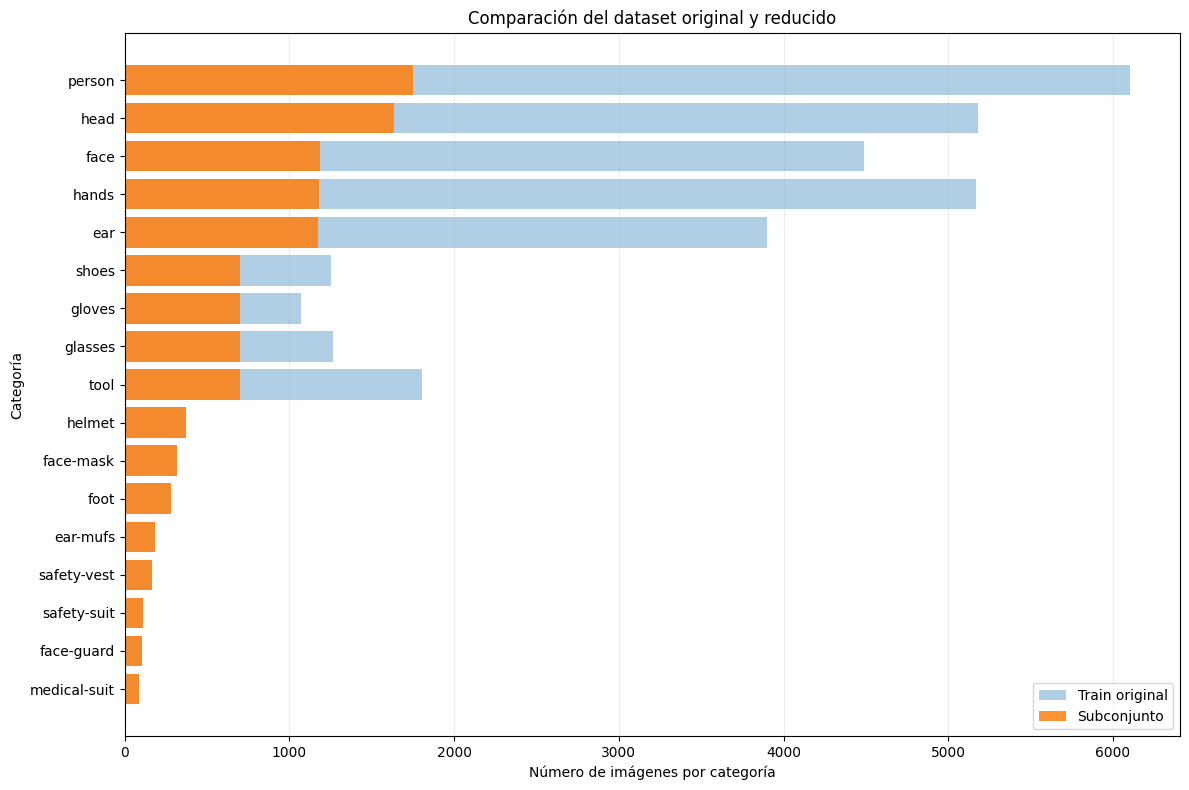

In [10]:

import random
import math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Parámetros de selección
MAX_IMAGENES_TRAIN = 2000
META_MAYORITARIAS = 700

assert MAX_IMAGENES_TRAIN >= len(seleccion_obligatoria), (
    "El límite es menor que la selección obligatoria."
)

# Identificamos las clases mayoritarias
ids_mayoritarias = set(CLASES) - ids_minoritarias

# Comenzamos con las imágenes obligatorias
seleccion_final = set(seleccion_obligatoria)

# Calculamos la cobertura actual
conteo_actual = Counter()

for nombre in seleccion_final:
    for clase_id in clases_por_imagen[nombre]:
        conteo_actual[clase_id] += 1

# Imágenes de entrenamiento que todavía podemos utilizar
candidatos = sorted(train - seleccion_final)

# Orden aleatorio reproducible para resolver empates
rng = random.Random(SEMILLA)
rng.shuffle(candidatos)

# Peso fijo: prioriza categorías menos frecuentes
pesos = {
    clase_id: 1 / math.sqrt(conteo_train[clase_id])
    for clase_id in ids_mayoritarias
}

def calcular_puntaje(nombre):
    """
    Evalúa cuánto contribuye una imagen a mejorar
    la cobertura de las clases mayoritarias.
    """

    puntaje = 0.0

    for clase_id in clases_por_imagen[nombre]:

        if clase_id not in ids_mayoritarias:
            continue

        deficit = max(
            0,
            META_MAYORITARIAS - conteo_actual[clase_id]
        )

        if deficit > 0:
            puntaje += (
                deficit / META_MAYORITARIAS
            ) * pesos[clase_id]

    return puntaje


# Selección iterativa balanceada
while len(seleccion_final) < MAX_IMAGENES_TRAIN:

    # Verificar si ya cumplimos todas las metas
    pendientes = [
        clase_id
        for clase_id in ids_mayoritarias
        if conteo_actual[clase_id] < META_MAYORITARIAS
    ]

    if not pendientes:
        break

    # Buscar la imagen con mayor aporte
    mejor_imagen = None
    mejor_puntaje = 0.0

    for nombre in candidatos:
        puntaje = calcular_puntaje(nombre)

        if puntaje > mejor_puntaje:
            mejor_puntaje = puntaje
            mejor_imagen = nombre

    # Detener si ninguna imagen mejora la cobertura
    if mejor_imagen is None:
        break

    # Incorporamos la imagen seleccionada
    seleccion_final.add(mejor_imagen)
    candidatos.remove(mejor_imagen)

    # Actualizamos todas las categorías de esa imagen
    for clase_id in clases_por_imagen[mejor_imagen]:
        conteo_actual[clase_id] += 1


# Resumen de resultados
df_balanceado = pd.DataFrame([
    {
        "Clase": nombre,
        "Tipo": (
            "Minoritaria"
            if clase_id in ids_minoritarias
            else "Mayoritaria"
        ),
        "Train original": conteo_train[clase_id],
        "Antes": conteo_obligatorio[clase_id],
        "Después": conteo_actual[clase_id],
        "Cobertura (%)": round(
            100 * conteo_actual[clase_id]
            / conteo_train[clase_id], 2
        )
    }
    for clase_id, nombre in CLASES.items()
])

df_balanceado = df_balanceado.sort_values(
    ["Tipo", "Después"],
    ascending=[False, True]
).reset_index(drop=True)

print("RESULTADOS DEL BALANCEO SH17\n")

print("Imágenes originales de entrenamiento:", len(train))
print("Imágenes obligatorias:", len(seleccion_obligatoria))
print("Imágenes adicionales:",
      len(seleccion_final - seleccion_obligatoria))
print("Total seleccionado:", len(seleccion_final))

print(
    "Reducción del entrenamiento:",
    round(100 * (1 - len(seleccion_final) / len(train)), 2),
    "%"
)

print("\nDISTRIBUCIÓN ANTES Y DESPUÉS")
display(df_balanceado)

# Verificaciones finales
minoritarias_conservadas = seleccion_obligatoria.issubset(
    seleccion_final
)

sin_fuga = seleccion_final.isdisjoint(val)

metas_cumplidas = all(
    conteo_actual[clase_id] >= META_MAYORITARIAS
    for clase_id in ids_mayoritarias
)

print("\nVERIFICACIONES")
print("Imágenes obligatorias conservadas:",
      minoritarias_conservadas)
print("Sin imágenes compartidas con validación:", sin_fuga)
print("Metas de categorías mayoritarias alcanzadas:",
      metas_cumplidas)

assert minoritarias_conservadas
assert sin_fuga
assert len(seleccion_final) <= MAX_IMAGENES_TRAIN

# Visualización de cobertura
df_grafico = df_balanceado.sort_values("Después")

plt.figure(figsize=(12, 8))

plt.barh(
    df_grafico["Clase"],
    df_grafico["Train original"],
    alpha=0.35,
    label="Train original"
)

plt.barh(
    df_grafico["Clase"],
    df_grafico["Después"],
    alpha=0.85,
    label="Subconjunto"
)

plt.xlabel("Número de imágenes por categoría")
plt.ylabel("Categoría")
plt.title("Comparación del dataset original y reducido")
plt.legend()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()



### 1.10. Exportación del subconjunto reducido para YOLO

Se genera un nuevo dataset utilizando las imágenes seleccionadas durante el proceso de balanceo.

El conjunto reducido contiene 1.801 imágenes de entrenamiento, mientras que las 1.620 imágenes originales de validación se conservan para evaluar el desempeño del modelo.

Durante la exportación se realizan las siguientes operaciones:

- Copiar las imágenes y etiquetas correspondientes a cada conjunto.
- Corregir los pequeños excesos decimales detectados en las cajas delimitadoras, ajustándolas a los límites de la imagen.
- Mantener todas las anotaciones y categorías presentes en cada fotografía.
- Generar la estructura de carpetas requerida por YOLO.
- Crear el archivo `data.yaml`, que define las rutas y las 17 categorías del dataset.
- Registrar las imágenes utilizadas en un manifiesto para facilitar la reproducibilidad.

El dataset original permanece sin modificaciones.

Esta preparación permitirá entrenar posteriormente un modelo YOLO con menos recursos computacionales, conservando las categorías minoritarias y una representación seleccionada de las categorías mayoritarias.


In [11]:

from pathlib import Path
import shutil
import yaml
import pandas as pd
import math

# ==========================================
# 1. CONFIGURACIÓN DE LA CARPETA DE SALIDA
# ==========================================

# Compatible con Google Colab y Kaggle
if Path("/content").exists():
    carpeta_base = Path("/content")
elif Path("/kaggle/working").exists():
    carpeta_base = Path("/kaggle/working")
else:
    carpeta_base = Path.cwd()

SALIDA = carpeta_base / "SH17_reducido"

# Evitar sobrescribir accidentalmente otros resultados
if SALIDA.exists() and any(SALIDA.iterdir()):
    raise FileExistsError(
        f"La carpeta {SALIDA} ya contiene archivos. "
        "Elige otro nombre para evitar sobrescribirlos."
    )

# Verificaciones antes de copiar
assert len(seleccion_final) == 1801
assert len(val) == 1620
assert seleccion_final.isdisjoint(val)

# Cada imagen debe corresponder a una etiqueta única
stems = [imagen.stem for imagen in imagenes]
assert len(stems) == len(set(stems)), (
    "Existen imágenes con el mismo nombre base."
)

# Crear estructura YOLO
for conjunto in ["train", "val"]:
    (SALIDA / "images" / conjunto).mkdir(
        parents=True, exist_ok=True
    )
    (SALIDA / "labels" / conjunto).mkdir(
        parents=True, exist_ok=True
    )


# ==========================================
# 2. FUNCIÓN DE AJUSTE DE ANOTACIONES
# ==========================================

def ajustar_etiqueta_yolo(linea):
    """
    Ajusta una caja al rango [0, 1] y mantiene
    el identificador de clase original.

    Devuelve la anotación y si fue corregida.
    """

    datos = linea.strip().split()

    if len(datos) != 5:
        raise ValueError("Anotación con formato incorrecto")

    clase_id = int(datos[0])
    x, y, w, h = map(float, datos[1:])

    if clase_id not in CLASES:
        raise ValueError("Clase desconocida")

    if not all(math.isfinite(v) for v in (x, y, w, h)):
        raise ValueError("Coordenadas no finitas")

    # Límites originales
    x1 = x - w / 2
    y1 = y - h / 2
    x2 = x + w / 2
    y2 = y + h / 2

    # Solo permitimos la tolerancia ya validada
    tolerancia = 1e-6

    if not (
        -tolerancia <= x1 < x2 <= 1 + tolerancia
        and -tolerancia <= y1 < y2 <= 1 + tolerancia
    ):
        raise ValueError("Caja fuera de tolerancia")

    # Ajuste a los límites reales de la imagen
    x1_cor = max(0.0, min(1.0, x1))
    y1_cor = max(0.0, min(1.0, y1))
    x2_cor = max(0.0, min(1.0, x2))
    y2_cor = max(0.0, min(1.0, y2))

    if x2_cor <= x1_cor or y2_cor <= y1_cor:
        raise ValueError("Caja sin área después del ajuste")

    # Volver al formato YOLO:
    # clase centro_x centro_y ancho alto
    nuevo_x = (x1_cor + x2_cor) / 2
    nuevo_y = (y1_cor + y2_cor) / 2
    nuevo_w = x2_cor - x1_cor
    nuevo_h = y2_cor - y1_cor

    modificada = (
        x1_cor != x1 or y1_cor != y1
        or x2_cor != x2 or y2_cor != y2
    )

    nueva_linea = (
        f"{clase_id} "
        f"{nuevo_x:.10f} {nuevo_y:.10f} "
        f"{nuevo_w:.10f} {nuevo_h:.10f}"
    )

    return nueva_linea, modificada


# ==========================================
# 3. COPIA DE IMÁGENES Y ETIQUETAS
# ==========================================

manifiesto = []
cajas_ajustadas = 0
total_cajas = 0

particiones = {
    "train": seleccion_final,
    "val": val
}

for conjunto, nombres in particiones.items():

    print(f"\nExportando {conjunto}...")

    for nombre in sorted(nombres):

        origen_imagen = imagenes_por_nombre[nombre]
        origen_label = (
            ruta / "labels" / f"{origen_imagen.stem}.txt"
        )

        assert origen_imagen.exists()
        assert origen_label.exists()

        destino_imagen = (
            SALIDA / "images" / conjunto / nombre
        )

        destino_label = (
            SALIDA / "labels" / conjunto
            / f"{origen_imagen.stem}.txt"
        )

        # Copiar imagen
        shutil.copy2(origen_imagen, destino_imagen)

        # Leer todas las anotaciones de la imagen
        lineas_originales = origen_label.read_text(
            encoding="utf-8"
        ).splitlines()

        lineas_corregidas = []
        ajustes_imagen = 0

        for linea in lineas_originales:

            if not linea.strip():
                continue

            nueva_linea, modificada = (
                ajustar_etiqueta_yolo(linea)
            )

            lineas_corregidas.append(nueva_linea)
            ajustes_imagen += int(modificada)

        # Guardar todas las etiquetas corregidas
        destino_label.write_text(
            "\n".join(lineas_corregidas) + "\n",
            encoding="utf-8"
        )

        cajas_ajustadas += ajustes_imagen
        total_cajas += len(lineas_corregidas)

        # Registrar información de trazabilidad
        manifiesto.append({
            "imagen": nombre,
            "particion": conjunto,
            "objetos": len(lineas_corregidas),
            "cajas_ajustadas": ajustes_imagen
        })

    print(
        f"Finalizado: {len(nombres)} imágenes"
    )


# ==========================================
# 4. CREAR ARCHIVO DATA.YAML
# ==========================================

configuracion = {
    "path": str(SALIDA.resolve()),
    "train": "images/train",
    "val": "images/val",
    "nc": len(CLASES),
    "names": CLASES
}

with open(
    SALIDA / "data.yaml", "w", encoding="utf-8"
) as f:
    yaml.safe_dump(
        configuracion,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# Guardar manifiesto de imágenes
df_manifiesto = pd.DataFrame(manifiesto)

df_manifiesto.to_csv(
    SALIDA / "manifiesto.csv",
    index=False
)


# ==========================================
# 5. VERIFICACIÓN DE LA EXPORTACIÓN
# ==========================================

print("\nVERIFICACIÓN DEL DATASET REDUCIDO\n")

for conjunto, nombres in particiones.items():

    n_imagenes = len(list(
        (SALIDA / "images" / conjunto).iterdir()
    ))

    n_etiquetas = len(list(
        (SALIDA / "labels" / conjunto).glob("*.txt")
    ))

    print(f"{conjunto.upper()}")
    print("Imágenes:", n_imagenes)
    print("Etiquetas:", n_etiquetas)

    assert n_imagenes == len(nombres)
    assert n_etiquetas == len(nombres)

# Comprobar YAML
with open(SALIDA / "data.yaml", encoding="utf-8") as f:
    yaml_verificado = yaml.safe_load(f)

assert yaml_verificado["nc"] == 17
assert len(yaml_verificado["names"]) == 17

print("\nRESUMEN GENERAL")
print("Total de imágenes:", len(manifiesto))
print("Total de anotaciones:", total_cajas)
print("Cajas ajustadas:", cajas_ajustadas)
print("Clases:", len(CLASES))

print("\nDataset guardado en:")
print(SALIDA)

print("\nArchivo de configuración:")
print(SALIDA / "data.yaml")

print("\nExportación finalizada correctamente.")



Exportando train...
Finalizado: 1801 imágenes

Exportando val...
Finalizado: 1620 imágenes

VERIFICACIÓN DEL DATASET REDUCIDO

TRAIN
Imágenes: 1801
Etiquetas: 1801
VAL
Imágenes: 1620
Etiquetas: 1620

RESUMEN GENERAL
Total de imágenes: 3421
Total de anotaciones: 38996
Cajas ajustadas: 931
Clases: 17

Dataset guardado en:
/content/SH17_reducido

Archivo de configuración:
/content/SH17_reducido/data.yaml

Exportación finalizada correctamente.



### 1.11. Inspección visual de imágenes y anotaciones

Una vez exportado el subconjunto reducido, se realiza una inspección visual para comprobar la correspondencia entre las imágenes y sus anotaciones YOLO.

Se seleccionan ejemplos de diferentes categorías minoritarias y se representan sus cajas delimitadoras, utilizando las coordenadas normalizadas almacenadas en los archivos de etiquetas.

Esta revisión permite comprobar:

- La correcta asociación entre imágenes y etiquetas.
- La ubicación de las cajas sobre los objetos correspondientes.
- La identificación de las categorías mediante sus nombres.
- La integridad de las anotaciones después de los ajustes decimales.

También se incluirá una imagen que haya requerido corrección de coordenadas, para comprobar visualmente el resultado.

Esta inspección no reemplaza una auditoría exhaustiva del dataset, pero permite detectar posibles errores antes de entrenar el modelo YOLO.


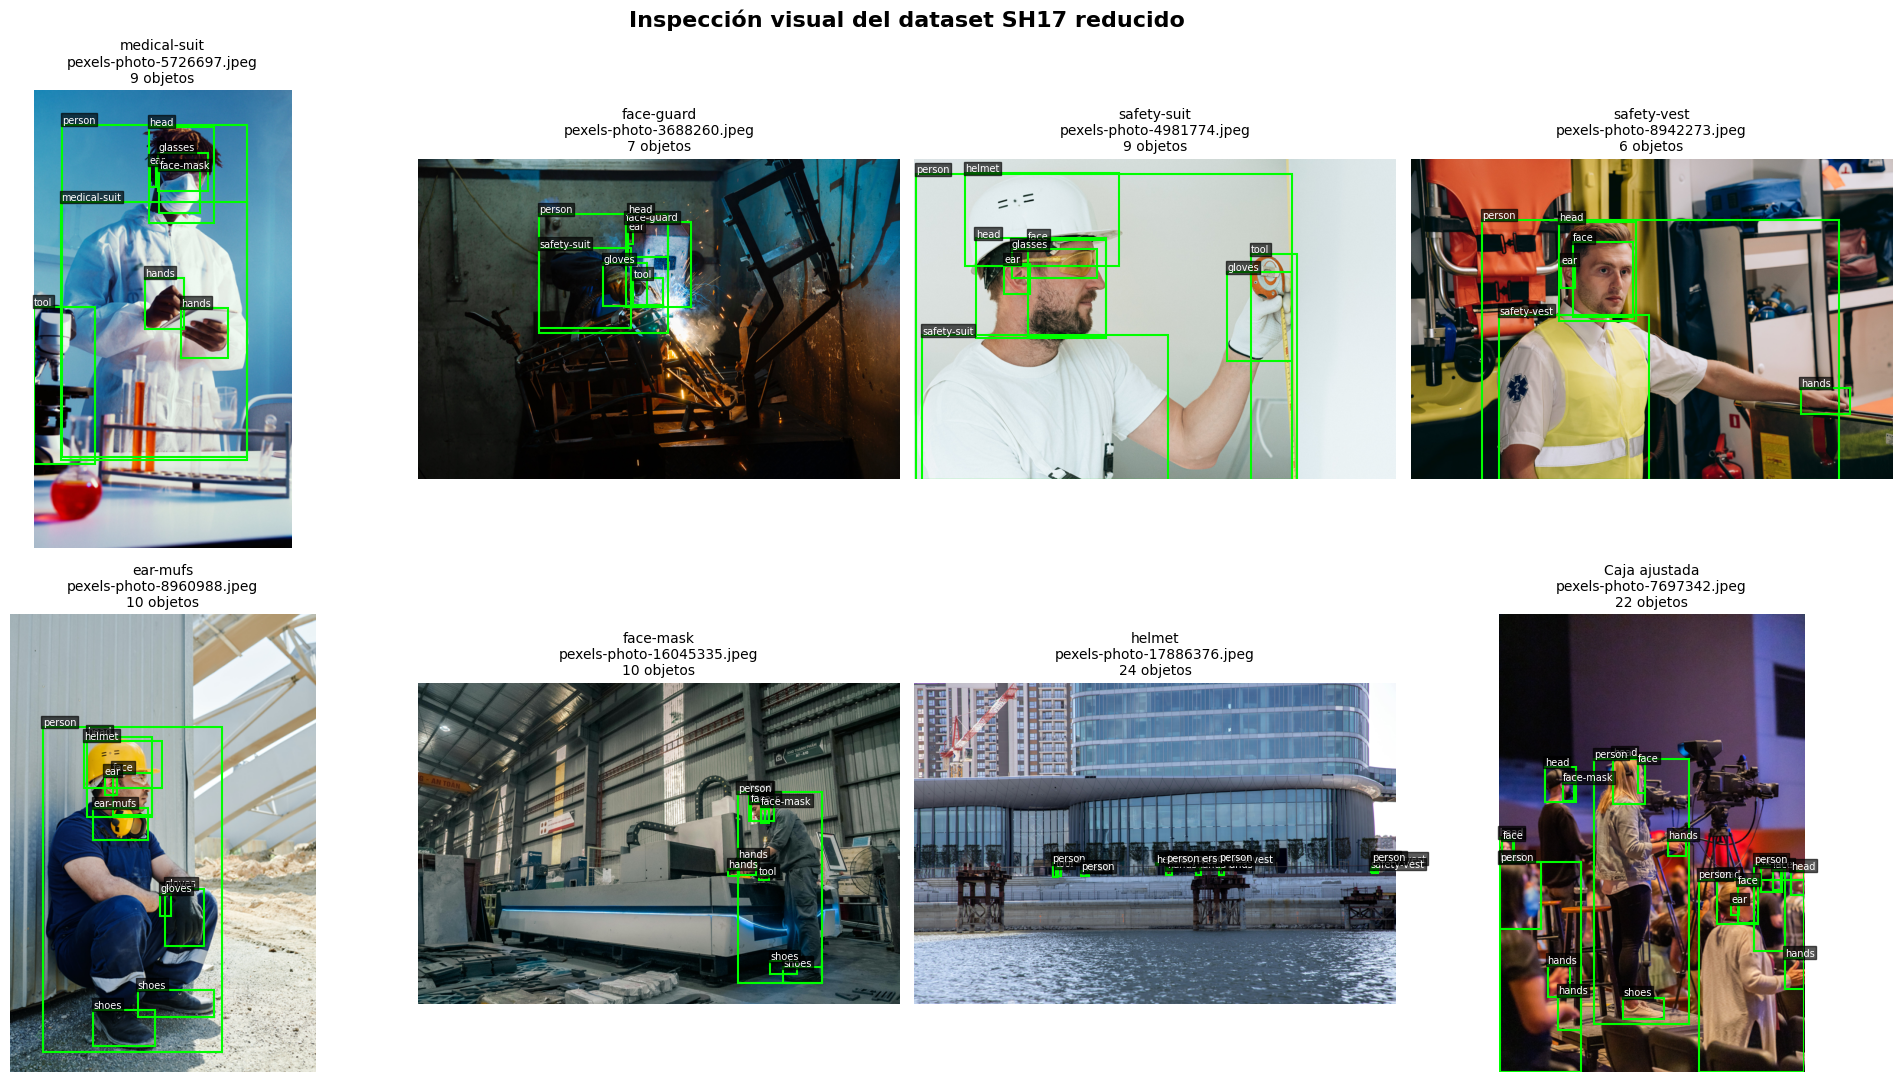

RESUMEN DE INSPECCIÓN

Imágenes registradas: 3421
Anotaciones exportadas: 38996
Cajas ajustadas: 931
Ejemplos visualizados: 8

Manifiesto verificado correctamente.


In [12]:

import random
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle

# ==========================================
# 1. PREPARAR EJEMPLOS
# ==========================================

# Recuperar el manifiesto creado en 1.10
df_manifiesto = pd.read_csv(
    SALIDA / "manifiesto.csv"
)

# Categorías minoritarias a inspeccionar
clases_revisar = [
    13,  # medical-suit
    4,   # face-guard
    15,  # safety-suit
    16,  # safety-vest
    2,   # ear-mufs
    5,   # face-mask
    10   # helmet
]

rng = random.Random(SEMILLA)
ejemplos = []
utilizadas = set()

# Elegir una imagen diferente para cada categoría
for clase_id in clases_revisar:

    candidatos = sorted([
        nombre for nombre in seleccion_final
        if clase_id in clases_por_imagen[nombre]
        and nombre not in utilizadas
    ])

    if candidatos:
        elegido = rng.choice(candidatos)
        ejemplos.append(
            (elegido, CLASES[clase_id])
        )
        utilizadas.add(elegido)

# Agregar una imagen que haya tenido cajas ajustadas
ajustadas = df_manifiesto[
    (df_manifiesto["particion"] == "train") &
    (df_manifiesto["cajas_ajustadas"] > 0)
]

candidatos_ajustados = sorted(
    set(ajustadas["imagen"]) - utilizadas
)

if candidatos_ajustados:
    elegido = rng.choice(candidatos_ajustados)
    ejemplos.append((elegido, "Caja ajustada"))


# ==========================================
# 2. VISUALIZAR IMÁGENES Y CAJAS
# ==========================================

fig, axes = plt.subplots(2, 4, figsize=(20, 11))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for i, (nombre, categoria) in enumerate(ejemplos[:8]):

    ax = axes[i]

    imagen_path = SALIDA / "images" / "train" / nombre
    label_path = (
        SALIDA / "labels" / "train"
        / f"{Path(nombre).stem}.txt"
    )

    # Abrir imagen y reducir tamaño para visualizar
    with Image.open(imagen_path) as img:
        imagen = img.convert("RGB")
        imagen.thumbnail((900, 600))
        ancho, alto = imagen.size

    ax.imshow(imagen)

    # Leer todas las anotaciones de la imagen
    lineas = label_path.read_text(
        encoding="utf-8"
    ).splitlines()

    for linea in lineas:

        if not linea.strip():
            continue

        datos = linea.split()

        clase_id = int(datos[0])
        x, y, w, h = map(float, datos[1:])

        # Convertir coordenadas YOLO a píxeles
        x1 = (x - w / 2) * ancho
        y1 = (y - h / 2) * alto

        ancho_caja = w * ancho
        alto_caja = h * alto

        # Dibujar caja
        rectangulo = Rectangle(
            (x1, y1),
            ancho_caja,
            alto_caja,
            fill=False,
            edgecolor="lime",
            linewidth=1.5
        )

        ax.add_patch(rectangulo)

        # Nombre de la categoría
        ax.text(
            x1,
            max(0, y1 - 3),
            CLASES[clase_id],
            fontsize=7,
            color="white",
            bbox={
                "facecolor": "black",
                "alpha": 0.65,
                "pad": 1
            }
        )

    ax.set_title(
        f"{categoria}\n"
        f"{nombre[:35]}\n"
        f"{len(lineas)} objetos",
        fontsize=10
    )
    ax.axis("off")

plt.suptitle(
    "Inspección visual del dataset SH17 reducido",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ==========================================
# 3. VERIFICACIÓN FINAL DEL MANIFIESTO
# ==========================================

print("RESUMEN DE INSPECCIÓN\n")

print(
    "Imágenes registradas:",
    len(df_manifiesto)
)

print(
    "Anotaciones exportadas:",
    df_manifiesto["objetos"].sum()
)

print(
    "Cajas ajustadas:",
    df_manifiesto["cajas_ajustadas"].sum()
)

print(
    "Ejemplos visualizados:",
    len(ejemplos)
)

assert len(df_manifiesto) == 3421
assert df_manifiesto["objetos"].sum() == 38996
assert df_manifiesto["cajas_ajustadas"].sum() == 931

print("\nManifiesto verificado correctamente.")



## 2. Entrenamiento y evaluación del modelo YOLO

### 2.1. Creación de un conjunto de prueba independiente

Antes de entrenar el modelo, se establece una división entre entrenamiento, validación y prueba para evaluar su capacidad de generalización.

Se conservarán las 1.801 imágenes seleccionadas para entrenamiento y se dividirán las 1.620 imágenes originales de validación en dos conjuntos independientes.

Para realizar esta separación se utilizará una técnica de estratificación multietiqueta, que considera simultáneamente las distintas categorías presentes en cada imagen.

El objetivo es mantener una representación similar de las 17 clases tanto en validación como en prueba.

El conjunto de prueba se reservará para la evaluación final y la comparación con el método base, evitando utilizarlo para seleccionar hiperparámetros o ajustar el modelo.

La división será reproducible mediante una semilla aleatoria fija y se actualizará el archivo `data.yaml` con las rutas correspondientes.


In [13]:

# Instalación de herramienta de estratificación multietiqueta
%pip -q install iterative-stratification

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from pathlib import Path
import numpy as np
import pandas as pd
import shutil
import yaml

# ==========================================
# 1. CONFIGURACIÓN
# ==========================================

DATASET = Path("/content/SH17_reducido")
SEMILLA = 2026

imagenes_val = DATASET / "images" / "val"
etiquetas_val = DATASET / "labels" / "val"

imagenes_test = DATASET / "images" / "test"
etiquetas_test = DATASET / "labels" / "test"

assert imagenes_val.exists()
assert etiquetas_val.exists()

# Evitar ejecutar dos veces sobre una división existente
assert not imagenes_test.exists(), (
    "Ya existe la carpeta test. "
    "No repitas la división sin revisar el dataset."
)

# ==========================================
# 2. LEER IMÁGENES Y CLASES
# ==========================================

nombres = sorted([
    p.name for p in imagenes_val.iterdir()
    if p.is_file()
])

assert len(nombres) == 1620, (
    f"Se esperaban 1620 imágenes y se encontraron {len(nombres)}."
)

# Matriz multietiqueta:
# filas = imágenes, columnas = 17 clases
Y = np.zeros((len(nombres), len(CLASES)), dtype=int)

for i, nombre in enumerate(nombres):

    archivo = etiquetas_val / f"{Path(nombre).stem}.txt"
    assert archivo.exists(), f"Falta etiqueta: {nombre}"

    for linea in archivo.read_text(
        encoding="utf-8"
    ).splitlines():

        if not linea.strip():
            continue

        clase_id = int(linea.split()[0])
        Y[i, clase_id] = 1

# ==========================================
# 3. DIVISIÓN MULTIETIQUETA
# ==========================================

divisor = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEMILLA
)

indices_val, indices_test = next(
    divisor.split(np.zeros((len(nombres), 1)), Y)
)

nombres_val_final = {
    nombres[i] for i in indices_val
}

nombres_test_final = {
    nombres[i] for i in indices_test
}

# ==========================================
# 4. VERIFICAR ANTES DE MODIFICAR CARPETAS
# ==========================================

assert len(nombres_val_final & nombres_test_final) == 0
assert nombres_val_final | nombres_test_final == set(nombres)

# Confirmar que no existen archivos faltantes
for nombre in nombres_test_final:

    assert (imagenes_val / nombre).exists()
    assert (
        etiquetas_val / f"{Path(nombre).stem}.txt"
    ).exists()

# ==========================================
# 5. MOVER IMÁGENES A TEST
# ==========================================

imagenes_test.mkdir(parents=True, exist_ok=False)
etiquetas_test.mkdir(parents=True, exist_ok=False)

for nombre in sorted(nombres_test_final):

    nombre_label = f"{Path(nombre).stem}.txt"

    shutil.move(
        str(imagenes_val / nombre),
        str(imagenes_test / nombre)
    )

    shutil.move(
        str(etiquetas_val / nombre_label),
        str(etiquetas_test / nombre_label)
    )

# ==========================================
# 6. ACTUALIZAR DATA.YAML
# ==========================================

archivo_yaml = DATASET / "data.yaml"

with open(archivo_yaml, encoding="utf-8") as f:
    configuracion = yaml.safe_load(f)

configuracion["test"] = "images/test"

with open(archivo_yaml, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        configuracion,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# Actualizar manifiesto de trazabilidad
archivo_manifiesto = DATASET / "manifiesto.csv"
df_manifiesto = pd.read_csv(archivo_manifiesto)

df_manifiesto.loc[
    df_manifiesto["imagen"].isin(nombres_test_final),
    "particion"
] = "test"

df_manifiesto.to_csv(
    archivo_manifiesto,
    index=False
)

# ==========================================
# 7. VERIFICACIÓN FINAL
# ==========================================

print("DIVISIÓN FINAL DEL DATASET SH17\n")

for conjunto in ["train", "val", "test"]:

    carpeta_img = DATASET / "images" / conjunto
    carpeta_lbl = DATASET / "labels" / conjunto

    cantidad_imagenes = len(list(carpeta_img.iterdir()))
    cantidad_etiquetas = len(list(carpeta_lbl.glob("*.txt")))

    print(
        f"{conjunto.upper()}: "
        f"{cantidad_imagenes} imágenes, "
        f"{cantidad_etiquetas} etiquetas"
    )

    assert cantidad_imagenes == cantidad_etiquetas

# Distribución por clase
df_distribucion = pd.DataFrame([
    {
        "Clase": CLASES[clase_id],
        "Val": int(Y[indices_val, clase_id].sum()),
        "Test": int(Y[indices_test, clase_id].sum())
    }
    for clase_id in CLASES
])

print("\nDISTRIBUCIÓN POR CATEGORÍA")
display(df_distribucion)

print("\nVERIFICACIONES")
print("Sin imágenes compartidas:",
      nombres_val_final.isdisjoint(nombres_test_final))

print("Archivo YAML actualizado:",
      archivo_yaml.exists())

print("\nDataset preparado para entrenamiento y evaluación.")


DIVISIÓN FINAL DEL DATASET SH17

TRAIN: 1801 imágenes, 1801 etiquetas
VAL: 810 imágenes, 810 etiquetas
TEST: 810 imágenes, 810 etiquetas

DISTRIBUCIÓN POR CATEGORÍA


,Clase,Val,Test
0,person,758,757
1,ear,494,493
2,ear-mufs,19,19
3,face,577,578
4,face-guard,12,11
5,face-mask,37,38
6,foot,32,32
7,tool,228,227
8,glasses,162,161
9,gloves,127,127



VERIFICACIONES
Sin imágenes compartidas: True
Archivo YAML actualizado: True

Dataset preparado para entrenamiento y evaluación.



### 2.2. Configuración del entorno y carga del modelo YOLOv8

Se configura el entorno de ejecución para entrenar un modelo de detección de objetos utilizando YOLOv8, implementado mediante la biblioteca Ultralytics.

Se utilizará la versión YOLOv8n (Nano), que corresponde a una arquitectura liviana y permite reducir la demanda de recursos computacionales durante el entrenamiento.

El modelo comenzará con pesos preentrenados, utilizando transferencia de aprendizaje para adaptarse a las 17 categorías del dataset SH17.

En esta etapa se realizarán las siguientes operaciones:

- Instalar la biblioteca Ultralytics.
- Verificar la disponibilidad de una GPU mediante PyTorch.
- Comprobar la estructura del dataset y el archivo `data.yaml`.
- Cargar el modelo YOLOv8n preentrenado.

Estas comprobaciones permitirán asegurar que el entorno esté preparado antes de iniciar el entrenamiento del identificador de EPP.


In [14]:

# ==========================================
# 1. INSTALACIÓN DE ULTRALYTICS
# ==========================================

%pip -q install ultralytics

# ==========================================
# 2. IMPORTACIÓN DE LIBRERÍAS
# ==========================================

import torch
import ultralytics
import yaml

from pathlib import Path
from ultralytics import YOLO

# ==========================================
# 3. VERIFICACIÓN DE GPU
# ==========================================

print("CONFIGURACIÓN DEL ENTORNO\n")

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

gpu_disponible = torch.cuda.is_available()

print("GPU disponible:", gpu_disponible)

if gpu_disponible:

    nombre_gpu = torch.cuda.get_device_name(0)

    memoria_gpu = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU:", nombre_gpu)
    print("Memoria GPU:", round(memoria_gpu, 2), "GB")

else:
    print("\nATENCIÓN: No se detectó una GPU.")
    print("Activa GPU T4 en la configuración de Colab.")

# ==========================================
# 4. VERIFICACIÓN DEL DATASET
# ==========================================

DATASET = Path("/content/SH17_reducido")
ARCHIVO_YAML = DATASET / "data.yaml"

assert ARCHIVO_YAML.exists(), (
    "No se encontró data.yaml. "
    "Verifica que el dataset siga en Colab."
)

with open(ARCHIVO_YAML, encoding="utf-8") as f:
    configuracion = yaml.safe_load(f)

assert configuracion["nc"] == 17
assert len(configuracion["names"]) == 17

print("\nVERIFICACIÓN DEL DATASET")

for conjunto in ["train", "val", "test"]:

    carpeta = DATASET / "images" / conjunto
    carpeta_etiquetas = DATASET / "labels" / conjunto

    assert carpeta.exists(), f"Falta: {carpeta}"
    assert carpeta_etiquetas.exists()

    cantidad = len([
        archivo for archivo in carpeta.iterdir()
        if archivo.is_file()
    ])

    cantidad_labels = len(list(
        carpeta_etiquetas.glob("*.txt")
    ))

    assert cantidad == cantidad_labels

    print(
        f"{conjunto.upper()}: "
        f"{cantidad} imágenes | "
        f"{cantidad_labels} etiquetas"
    )

# ==========================================
# 5. CARGA DEL MODELO PREENTRENADO
# ==========================================

modelo = YOLO("yolov8n.pt")

print("\nMODELO CARGADO CORRECTAMENTE")

print("Arquitectura: YOLOv8 Nano")
print("Tarea:", modelo.task)
print("Clases del dataset:", configuracion["nc"])

print("\nEntorno preparado para el entrenamiento.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
CONFIGURACIÓN DEL ENTORNO

PyTorch: 2.14.1+cu130
Ultralytics: 8.4.208
GPU disponible: True
GPU: Tesla T4
Memoria GPU: 14.56 GB

VERIFICACIÓN DEL DATASET
TRAIN: 1801 imágenes | 1801 etiquetas
VAL: 810 imágenes | 810 etiquetas
TEST: 810 imágenes | 810 etiquetas

MODELO CARGADO CORRECTAMENTE
Arquitectura: YOLOv8 Nano
Tarea: detect
Clases del dataset: 17

Entorno preparado para el entrenamiento.



### 2.3. Entrenamiento inicial del modelo YOLOv8n

Se realiza el primer entrenamiento del modelo YOLOv8n utilizando el subconjunto reducido del dataset SH17.

El modelo se inicializa con pesos preentrenados y se adapta mediante transferencia de aprendizaje a las 17 categorías presentes en el conjunto de datos.

Se establece un máximo de 50 épocas, imágenes de 640 × 640 píxeles y un tamaño de lote de 16 imágenes. Además, se utiliza detención temprana para interrumpir el entrenamiento si las métricas de validación dejan de mejorar durante 15 épocas consecutivas.

Durante el entrenamiento, YOLO ajustará sus parámetros utilizando las 1.801 imágenes de entrenamiento y evaluará su desempeño con las 810 imágenes de validación.

Las 810 imágenes de prueba se mantendrán reservadas para la evaluación final y la comparación con un método base sencillo.

Se registrarán las pérdidas, métricas y gráficos del entrenamiento, además de guardar los pesos del mejor modelo obtenido.

El objetivo de esta etapa es establecer un primer modelo de referencia que posteriormente permita evaluar mejoras y analizar su capacidad para reconocer elementos de protección personal.


In [ ]:

# ==========================================
# INSTALACIÓN DE ULTRALYTICS
# ==========================================

%pip -q install ultralytics

# ==========================================
# 2. IMPORTACIÓN DE LIBRERÍAS
# ==========================================

import torch
import ultralytics
import yaml

from pathlib import Path
from ultralytics import YOLO

# ==========================================
# 3. VERIFICACIÓN DE GPU
# ==========================================

print("CONFIGURACIÓN DEL ENTORNO\n")

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

gpu_disponible = torch.cuda.is_available()

print("GPU disponible:", gpu_disponible)

if gpu_disponible:

    nombre_gpu = torch.cuda.get_device_name(0)

    memoria_gpu = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU:", nombre_gpu)
    print("Memoria GPU:", round(memoria_gpu, 2), "GB")

else:
    print("\nATENCIÓN: No se detectó una GPU.")
    print("Activa GPU T4 en la configuración de Colab.")

# ==========================================
# 4. VERIFICACIÓN DEL DATASET
# ==========================================

DATASET = Path("/content/SH17_reducido")
ARCHIVO_YAML = DATASET / "data.yaml"

assert ARCHIVO_YAML.exists(), (
    "No se encontró data.yaml. "
    "Verifica que el dataset siga en Colab."
)

with open(ARCHIVO_YAML, encoding="utf-8") as f:
    configuracion = yaml.safe_load(f)

assert configuracion["nc"] == 17
assert len(configuracion["names"]) == 17

print("\nVERIFICACIÓN DEL DATASET")

for conjunto in ["train", "val", "test"]:

    carpeta = DATASET / "images" / conjunto
    carpeta_etiquetas = DATASET / "labels" / conjunto

    assert carpeta.exists(), f"Falta: {carpeta}"
    assert carpeta_etiquetas.exists()

    cantidad = len([
        archivo for archivo in carpeta.iterdir()
        if archivo.is_file()
    ])

    cantidad_labels = len(list(
        carpeta_etiquetas.glob("*.txt")
    ))

    assert cantidad == cantidad_labels

    print(
        f"{conjunto.upper()}: "
        f"{cantidad} imágenes | "
        f"{cantidad_labels} etiquetas"
    )

# ==========================================
# 5. CARGA DEL MODELO PREENTRENADO
# ==========================================

modelo = YOLO("yolov8n.pt")

print("\nMODELO CARGADO CORRECTAMENTE")

print("Arquitectura: YOLOv8 Nano")
print("Tarea:", modelo.task)
print("Clases del dataset:", configuracion["nc"])

print("\nEntorno preparado para el entrenamiento.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
CONFIGURACIÓN DEL ENTORNO

PyTorch: 2.14.1+cu130
Ultralytics: 8.4.207
GPU disponible: True
GPU: Tesla T4
Memoria GPU: 14.56 GB

VERIFICACIÓN DEL DATASET
TRAIN: 1801 imágenes | 1801 etiquetas
VAL: 810 imágenes | 810 etiquetas
TEST: 810 imágenes | 810 etiquetas

MODELO CARGADO CORRECTAMENTE
Arquitectura: YOLOv8 Nano
Tarea: detect
Clases del dataset: 17

Entorno preparado para el entrenamiento.


In [ ]:

# ==========================================
# 1. CONECTAR GOOGLE DRIVE
# ==========================================

from google.colab import drive
from pathlib import Path
from ultralytics import YOLO
import torch

drive.mount("/content/drive")

# Carpeta donde se guardarán los entrenamientos
CARPETA_RESULTADOS = Path(
    "/content/drive/MyDrive/Certamen2_IA/Entrenamientos_YOLO"
)

CARPETA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 2. CONFIGURAR ENTRENAMIENTO
# ==========================================

DATASET = Path("/content/SH17_reducido")
ARCHIVO_YAML = DATASET / "data.yaml"

assert ARCHIVO_YAML.exists(), "No se encontró data.yaml."
assert torch.cuda.is_available(), "Se requiere GPU."

print("ENTRENAMIENTO INICIAL YOLOv8n\n")
print("Dataset:", ARCHIVO_YAML)
print("GPU:", torch.cuda.get_device_name(0))
print("Épocas máximas:", 50)
print("Batch size:", 16)
print("Tamaño de imagen:", 640)

# Cargar nuevamente los pesos originales
# para garantizar un experimento inicial reproducible
modelo = YOLO("yolov8n.pt")

# ==========================================
# 3. ENTRENAR EL MODELO
# ==========================================

resultados_entrenamiento = modelo.train(
    data=str(ARCHIVO_YAML),

    # Configuración principal
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,

    # Hardware
    device=0,
    workers=2,
    amp=True,
    cache=False,

    # Reproducibilidad
    seed=2026,
    deterministic=True,

    # Guardado de resultados
    project=str(CARPETA_RESULTADOS),
    name="YOLOv8n_SH17_Base",
    exist_ok=False,
    save=True,
    save_period=10,
    plots=True,

    # Información de entrenamiento
    verbose=True
)

# ==========================================
# 4. IDENTIFICAR RESULTADOS GUARDADOS
# ==========================================

CARPETA_ENTRENAMIENTO = Path(modelo.trainer.save_dir)

PESOS_MEJORES = (
    CARPETA_ENTRENAMIENTO / "weights" / "best.pt"
)

PESOS_FINALES = (
    CARPETA_ENTRENAMIENTO / "weights" / "last.pt"
)

print("\nENTRENAMIENTO FINALIZADO")

print("\nCarpeta de resultados:")
print(CARPETA_ENTRENAMIENTO)

print("\nMejor modelo:")
print(PESOS_MEJORES)

print("\nÚltimo checkpoint:")
print(PESOS_FINALES)

print("\nVERIFICACIONES")
print("Mejor modelo guardado:", PESOS_MEJORES.exists())
print("Último checkpoint guardado:", PESOS_FINALES.exists())
print(
    "Resultados CSV:",
    (CARPETA_ENTRENAMIENTO / "results.csv").exists()
)


Mounted at /content/drive
ENTRENAMIENTO INICIAL YOLOv8n

Dataset: /content/SH17_reducido/data.yaml
GPU: Tesla T4
Épocas máximas: 50
Batch size: 16
Tamaño de imagen: 640
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SH17_reducido/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_


### 2.4. Recuperación y validación del modelo YOLOv8n

El entrenamiento inicial de YOLOv8n se interrumpió debido a la carga computacional, después de completar 22 épocas de las 50 planificadas.

Con ello, se decidió recuperar los pesos guardados y continuar con la evaluación del modelo obtenido.

El historial de entrenamiento muestra que el modelo alcanzó, en la época 22, una precisión de 61,05 %, un recall de 48,01 %, un mAP50 de 50,70 % y un mAP50-95 de 31,24 % sobre el conjunto de validación.

En esta etapa se cargará el mejor checkpoint disponible y se evaluará nuevamente sobre el conjunto de validación, identificando su desempeño global y por categoría. Con ello, el conjunto de prueba independiente permanecerá reservado para la evaluación final del modelo y su comparación con un método base.


In [ ]:
%pip -q install ultralytics

In [ ]:

from pathlib import Path
from ultralytics import YOLO
from google.colab import drive
import torch

# ==========================================
# 1. SELECCIONAR DISPOSITIVO
# ==========================================

DISPOSITIVO = "cuda:0" if torch.cuda.is_available() else "cpu"

print("CONFIGURACIÓN DEL ENTORNO\n")
print("Dispositivo seleccionado:", DISPOSITIVO)

if DISPOSITIVO == "cpu":
    print("GPU no disponible. Se utilizará CPU.")
    print("No es necesario volver a entrenar el modelo.")

# ==========================================
# 2. RECUPERAR CHECKPOINT
# ==========================================

CARPETA_PESOS = Path(
    "/content/drive/MyDrive/Certamen2_IA/"
    "Entrenamientos_YOLO/"
    "YOLOv8n_SH17_Base/weights"
)

PESOS_MODELO = CARPETA_PESOS / "best.pt"

if not PESOS_MODELO.exists():
    PESOS_MODELO = CARPETA_PESOS / "last.pt"

assert PESOS_MODELO.exists(), (
    "No se encontró best.pt ni last.pt en Google Drive."
)

print("\nCheckpoint encontrado:")
print(PESOS_MODELO)

# ==========================================
# 3. VERIFICAR DATASET
# ==========================================

ARCHIVO_YAML = Path(
    "/content/SH17_reducido/data.yaml"
)

assert ARCHIVO_YAML.exists(), (
    "No se encontró el dataset reducido."
)

print("\nDataset encontrado:")
print(ARCHIVO_YAML)

# ==========================================
# 4. CARGAR MODELO ENTRENADO
# ==========================================

modelo_recuperado = YOLO(str(PESOS_MODELO))

# Preparar el modelo para CPU o GPU
modelo_recuperado.to(DISPOSITIVO)

print("\nMODELO RECUPERADO CORRECTAMENTE")

print("Arquitectura: YOLOv8n")
print("Tarea:", modelo_recuperado.task)
print("Número de clases:", len(modelo_recuperado.names))
print("Dispositivo:", DISPOSITIVO)

assert len(modelo_recuperado.names) == 17

print("\nModelo preparado para evaluación e inferencia.")


CONFIGURACIÓN DEL ENTORNO

Dispositivo seleccionado: cpu
GPU no disponible. Se utilizará CPU.
No es necesario volver a entrenar el modelo.

Checkpoint encontrado:
/content/drive/MyDrive/Certamen2_IA/Entrenamientos_YOLO/YOLOv8n_SH17_Base/weights/best.pt

Dataset encontrado:
/content/SH17_reducido/data.yaml

MODELO RECUPERADO CORRECTAMENTE
Arquitectura: YOLOv8n
Tarea: detect
Número de clases: 17
Dispositivo: cpu

Modelo preparado para evaluación e inferencia.



### 2.5. Evaluación del modelo recuperado en CPU

Una vez recuperados los mejores pesos del entrenamiento (`best.pt`), se evaluará el desempeño del modelo YOLOv8n sobre las 810 imágenes del conjunto de validación.

Debido a las restricciones de GPU de Google Colab, la evaluación se realizará mediante CPU, conservando la resolución original de 640 × 640 píxeles y utilizando un tamaño de lote reducido.

Se analizarán las siguientes métricas:

- **Precision:** proporción de detecciones positivas que corresponden a objetos correctamente identificados.
- **Recall:** capacidad del modelo para detectar los objetos realmente presentes.
- **F1-score:** indicador que combina Precision y Recall.
- **mAP50:** precisión media de detección considerando un umbral de intersección sobre unión (IoU) de 0,50.
- **mAP50-95:** precisión media calculada sobre diferentes umbrales de IoU.

Además del desempeño global, se analizarán los resultados individuales de las 17 categorías de SH17, prestando especial atención a los elementos de protección personal.

Los resultados se guardarán en Google Drive para su posterior análisis y comparación con un método base.

Esta evaluación no modifica los pesos del modelo ni utiliza el conjunto de prueba independiente.


In [ ]:

import pandas as pd
from pathlib import Path

# ==========================================
# 1. CONFIGURAR EVALUACIÓN
# ==========================================

CARPETA_EVALUACION = Path(
    "/content/drive/MyDrive/Certamen2_IA/Evaluacion_YOLO"
)

CARPETA_EVALUACION.mkdir(
    parents=True,
    exist_ok=True
)

print("EVALUACIÓN DEL MODELO YOLOv8n\n")

print("Modelo:", PESOS_MODELO.name)
print("Dispositivo: CPU")
print("Conjunto: Validación")
print("Imágenes: 810")
print("Resolución: 640 x 640")

# ==========================================
# 2. EVALUAR MODELO EN CPU
# ==========================================

metricas_val = modelo_recuperado.val(
    data=str(ARCHIVO_YAML),
    split="val",
    imgsz=640,
    batch=4,
    device="cpu",
    workers=0,
    half=False,
    plots=False,
    verbose=False,
    project=str(CARPETA_EVALUACION),
    name="Validacion_CPU",
    exist_ok=True
)

# ==========================================
# 3. OBTENER MÉTRICAS GLOBALES
# ==========================================

precision = metricas_val.box.mp
recall = metricas_val.box.mr
map50 = metricas_val.box.map50
map5095 = metricas_val.box.map

print("\nRESULTADOS GLOBALES\n")

print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"mAP50:      {map50:.4f}")
print(f"mAP50-95:   {map5095:.4f}")

df_metricas_globales = pd.DataFrame([{
    "Modelo": PESOS_MODELO.name,
    "Conjunto": "Validación",
    "Precision": precision,
    "Recall": recall,
    "mAP50": map50,
    "mAP50-95": map5095
}])

df_metricas_globales.to_csv(
    CARPETA_EVALUACION / "metricas_globales.csv",
    index=False
)

# ==========================================
# 4. MÉTRICAS POR CATEGORÍA
# ==========================================

filas = []

# Los índices corresponden a las clases evaluadas.
for i, clase_id in enumerate(
    metricas_val.box.ap_class_index
):

    clase_id = int(clase_id)

    filas.append({
        "Clase": CLASES[clase_id],
        "Precision": float(metricas_val.box.p[i]),
        "Recall": float(metricas_val.box.r[i]),
        "F1": float(metricas_val.box.f1[i]),
        "mAP50": float(metricas_val.box.ap50[i]),
        "mAP50-95": float(metricas_val.box.ap[i])
    })

df_metricas_clases = pd.DataFrame(filas)

df_metricas_clases = df_metricas_clases.sort_values(
    "mAP50",
    ascending=False
).reset_index(drop=True)

print("\nMÉTRICAS POR CATEGORÍA")
display(df_metricas_clases.round(4))

# Guardar resultados
df_metricas_clases.to_csv(
    CARPETA_EVALUACION / "metricas_por_clase.csv",
    index=False
)

print("\nEVALUACIÓN FINALIZADA")
print("Resultados guardados en:")
print(CARPETA_EVALUACION)


EVALUACIÓN DEL MODELO YOLOv8n

Modelo: best.pt
Dispositivo: CPU
Conjunto: Validación
Imágenes: 810
Resolución: 640 x 640
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.207 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,136,595 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 906.1±866.3 MB/s, size: 1443.3 KB)
val: Scanning /content/SH17_reducido/labels/val... 810 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 810/810 1.4Kit/s 0.6s
val: New cache created: /content/SH17_reducido/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 203/203 1.8s/it 6:01
                   all        810       7519      0.611      0.479       0.51      0.311
Speed: 1.5ms preprocess, 143.4ms inference, 0.0ms loss, 1.6ms postprocess per image

RESULTADOS GLOBALES

Precision:  0.6109
Re

,Clase,Precision,Recall,F1,mAP50,mAP50-95
0,head,0.8950,0.8600,0.8772,0.8944,0.6450
1,person,0.8083,0.8539,0.8305,0.8732,0.6483
2,face,0.9098,0.8057,0.8546,0.8656,0.5617
3,hands,0.7279,0.6736,0.6997,0.7313,0.4301
4,helmet,0.7330,0.6716,0.7010,0.6928,0.4959
5,medical-suit,0.8332,0.6471,0.7284,0.6754,0.3586
6,ear,0.8560,0.5636,0.6796,0.6571,0.3357
7,face-mask,0.6328,0.5942,0.6129,0.5656,0.3097
8,shoes,0.5665,0.5216,0.5431,0.5236,0.2621
9,safety-vest,0.6593,0.5000,0.5687,0.4906,0.3082



EVALUACIÓN FINALIZADA
Resultados guardados en:
/content/drive/MyDrive/Certamen2_IA/Evaluacion_YOLO




### 2.6. Identificación de EPP mediante inferencia con YOLOv8n

Una vez evaluado el modelo, se implementa una función de inferencia que permite identificar elementos de protección personal presentes en una fotografía.

Se utilizarán los pesos `best.pt`, recuperados del entrenamiento realizado con el dataset SH17.

El sistema permitirá seleccionar una imagen del conjunto de validación o cargar una fotografía externa. Posteriormente, YOLO identificará los objetos reconocidos e informará sus categorías, coordenadas y niveles de confianza.

Los resultados se visualizarán mediante cajas delimitadoras y se organizarán en una tabla. Además, se generará un archivo JSON que podrá utilizarse en las siguientes etapas de automatización e interpretación mediante inteligencia artificial generativa.

La inferencia se ejecutará utilizando CPU, sin necesidad de realizar un nuevo entrenamiento.

Es importante considerar que una detección no constituye una verificación definitiva del cumplimiento de EPP. La ausencia de una detección puede deberse a limitaciones del modelo, obstáculos visuales o condiciones de la fotografía.

Por ello, la determinación de posibles incumplimientos se realizará posteriormente mediante reglas de seguridad por zona y revisión humana.



IMAGEN SELECCIONADA
pexels-photo-13820151.jpeg

RESULTADOS DE LA INFERENCIA
Objetos detectados: 12


,clase_id,clase,confianza,x1,y1,x2,y2
0,0,person,0.8903,1568.80,1364.87,2318.18,3248.47
1,0,person,0.8760,2527.81,1444.53,3189.17,3251.97
2,12,head,0.6264,1818.76,1381.43,2015.86,1622.16
3,16,safety-vest,0.5836,2557.42,1691.37,3165.56,2344.01
4,14,shoes,0.5834,1904.63,3126.57,2177.33,3263.50
5,11,hands,0.5546,2550.20,2428.72,2643.38,2552.80
6,12,head,0.5383,2769.58,1451.67,2975.14,1694.63
7,14,shoes,0.5127,1877.49,3153.16,2143.09,3267.25
8,14,shoes,0.5102,1944.98,3101.59,2210.48,3255.25
9,0,person,0.2795,3620.48,1965.15,3762.83,2212.73


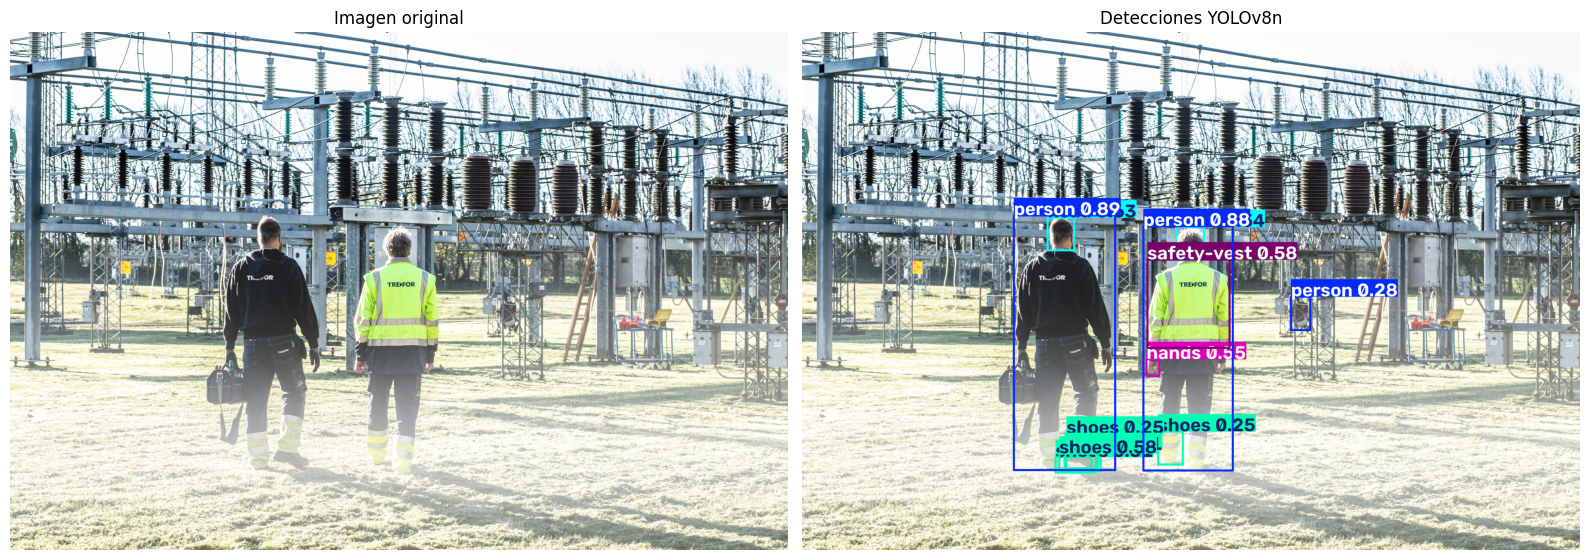


ELEMENTOS DE PROTECCIÓN DETECTADOS
safety-vest: 1
shoes: 5

ARCHIVOS GUARDADOS
Imagen anotada: /content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/pexels-photo-13820151_prediccion.jpg
Resultados JSON: /content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/pexels-photo-13820151_detecciones.json

Inferencia finalizada correctamente.


In [ ]:

from pathlib import Path
from collections import Counter
import random
import json
import cv2
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ==========================================
# 1. CONFIGURACIÓN DE INFERENCIA
# ==========================================

DATASET = Path("/content/SH17_reducido")

# Opciones:
# "validacion" = imagen del dataset
# "subir" = cargar una fotografía externa
MODO_IMAGEN = "validacion"

# Solo para seleccionar un ejemplo de validación
CLASE_EJEMPLO = "safety-vest"

CONFIANZA_MINIMA = 0.25

SALIDA_INFERENCIA = Path(
    "/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO"
)

SALIDA_INFERENCIA.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 2. SELECCIONAR IMAGEN
# ==========================================

if MODO_IMAGEN == "validacion":

    carpeta_img = DATASET / "images" / "val"
    carpeta_lbl = DATASET / "labels" / "val"

    # Identificar el ID de la categoría buscada
    id_objetivo = next(
        clase_id
        for clase_id, nombre in CLASES.items()
        if nombre == CLASE_EJEMPLO
    )

    candidatos = []

    for imagen in sorted(carpeta_img.iterdir()):

        if imagen.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp"
        }:
            continue

        etiqueta = (
            carpeta_lbl / f"{imagen.stem}.txt"
        )

        if not etiqueta.exists():
            continue

        clases_imagen = {
            int(linea.split()[0])
            for linea in etiqueta.read_text(
                encoding="utf-8"
            ).splitlines()
            if linea.strip()
        }

        if id_objetivo in clases_imagen:
            candidatos.append(imagen)

    assert candidatos, (
        "No se encontraron imágenes de la clase elegida."
    )

    rng = random.Random(2026)
    IMAGEN_PRUEBA = rng.choice(candidatos)

elif MODO_IMAGEN == "subir":

    from google.colab import files

    archivos = files.upload()

    assert len(archivos) == 1, (
        "Sube solamente una fotografía."
    )

    nombre = next(iter(archivos))
    IMAGEN_PRUEBA = Path(nombre).resolve()

else:
    raise ValueError("Modo de imagen no reconocido.")

assert IMAGEN_PRUEBA.exists()

print("IMAGEN SELECCIONADA")
print(IMAGEN_PRUEBA.name)

# ==========================================
# 3. EJECUTAR YOLO EN CPU
# ==========================================

resultados = modelo_recuperado.predict(
    source=str(IMAGEN_PRUEBA),
    imgsz=640,
    conf=CONFIANZA_MINIMA,
    device="cpu",
    verbose=False
)

resultado = resultados[0]

# ==========================================
# 4. EXTRAER DETECCIONES
# ==========================================

detecciones = []

for caja in resultado.boxes:

    clase_id = int(caja.cls.item())
    confianza = float(caja.conf.item())

    x1, y1, x2, y2 = (
        caja.xyxy[0].cpu().tolist()
    )

    detecciones.append({
        "clase_id": clase_id,
        "clase": resultado.names[clase_id],
        "confianza": round(confianza, 4),
        "x1": round(x1, 2),
        "y1": round(y1, 2),
        "x2": round(x2, 2),
        "y2": round(y2, 2)
    })

df_detecciones = pd.DataFrame(detecciones)

print("\nRESULTADOS DE LA INFERENCIA")
print("Objetos detectados:", len(detecciones))

if not df_detecciones.empty:

    display(
        df_detecciones.sort_values(
            "confianza",
            ascending=False
        ).reset_index(drop=True)
    )

else:
    print(
        "No se encontraron detecciones con "
        "el umbral de confianza establecido."
    )

# ==========================================
# 5. VISUALIZACIÓN
# ==========================================

imagen_original = cv2.imread(
    str(IMAGEN_PRUEBA)
)

assert imagen_original is not None, (
    "No se pudo abrir la imagen seleccionada."
)

imagen_anotada = resultado.plot()

fig, axes = plt.subplots(
    1, 2, figsize=(16, 7)
)

axes[0].imshow(
    cv2.cvtColor(
        imagen_original,
        cv2.COLOR_BGR2RGB
    )
)

axes[0].set_title("Imagen original")
axes[0].axis("off")

axes[1].imshow(
    cv2.cvtColor(
        imagen_anotada,
        cv2.COLOR_BGR2RGB
    )
)

axes[1].set_title("Detecciones YOLOv8n")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 6. IDENTIFICAR DETECCIONES DE EPP
# ==========================================

CATEGORIAS_EPP = {
    "helmet",
    "safety-vest",
    "gloves",
    "glasses",
    "face-mask",
    "ear-mufs",
    "face-guard",
    "safety-suit",
    "medical-suit",
    "shoes"
}

detecciones_epp = [
    d for d in detecciones
    if d["clase"] in CATEGORIAS_EPP
]

resumen_epp = Counter(
    d["clase"] for d in detecciones_epp
)

print("\nELEMENTOS DE PROTECCIÓN DETECTADOS")

if resumen_epp:

    for clase, cantidad in sorted(
        resumen_epp.items()
    ):
        print(f"{clase}: {cantidad}")

else:
    print("No se detectaron EPP con este umbral.")

# ==========================================
# 7. GENERAR Y GUARDAR JSON
# ==========================================

salida_json = {
    "imagen": IMAGEN_PRUEBA.name,
    "modelo": "YOLOv8n_SH17",
    "checkpoint": PESOS_MODELO.name,
    "confianza_minima": CONFIANZA_MINIMA,
    "total_detecciones": len(detecciones),
    "detecciones": detecciones,
    "resumen_epp": dict(resumen_epp),
    "estado": "pendiente_evaluacion_por_zona"
}

ruta_json = (
    SALIDA_INFERENCIA
    / f"{IMAGEN_PRUEBA.stem}_detecciones.json"
)

ruta_imagen = (
    SALIDA_INFERENCIA
    / f"{IMAGEN_PRUEBA.stem}_prediccion.jpg"
)

with open(
    ruta_json, "w", encoding="utf-8"
) as f:
    json.dump(
        salida_json,
        f,
        indent=4,
        ensure_ascii=False
    )

cv2.imwrite(
    str(ruta_imagen),
    imagen_anotada
)

print("\nARCHIVOS GUARDADOS")

print("Imagen anotada:", ruta_imagen)
print("Resultados JSON:", ruta_json)

print("\nInferencia finalizada correctamente.")



### 2.7. Asociación de elementos de protección personal a cada trabajador

Después de realizar la inferencia, se procesan las detecciones de YOLO para identificar los elementos de protección personal asociados a cada trabajador.

El procedimiento utiliza las coordenadas de las cajas delimitadoras para relacionar espacialmente los EPP detectados con las personas presentes en la imagen.

Para el prototipo inicial se priorizan las categorías `helmet` y `safety-vest`, considerando su importancia en entornos industriales y los resultados obtenidos durante la evaluación del modelo.

Se establece un umbral de confianza del 50 % para identificar las personas principales y del 40 % para considerar las detecciones de EPP.

La asociación se realiza mediante la superposición de las cajas, seleccionando la persona que contiene la mayor proporción de cada EPP detectado.

Los resultados se organizan por trabajador y se almacenan en formato JSON.

Es importante señalar que la falta de detección de un EPP no demuestra necesariamente su ausencia física. Por lo tanto, los elementos no identificados se clasificarán como **no confirmados**, evitando declarar automáticamente un incumplimiento.

Esta etapa prepara la información para su posterior evaluación mediante reglas de seguridad según zona de riesgo y revisión humana.


In [ ]:

import json
import pandas as pd
from pathlib import Path

# ==========================================
# 1. CARGAR RESULTADOS DE YOLO
# ==========================================

ARCHIVO_DETECCIONES = Path(
    "/content/drive/MyDrive/Certamen2_IA/"
    "Inferencia_YOLO/"
    "pexels-photo-13820151_detecciones.json"
)

assert ARCHIVO_DETECCIONES.exists(), (
    "No se encontró el JSON de inferencia."
)

with open(ARCHIVO_DETECCIONES, "r", encoding="utf-8") as f:
    datos_yolo = json.load(f)

detecciones = datos_yolo["detecciones"]

# Umbrales de confianza
UMBRAL_PERSONA = 0.50
UMBRAL_EPP = 0.40

# EPP prioritarios para nuestro prototipo
EPP_OBJETIVO = ["helmet", "safety-vest"]

# ==========================================
# 2. IDENTIFICAR PERSONAS
# ==========================================

personas = [
    d for d in detecciones
    if d["clase"] == "person"
    and d["confianza"] >= UMBRAL_PERSONA
]

# Ordenar de izquierda a derecha
personas = sorted(
    personas,
    key=lambda d: d["x1"]
)

print("PERSONAS IDENTIFICADAS:", len(personas))

# ==========================================
# 3. FUNCIÓN DE ASOCIACIÓN ESPACIAL
# ==========================================

def proporcion_dentro(caja_objeto, caja_persona):
    """
    Calcula qué proporción del área del objeto
    queda dentro de la caja de una persona.
    """

    x1 = max(caja_objeto["x1"], caja_persona["x1"])
    y1 = max(caja_objeto["y1"], caja_persona["y1"])
    x2 = min(caja_objeto["x2"], caja_persona["x2"])
    y2 = min(caja_objeto["y2"], caja_persona["y2"])

    ancho = max(0, x2 - x1)
    alto = max(0, y2 - y1)

    interseccion = ancho * alto

    area_objeto = (
        (caja_objeto["x2"] - caja_objeto["x1"]) *
        (caja_objeto["y2"] - caja_objeto["y1"])
    )

    if area_objeto <= 0:
        return 0.0

    return interseccion / area_objeto


# ==========================================
# 4. ASOCIAR EPP CON CADA PERSONA
# ==========================================

resultados_personas = []

for indice, persona in enumerate(personas, start=1):

    resultados_personas.append({
        "persona_id": indice,
        "confianza_persona": persona["confianza"],
        "bbox": {
            "x1": persona["x1"],
            "y1": persona["y1"],
            "x2": persona["x2"],
            "y2": persona["y2"]
        },
        "epp_detectados": {},
        "epp_no_confirmados": [],
        "estado": "pendiente_revision"
    })

# Considerar solo las detecciones de EPP prioritarios
epp_detectados = [
    d for d in detecciones
    if d["clase"] in EPP_OBJETIVO
    and d["confianza"] >= UMBRAL_EPP
]

epp_sin_asignar = []

for epp in epp_detectados:

    mejor_indice = None
    mejor_superposicion = 0.0

    # Evaluar cada persona
    for i, persona in enumerate(personas):

        superposicion = proporcion_dentro(
            epp, persona
        )

        if superposicion > mejor_superposicion:
            mejor_superposicion = superposicion
            mejor_indice = i

    # Exigir que al menos 60 % del EPP quede
    # dentro de la caja de la persona
    if (
        mejor_indice is not None
        and mejor_superposicion >= 0.60
    ):

        registro = resultados_personas[mejor_indice]
        clase = epp["clase"]

        # Conservar la detección más confiable
        anterior = registro["epp_detectados"].get(clase)

        if (
            anterior is None
            or epp["confianza"] > anterior["confianza"]
        ):
            registro["epp_detectados"][clase] = {
                "confianza": epp["confianza"],
                "superposicion": round(
                    mejor_superposicion, 4
                )
            }

    else:
        epp_sin_asignar.append(epp)


# ==========================================
# 5. IDENTIFICAR EPP NO CONFIRMADOS
# ==========================================

for registro in resultados_personas:

    registro["epp_no_confirmados"] = [
        clase for clase in EPP_OBJETIVO
        if clase not in registro["epp_detectados"]
    ]


# ==========================================
# 6. PRESENTAR RESULTADOS
# ==========================================

filas = []

for registro in resultados_personas:

    filas.append({
        "Trabajador": registro["persona_id"],
        "Confianza persona": registro["confianza_persona"],
        "Casco": (
            "Detectado"
            if "helmet" in registro["epp_detectados"]
            else "No confirmado"
        ),
        "Chaleco": (
            "Detectado"
            if "safety-vest" in registro["epp_detectados"]
            else "No confirmado"
        ),
        "Estado": registro["estado"]
    })

df_trabajadores = pd.DataFrame(filas)

print("\nASOCIACIÓN DE EPP POR TRABAJADOR")
display(df_trabajadores)

print("\nEPP sin asociación confiable:",
      len(epp_sin_asignar))


# ==========================================
# 7. GENERAR JSON ESTRUCTURADO
# ==========================================

resultado_final = {
    "imagen": datos_yolo["imagen"],
    "modelo": datos_yolo["modelo"],
    "etapa": "asociacion_epp_por_persona",
    "cantidad_personas": len(resultados_personas),
    "trabajadores": resultados_personas,
    "epp_sin_asignar": epp_sin_asignar,
    "advertencia": (
        "La ausencia de detección no demuestra "
        "ausencia de EPP. La asociación es "
        "geométrica y requiere revisión humana."
    )
}

ARCHIVO_SALIDA = (
    ARCHIVO_DETECCIONES.parent
    / f"{ARCHIVO_DETECCIONES.stem}_personas.json"
)

with open(ARCHIVO_SALIDA, "w", encoding="utf-8") as f:
    json.dump(
        resultado_final,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nJSON GUARDADO EN:")
print(ARCHIVO_SALIDA)

print("\nAsociación de EPP completada.")


PERSONAS IDENTIFICADAS: 2

ASOCIACIÓN DE EPP POR TRABAJADOR


,Trabajador,Confianza persona,Casco,Chaleco,Estado
0,1,0.8903,No confirmado,No confirmado,pendiente_revision
1,2,0.8760,No confirmado,Detectado,pendiente_revision



EPP sin asociación confiable: 0

JSON GUARDADO EN:
/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/pexels-photo-13820151_detecciones_personas.json

Asociación de EPP completada.



### 2.8. Evaluación del cumplimiento de EPP según zona de riesgo

Se implementa un sistema de reglas en Python para comparar los elementos de protección personal detectados por YOLO con los requisitos establecidos para una zona de trabajo.

La evaluación utiliza los resultados estructurados de la etapa anterior, donde cada trabajador posee un identificador y un registro de los EPP asociados espacialmente.

Para desarrollar el prototipo se establecerán zonas de riesgo de ejemplo, con requisitos configurables de casco y chaleco de seguridad.

El procedimiento realizará las siguientes operaciones:

- Identificar los EPP requeridos según la zona seleccionada.
- Comparar los requisitos con las detecciones individuales de cada trabajador.
- Clasificar cada elemento como "detectado" o "no confirmado".
- Identificar los casos que requieren verificación humana.
- Generar una tabla de resultados y un archivo JSON estructurado.

La ausencia de una detección no se interpretará automáticamente como un incumplimiento, debido a las limitaciones del modelo de visión por computador.

Asimismo, la detección de todos los EPP configurados no garantiza el cumplimiento integral de las normas de seguridad, ya que pueden existir otros requisitos que no son reconocidos por el modelo.

Las reglas utilizadas en esta etapa son ilustrativas y deberán validarse mediante la matriz de riesgos de la organización antes de una implementación real.

Los resultados permitirán alimentar posteriormente un modelo de IA generativa, encargado de interpretar la información y redactar recomendaciones contextualizadas.


In [ ]:

import json
import pandas as pd
from pathlib import Path

# ==========================================
# 1. CARGAR RESULTADOS POR TRABAJADOR
# ==========================================

CARPETA_INFERENCIA = Path(
    "/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO"
)

ARCHIVO_PERSONAS = CARPETA_INFERENCIA / (
    "pexels-photo-13820151_detecciones_personas.json"
)

assert ARCHIVO_PERSONAS.exists(), (
    "No se encontró el JSON del paso 2.7."
)

with open(ARCHIVO_PERSONAS, "r", encoding="utf-8") as f:
    datos_personas = json.load(f)

trabajadores = datos_personas["trabajadores"]

print("RESULTADOS DE DETECCIÓN")
print("Imagen:", datos_personas["imagen"])
print("Trabajadores identificados:", len(trabajadores))


# ==========================================
# 2. DEFINIR REGLAS SEGÚN ZONA
# ==========================================

# Reglas de EJEMPLO para el prototipo académico.
# No equivalen a una matriz de riesgos oficial.

REGLAS_ZONAS = {
    "zona_operativa": {
        "nombre": "Zona operativa industrial",
        "epp_requeridos": [
            "helmet",
            "safety-vest"
        ]
    },

    "zona_transito": {
        "nombre": "Zona de tránsito interno",
        "epp_requeridos": [
            "safety-vest"
        ]
    },

    "zona_casco": {
        "nombre": "Zona con exigencia de casco",
        "epp_requeridos": [
            "helmet"
        ]
    }
}

# Simula la zona seleccionada por el supervisor.
# Puedes cambiarla para probar otras reglas.
ZONA_SELECCIONADA = "zona_operativa"

assert ZONA_SELECCIONADA in REGLAS_ZONAS, (
    "La zona seleccionada no está configurada."
)

regla = REGLAS_ZONAS[ZONA_SELECCIONADA]
epp_requeridos = regla["epp_requeridos"]

print("\nZONA SELECCIONADA")
print(regla["nombre"])

print("\nEPP REQUERIDOS")
for epp in epp_requeridos:
    print("-", epp)


# ==========================================
# 3. EVALUAR A CADA TRABAJADOR
# ==========================================

evaluaciones = []
filas_tabla = []

for trabajador in trabajadores:

    persona_id = trabajador["persona_id"]
    epp_detectados = trabajador["epp_detectados"]

    detalle = {}
    epp_no_confirmados = []

    for epp in epp_requeridos:

        if epp in epp_detectados:

            detalle[epp] = {
                "estado": "detectado",
                "confianza": epp_detectados[epp]["confianza"]
            }

        else:

            detalle[epp] = {
                "estado": "no_confirmado",
                "confianza": None
            }

            epp_no_confirmados.append(epp)

    # La falta de confirmación requiere revisión,
    # pero NO demuestra un incumplimiento.
    if epp_no_confirmados:
        estado_general = "requiere_revision"
    else:
        estado_general = "epp_configurados_detectados"

    evaluacion = {
        "persona_id": persona_id,
        "confianza_persona": trabajador["confianza_persona"],
        "zona": ZONA_SELECCIONADA,
        "epp_evaluados": detalle,
        "epp_no_confirmados": epp_no_confirmados,
        "estado_general": estado_general
    }

    evaluaciones.append(evaluacion)

    # Fila para visualizar resultados
    fila = {
        "Trabajador": persona_id,
        "Zona": regla["nombre"],
        "Estado general": estado_general
    }

    for epp in epp_requeridos:
        fila[epp] = detalle[epp]["estado"]

    filas_tabla.append(fila)


# ==========================================
# 4. PRESENTAR RESULTADOS
# ==========================================

df_evaluacion = pd.DataFrame(filas_tabla)

print("\nEVALUACIÓN POR TRABAJADOR")
display(df_evaluacion)

requieren_revision = sum(
    e["estado_general"] == "requiere_revision"
    for e in evaluaciones
)

sin_pendientes = (
    len(evaluaciones) - requieren_revision
)

print("\nRESUMEN GENERAL")
print("Trabajadores evaluados:", len(evaluaciones))
print("Requieren revisión:", requieren_revision)
print("Con EPP configurados detectados:", sin_pendientes)

if requieren_revision > 0:
    estado_inspeccion = "revision_humana_requerida"
else:
    estado_inspeccion = "sin_pendientes_detectables"

print("Estado de inspección:", estado_inspeccion)


# ==========================================
# 5. GENERAR RESULTADO ESTRUCTURADO
# ==========================================

resultado_evaluacion = {
    "imagen": datos_personas["imagen"],
    "modelo": datos_personas["modelo"],
    "zona_id": ZONA_SELECCIONADA,
    "zona_nombre": regla["nombre"],
    "reglas": {
        "epp_requeridos": epp_requeridos,
        "origen": "configuracion_academica_de_ejemplo"
    },
    "cantidad_trabajadores": len(evaluaciones),
    "evaluaciones": evaluaciones,
    "resumen": {
        "trabajadores_evaluados": len(evaluaciones),
        "requieren_revision": requieren_revision,
        "epp_configurados_detectados": sin_pendientes,
        "estado_inspeccion": estado_inspeccion
    },
    "limitaciones": [
        "No detectar un EPP no confirma su ausencia.",
        "La asociacion espacial puede cometer errores.",
        "Solo se evaluan los EPP configurados.",
        "Las reglas deben validarse para cada instalacion.",
        "La decision final corresponde al prevencionista."
    ]
}

ARCHIVO_EVALUACION = CARPETA_INFERENCIA / (
    Path(datos_personas["imagen"]).stem
    + "_evaluacion_zona.json"
)

with open(
    ARCHIVO_EVALUACION,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        resultado_evaluacion,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nARCHIVO JSON GENERADO")
print(ARCHIVO_EVALUACION)

print("\nEvaluación por zona finalizada.")


RESULTADOS DE DETECCIÓN
Imagen: pexels-photo-13820151.jpeg
Trabajadores identificados: 2

ZONA SELECCIONADA
Zona operativa industrial

EPP REQUERIDOS
- helmet
- safety-vest

EVALUACIÓN POR TRABAJADOR


,Trabajador,Zona,Estado general,helmet,safety-vest
0,1,Zona operativa industrial,requiere_revision,no_confirmado,no_confirmado
1,2,Zona operativa industrial,requiere_revision,no_confirmado,detectado



RESUMEN GENERAL
Trabajadores evaluados: 2
Requieren revisión: 2
Con EPP configurados detectados: 0
Estado de inspección: revision_humana_requerida

ARCHIVO JSON GENERADO
/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/pexels-photo-13820151_evaluacion_zona.json

Evaluación por zona finalizada.



### 2.8.1. Definición de reglas de EPP según riesgos laborales y normativa chilena

Se establece una configuración de seguridad para una zona operativa superficial de una faena minera, utilizando como referencia la normativa chilena sobre elementos de protección personal.

El Decreto Supremo N.º 594, artículo 53, establece obligaciones generales respecto de la entrega y utilización de EPP adecuados a los riesgos laborales. Por su parte, el Decreto Supremo N.º 44, artículos 7 y 13, vincula la identificación de peligros y evaluación de riesgos con la selección de medidas preventivas.

En el contexto minero, el Decreto Supremo N.º 132, artículo 32, establece que las necesidades de EPP deben determinarse según las funciones y riesgos efectivos de los trabajadores.

Para el prototipo académico se define una zona operativa superficial con dos peligros considerados:

- Riesgo de golpes en la cabeza o caída de objetos, para el cual se propone exigir casco.
- Riesgo asociado al tránsito de maquinaria y a la visibilidad de trabajadores, para el cual se propone exigir chaleco de alta visibilidad.

Estas exigencias particulares constituyen una matriz de riesgos simplificada para fines académicos. No representan una obligación universal establecida literalmente por los decretos y deberán ser validadas por un profesional de prevención de riesgos antes de su utilización real.

Las reglas se almacenarán en un archivo JSON independiente, permitiendo posteriormente integrarlas con el flujo de automatización n8n.

La inteligencia artificial generativa no determinará qué EPP son obligatorios, sino que interpretará los resultados obtenidos por Python y formulará recomendaciones basadas en la evaluación realizada.

**Referencias normativas**

- Ministerio de Salud. (1999). *Decreto Supremo N.º 594: Reglamento sobre condiciones sanitarias y ambientales básicas en los lugares de trabajo*. https://www.bcn.cl/leychile/navegar?idNorma=167766
- Ministerio del Trabajo y Previsión Social. (2024). *Decreto N.º 44: Reglamento sobre gestión preventiva de los riesgos laborales*. https://www.bcn.cl/leychile/navegar?idNorma=1205298
- Ministerio de Minería. (2002). *Decreto Supremo N.º 132: Reglamento de seguridad minera*. https://www.bcn.cl/leychile/navegar?idNorma=221064


In [ ]:

import json
from pathlib import Path
import pandas as pd

# ==========================================
# 1. DEFINIR REGLAS DE SEGURIDAD
# ==========================================

REGLAS_ZONAS = {
    "zona_operativa": {
        "nombre": "Zona operativa superficial con tránsito de maquinaria",
        "contexto": "Prototipo académico de faena minera",
        "version": "1.0",
        "validacion_profesional": False,

        "riesgos": [
            {
                "peligro": "Golpes en la cabeza o caída de objetos",
                "epp": "helmet",
                "justificacion": (
                    "Protección propuesta frente a riesgos "
                    "de impacto en la cabeza."
                )
            },
            {
                "peligro": "Tránsito de vehículos y visibilidad",
                "epp": "safety-vest",
                "justificacion": (
                    "Alta visibilidad propuesta para "
                    "trabajadores en zonas de circulación."
                )
            }
        ],

        "epp_requeridos": [
            "helmet",
            "safety-vest"
        ],

        "fundamento_normativo": [
            {
                "norma": "DS 594",
                "articulo": "53",
                "alcance": "EPP adecuados a los riesgos laborales"
            },
            {
                "norma": "DS 44",
                "articulo": "7 y 13",
                "alcance": "Evaluación de riesgos y selección de EPP"
            },
            {
                "norma": "DS 132",
                "articulo": "32",
                "alcance": "EPP según los riesgos efectivos en minería"
            }
        ],

        "origen_regla_especifica": (
            "Matriz de riesgos simplificada propuesta "
            "para el ejercicio académico"
        )
    }
}

# ==========================================
# 2. GUARDAR CONFIGURACIÓN
# ==========================================

CARPETA_INFERENCIA = Path(
    "/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO"
)

CARPETA_INFERENCIA.mkdir(
    parents=True, exist_ok=True
)

ARCHIVO_REGLAS = CARPETA_INFERENCIA / "reglas_epp_zonas.json"

with open(ARCHIVO_REGLAS, "w", encoding="utf-8") as f:
    json.dump(
        REGLAS_ZONAS,
        f,
        indent=4,
        ensure_ascii=False
    )

print("REGLAS GUARDADAS")
print(ARCHIVO_REGLAS)

# ==========================================
# 3. CARGAR DETECCIONES POR PERSONA
# ==========================================

ARCHIVO_PERSONAS = CARPETA_INFERENCIA / (
    "pexels-photo-13820151_detecciones_personas.json"
)

with open(ARCHIVO_PERSONAS, "r", encoding="utf-8") as f:
    datos = json.load(f)

# La zona es seleccionada explícitamente.
ZONA_SELECCIONADA = "zona_operativa"

regla = REGLAS_ZONAS[ZONA_SELECCIONADA]

print("\nZONA:", regla["nombre"])
print("EPP requeridos:", regla["epp_requeridos"])

# ==========================================
# 4. APLICAR REGLAS POR TRABAJADOR
# ==========================================

evaluaciones = []
filas = []

for trabajador in datos["trabajadores"]:

    detectados = trabajador["epp_detectados"]

    confirmados = []
    no_confirmados = []

    for epp in regla["epp_requeridos"]:

        if epp in detectados:
            confirmados.append(epp)
        else:
            no_confirmados.append(epp)

    estado = (
        "detecciones_incompletas_revision_pendiente"
        if no_confirmados
        else "epp_detectados_revision_pendiente"
    )

    evaluaciones.append({
        "persona_id": trabajador["persona_id"],
        "epp_requeridos": regla["epp_requeridos"],
        "epp_detectados": confirmados,
        "epp_no_confirmados": no_confirmados,
        "estado": estado,
        "revision_humana": True
    })

    filas.append({
        "Trabajador": trabajador["persona_id"],
        "EPP requeridos": ", ".join(regla["epp_requeridos"]),
        "Detectados": ", ".join(confirmados) or "Ninguno",
        "No confirmados": ", ".join(no_confirmados) or "Ninguno",
        "Estado": estado
    })

df_resultados = pd.DataFrame(filas)

print("\nEVALUACIÓN SEGÚN REGLAS DOCUMENTADAS")
display(df_resultados)

# ==========================================
# 5. GENERAR RESULTADO FINAL
# ==========================================

resultado = {
    "imagen": datos["imagen"],
    "zona_id": ZONA_SELECCIONADA,
    "zona": regla["nombre"],
    "version_reglas": regla["version"],
    "validacion_profesional_reglas": regla["validacion_profesional"],
    "fundamento_normativo": regla["fundamento_normativo"],
    "origen_regla_especifica": regla["origen_regla_especifica"],
    "riesgos": regla["riesgos"],
    "trabajadores": evaluaciones,
    "cantidad_trabajadores_analizados": len(evaluaciones),
    "cantidad_con_epp_no_confirmados": sum(
        bool(e["epp_no_confirmados"])
        for e in evaluaciones
    ),
    "estado_inspeccion": "revision_humana_requerida",
    "advertencia": (
        "La ausencia de deteccion no demuestra ausencia "
        "fisica del EPP. Las reglas son academicas y "
        "requieren validacion profesional."
    )
}

ARCHIVO_RESULTADO = CARPETA_INFERENCIA / (
    "pexels-photo-13820151_evaluacion_normativa.json"
)

with open(ARCHIVO_RESULTADO, "w", encoding="utf-8") as f:
    json.dump(
        resultado,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nEVALUACIÓN FINALIZADA")
print("Trabajadores:", len(evaluaciones))
print(
    "Con EPP no confirmados:",
    resultado["cantidad_con_epp_no_confirmados"]
)
print("Revisión humana requerida: Sí")

print("\nResultado JSON:")
print(ARCHIVO_RESULTADO)


REGLAS GUARDADAS
/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/reglas_epp_zonas.json

ZONA: Zona operativa superficial con tránsito de maquinaria
EPP requeridos: ['helmet', 'safety-vest']

EVALUACIÓN SEGÚN REGLAS DOCUMENTADAS


,Trabajador,EPP requeridos,Detectados,No confirmados,Estado
0,1,"helmet, safety-vest",Ninguno,"helmet, safety-vest",detecciones_incompletas_revision_pendiente
1,2,"helmet, safety-vest",safety-vest,helmet,detecciones_incompletas_revision_pendiente



EVALUACIÓN FINALIZADA
Trabajadores: 2
Con EPP no confirmados: 2
Revisión humana requerida: Sí

Resultado JSON:
/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/pexels-photo-13820151_evaluacion_normativa.json



### 2.9. Interpretación de resultados mediante IA generativa

Se incorpora un modelo de lenguaje de gran escala (LLM) para interpretar los resultados obtenidos por YOLO y las reglas de seguridad implementadas en Python.

El modelo recibirá exclusivamente información estructurada sobre la zona evaluada, los EPP requeridos, las detecciones asociadas a cada trabajador y los elementos cuya presencia no pudo confirmarse.

Se utilizará Gemini mediante una API protegida, evitando incorporar credenciales directamente en el notebook.

El prompt establecerá restricciones para impedir que el modelo:

- Declare incumplimientos sin evidencia suficiente.
- Confunda un EPP no detectado con un EPP ausente.
- Invente elementos de protección o riesgos no incluidos en la evaluación.
- Modifique los requisitos establecidos por las reglas de Python.
- Reemplace la decisión del profesional de prevención de riesgos.

La respuesta deberá contener obligatoriamente cuatro campos: `diagnostico`, `recomendacion`, `prioridad` y `justificacion`.

El informe generado se validará y guardará en formato JSON para su posterior integración con n8n, donde podrá enviarse mediante Gmail y Telegram y registrarse en un historial de inspecciones.

#### Optimización del consumo de tokens

Para reducir el costo computacional y evitar respuestas innecesariamente extensas, se utiliza un modelo ligero de IA generativa y se simplifica la información enviada.

El LLM recibe únicamente los resultados relevantes de Python: zona evaluada, EPP requeridos, detecciones por trabajador y elementos no confirmados.

La respuesta se limita a un informe breve y estructurado en JSON, con los campos `diagnostico`, `recomendacion`, `prioridad` y `justificacion`.

Se establece un máximo de 350 tokens de salida. La IA no puede modificar las reglas ni declarar incumplimientos confirmados, y la decisión final permanece bajo responsabilidad humana.


In [ ]:

import json
from pathlib import Path
from typing import Literal

from google import genai
from google.genai import types, errors
from google.colab import userdata
from pydantic import BaseModel

# ==========================================
# 1. CONFIGURACIÓN
# ==========================================

API_KEY = userdata.get("GEMINI_API_KEY")
cliente = genai.Client(api_key=API_KEY)

MODELO_LLM = "gemini-3.1-flash-lite"
MAX_TOKENS = 350

CARPETA = Path(
    "/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO"
)

ARCHIVO = CARPETA / (
    "pexels-photo-13820151_evaluacion_normativa.json"
)

with open(ARCHIVO, "r", encoding="utf-8") as f:
    evaluacion = json.load(f)

# ==========================================
# 2. REDUCIR INFORMACIÓN DE ENTRADA
# ==========================================

# Solo enviamos lo estrictamente necesario.
entrada = {
    "zona": evaluacion["zona"],
    "reglas_academicas": True,
    "trabajadores": [
        {
            "id": t["persona_id"],
            "requeridos": t["epp_requeridos"],
            "detectados": t["epp_detectados"],
            "no_confirmados": t["epp_no_confirmados"]
        }
        for t in evaluacion["trabajadores"]
    ]
}

# ==========================================
# 3. ESQUEMA DEL INFORME
# ==========================================

class InformeLLM(BaseModel):
    diagnostico: str
    recomendacion: str
    prioridad: Literal["alta", "media", "baja"]
    justificacion: str

# ==========================================
# 4. PROMPT BREVE Y RESPONSABLE
# ==========================================

PROMPT = """
Eres un asistente de prevención de riesgos.

Genera un informe breve en español, máximo 70
palabras en total.

Reglas:
- Usa solo los datos proporcionados.
- No confirmado NO significa EPP ausente.
- No declares infracciones ni cumplimiento definitivo.
- No inventes leyes, hechos ni detecciones.
- Las reglas de zona son ejemplos académicos.
- Recomienda revisión humana ante incertidumbre.
- La prioridad indica urgencia de revisión.
- Sé preciso, concreto y evita repeticiones.
"""

# ==========================================
# 5. LLAMADA A GEMINI
# ==========================================

print("GENERACIÓN DE INFORME CON IA")
print("Modelo:", MODELO_LLM)
print("Máximo de tokens:", MAX_TOKENS)

try:
    respuesta = cliente.models.generate_content(
        model=MODELO_LLM,
        contents=json.dumps(
            entrada,
            ensure_ascii=False
        ),
        config=types.GenerateContentConfig(
            system_instruction=PROMPT,
            temperature=0.1,
            max_output_tokens=MAX_TOKENS,
            response_mime_type="application/json",
            response_schema=InformeLLM
        )
    )

    if not respuesta.text:
        raise ValueError(
            "Respuesta vacía. Podría requerirse "
            "aumentar el límite de tokens."
        )

    informe = InformeLLM.model_validate_json(
        respuesta.text
    )

    informe_json = informe.model_dump()

    # ======================================
    # 6. GUARDAR RESULTADOS
    # ======================================

    ARCHIVO_SALIDA = CARPETA / (
        "pexels-photo-13820151_informe_llm.json"
    )

    with open(
        ARCHIVO_SALIDA,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            informe_json,
            f,
            indent=4,
            ensure_ascii=False
        )

    print("\nINFORME GENERADO\n")
    print(json.dumps(
        informe_json,
        indent=4,
        ensure_ascii=False
    ))

    if respuesta.usage_metadata:
        uso = respuesta.usage_metadata
        print("\nCONSUMO REPORTADO")
        print("Tokens de entrada:",
              uso.prompt_token_count)
        print("Tokens de salida:",
              uso.candidates_token_count)
        print("Tokens totales:",
              uso.total_token_count)

    print("\nGuardado en:", ARCHIVO_SALIDA)

except errors.APIError as error:
    print("\nERROR DE LA API")
    print("Código:", error.code)

    if error.code == 503:
        print("Servicio temporalmente sobrecargado.")
        print("No se generó el informe.")
    elif error.code == 429:
        print("Límite de solicitudes o cuota alcanzado.")
    else:
        print(str(error)[:300])


GENERACIÓN DE INFORME CON IA
Modelo: gemini-3.1-flash-lite
Máximo de tokens: 350

INFORME GENERADO

{
    "diagnostico": "Se detectó uso parcial de EPP en zona operativa con maquinaria. Dos trabajadores presentan elementos no confirmados.",
    "recomendacion": "Realizar inspección visual inmediata en terreno para verificar el uso correcto de casco y chaleco reflectante.",
    "prioridad": "alta",
    "justificacion": "La presencia de maquinaria pesada y la falta de confirmación de elementos de protección personal críticos requieren validación humana urgente."
}

CONSUMO REPORTADO
Tokens de entrada: 222
Tokens de salida: 102
Tokens totales: 324

Guardado en: /content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/pexels-photo-13820151_informe_llm.json



### 2.10. Consolidación de resultados para la automatización

Se integran los resultados obtenidos mediante YOLO, las reglas de seguridad implementadas en Python y la interpretación generada por Gemini.

El objetivo es construir un archivo JSON estructurado que permita transferir la información al flujo de automatización desarrollado posteriormente en n8n.

El archivo incluirá:

- Identificador de inspección y fecha de procesamiento.
- Imagen y zona de riesgo evaluada.
- Cantidad de trabajadores identificados.
- EPP requeridos, detectados y no confirmados por trabajador.
- Diagnóstico, recomendación, prioridad y justificación generados por el LLM.
- Estado de revisión humana.

Se verificará que los cuatro campos exigidos para la salida de IA generativa estén presentes y que los datos de detección permanezcan separados de la interpretación del modelo de lenguaje.

El resultado permitirá posteriormente automatizar las notificaciones mediante Gmail y Telegram, además de mantener un registro histórico de las inspecciones.

La información generada constituye un apoyo a la supervisión y no reemplaza la decisión del profesional de prevención de riesgos.


In [ ]:

import json
import uuid
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path

# ==========================================
# 1. CARGAR LOS RESULTADOS
# ==========================================

CARPETA = Path(
    "/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO"
)

with open(
    CARPETA / "pexels-photo-13820151_evaluacion_normativa.json",
    encoding="utf-8"
) as f:
    evaluacion = json.load(f)

with open(
    CARPETA / "pexels-photo-13820151_informe_llm.json",
    encoding="utf-8"
) as f:
    informe = json.load(f)

# ==========================================
# 2. VALIDAR INFORME DE GEMINI
# ==========================================

CAMPOS = [
    "diagnostico",
    "recomendacion",
    "prioridad",
    "justificacion"
]

assert all(
    campo in informe
    and isinstance(informe[campo], str)
    and informe[campo].strip()
    for campo in CAMPOS
), "El informe no cumple la estructura requerida."

assert informe["prioridad"] in {
    "alta", "media", "baja"
}

print("Informe de Gemini validado correctamente.")

# ==========================================
# 3. CREAR REGISTRO DE INSPECCIÓN
# ==========================================

fecha = datetime.now(
    ZoneInfo("America/Santiago")
).isoformat(timespec="seconds")

registro = {
    "inspeccion_id": str(uuid.uuid4()),
    "fecha": fecha,
    "imagen": evaluacion["imagen"],
    "zona": evaluacion["zona"],

    "modelo_vision": "YOLOv8n_SH17",
    "modelo_llm": "gemini-3.1-flash-lite",

    "cantidad_trabajadores": (
        evaluacion["cantidad_trabajadores_analizados"]
    ),

    "trabajadores": evaluacion["trabajadores"],

    "resultado_python": {
        "epp_no_confirmados": (
            evaluacion["cantidad_con_epp_no_confirmados"]
        ),
        "estado": evaluacion["estado_inspeccion"],
        "reglas_validadas": (
            evaluacion["validacion_profesional_reglas"]
        )
    },

    "informe_llm": {
        campo: informe[campo]
        for campo in CAMPOS
    },

    "revision_humana": {
        "requerida": True,
        "estado": "pendiente",
        "decision": None
    }
}

# ==========================================
# 4. GUARDAR JSON PARA N8N
# ==========================================

CARPETA_SALIDA = CARPETA / "Registros_n8n"
CARPETA_SALIDA.mkdir(
    parents=True, exist_ok=True
)

ARCHIVO_SALIDA = CARPETA_SALIDA / (
    f"inspeccion_{registro['inspeccion_id']}.json"
)

with open(
    ARCHIVO_SALIDA,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        registro,
        f,
        indent=4,
        ensure_ascii=False
    )

# ==========================================
# 5. MOSTRAR RESUMEN
# ==========================================

print("\nREGISTRO PREPARADO PARA N8N\n")

print("ID:", registro["inspeccion_id"])
print("Fecha:", registro["fecha"])
print("Zona:", registro["zona"])
print("Trabajadores:", registro["cantidad_trabajadores"])

print(
    "Casos por revisar:",
    registro["resultado_python"]["epp_no_confirmados"]
)

print(
    "Prioridad:",
    registro["informe_llm"]["prioridad"]
)

print(
    "Estado:",
    registro["revision_humana"]["estado"]
)

print("\nArchivo guardado:")
print(ARCHIVO_SALIDA)


Informe de Gemini validado correctamente.

REGISTRO PREPARADO PARA N8N

ID: 2e8b91f0-2252-45e3-a248-e08f84784053
Fecha: 2026-11-08T11:10:14-03:00
Zona: Zona operativa superficial con tránsito de maquinaria
Trabajadores: 2
Casos por revisar: 2
Prioridad: alta
Estado: pendiente

Archivo guardado:
/content/drive/MyDrive/Certamen2_IA/Inferencia_YOLO/Registros_n8n/inspeccion_2e8b91f0-2252-45e3-a248-e08f84784053.json



### 3.1. Configuración del disparador mediante formulario n8n

Se configura un formulario que permitirá al supervisor iniciar una inspección de seguridad mediante el envío de una fotografía y la selección de una zona de trabajo.

El formulario actuará como disparador del flujo automatizado, permitiendo recibir las imágenes y la información contextual necesaria para procesarlas mediante Python y YOLO.

La zona seleccionada determinará qué reglas de EPP deben aplicarse, mientras que el resultado de la detección será interpretado posteriormente por un modelo de IA generativa.

Esta primera etapa verificará que n8n reciba correctamente los datos del formulario, sin ejecutar todavía el reconocimiento de imágenes.



### 3.2. Validación y normalización de los datos recibidos

Se incorpora un nodo Code en n8n para validar y estandarizar los datos provenientes del formulario de inspección.

El procedimiento verifica la existencia de una fotografía, comprueba que corresponda a un formato de imagen permitido y valida la zona de trabajo seleccionada.

Posteriormente, se normalizan los nombres de las variables para facilitar su utilización en el procesamiento mediante Python y YOLO.

La imagen se conserva en formato binario, evitando transformaciones innecesarias que podrían afectar su calidad.

Esta etapa permite prevenir errores de procesamiento y garantiza que el sistema reciba una estructura de entrada consistente antes de ejecutar el modelo de visión por computador.



### 3.3.1. Preparación del servicio de detección

Se prepara un servicio Python independiente que permitirá utilizar el modelo YOLOv8n entrenado desde una plataforma externa.

El servicio utilizará los pesos `best.pt` y el archivo de reglas de EPP desarrollado anteriormente.

El objetivo es permitir que n8n envíe una fotografía y una zona de trabajo, recibiendo como respuesta las detecciones y su evaluación por trabajador.

El procesamiento se realizará mediante CPU, reutilizando el modelo entrenado sin efectuar nuevas épocas de aprendizaje.


In [ ]:

from pathlib import Path
import shutil
import os
import secrets

# Crear carpeta del servicio
API_DIR = Path("/content/API_EPP")
API_DIR.mkdir(parents=True, exist_ok=True)

# Recuperar modelo entrenado
ORIGEN_MODELO = Path(
    "/content/drive/MyDrive/Certamen2_IA/"
    "Entrenamientos_YOLO/"
    "YOLOv8n_SH17_Base/weights/best.pt"
)

# Recuperar reglas
ORIGEN_REGLAS = Path(
    "/content/drive/MyDrive/Certamen2_IA/"
    "Inferencia_YOLO/reglas_epp_zonas.json"
)

assert ORIGEN_MODELO.exists()
assert ORIGEN_REGLAS.exists()

shutil.copy2(ORIGEN_MODELO, API_DIR / "best.pt")
shutil.copy2(
    ORIGEN_REGLAS,
    API_DIR / "reglas_epp_zonas.json"
)

# Clave temporal para proteger las pruebas de la API
# No se guarda dentro del código fuente.
os.environ["EPP_API_KEY"] = secrets.token_urlsafe(32)

print("SERVICIO PREPARADO\n")
print("Modelo:", (API_DIR / "best.pt").exists())
print(
    "Reglas:",
    (API_DIR / "reglas_epp_zonas.json").exists()
)
print("Clave de prueba configurada: Sí")


SERVICIO PREPARADO

Modelo: True
Reglas: True
Clave de prueba configurada: Sí



### 3.3.2. Implementación de una API para YOLO y reglas de seguridad

Se desarrolla una API utilizando FastAPI para recibir fotografías y zonas de riesgo desde n8n.

La API carga los pesos entrenados de YOLOv8n, ejecuta la detección de objetos y asocia los EPP identificados con cada trabajador.

Posteriormente, compara los elementos detectados con los requisitos establecidos en el archivo de reglas de seguridad.

La respuesta se entrega en formato JSON, incluyendo trabajadores identificados, elementos confirmados, elementos no confirmados y estado de revisión humana.

No se utiliza IA generativa en este servicio, ya que la interpretación mediante Gemini se incorporará como una etapa posterior de la automatización.


In [ ]:

%pip -q install fastapi uvicorn python-multipart httpx


In [ ]:

%%writefile /content/API_EPP/app.py

import os
import io
import json
import secrets
from pathlib import Path
from threading import Lock

import numpy as np
from PIL import Image, ImageOps, UnidentifiedImageError
from fastapi import FastAPI, File, Form, UploadFile, Header, HTTPException
from ultralytics import YOLO

# ==========================================
# 1. CONFIGURACIÓN DEL SERVICIO
# ==========================================

BASE = Path(__file__).resolve().parent

TOKEN = os.environ.get("EPP_API_KEY")
if not TOKEN:
    raise RuntimeError("Falta configurar EPP_API_KEY")

with open(BASE / "reglas_epp_zonas.json", encoding="utf-8") as f:
    REGLAS = json.load(f)

modelo = YOLO(str(BASE / "best.pt"))
bloqueo_modelo = Lock()

app = FastAPI(title="API de detección de EPP")

MAX_BYTES = 5 * 1024 * 1024
MAX_PIXELES = 20_000_000

# ==========================================
# 2. FUNCIONES AUXILIARES
# ==========================================

def proporcion_dentro(objeto, persona):
    x1 = max(objeto["x1"], persona["x1"])
    y1 = max(objeto["y1"], persona["y1"])
    x2 = min(objeto["x2"], persona["x2"])
    y2 = min(objeto["y2"], persona["y2"])

    interseccion = max(0, x2-x1) * max(0, y2-y1)

    area = (
        (objeto["x2"]-objeto["x1"]) *
        (objeto["y2"]-objeto["y1"])
    )

    return interseccion / area if area > 0 else 0.0


@app.get("/salud")
def salud():
    return {"estado": "activo", "modelo": "YOLOv8n_SH17"}


# ==========================================
# 3. ENDPOINT PRINCIPAL
# ==========================================

@app.post("/analizar")
async def analizar(
    imagen: UploadFile = File(...),
    zona_id: str = Form(...),
    x_api_key: str | None = Header(default=None)
):

    # Autenticación
    if not secrets.compare_digest(x_api_key or "", TOKEN):
        raise HTTPException(401, "Acceso no autorizado")

    # Validar zona
    if zona_id not in REGLAS:
        raise HTTPException(400, "Zona no configurada")

    # Leer imagen con límite de tamaño
    contenido = await imagen.read(MAX_BYTES + 1)

    if len(contenido) > MAX_BYTES:
        raise HTTPException(413, "Imagen demasiado grande")

    try:
        with Image.open(io.BytesIO(contenido)) as img:
            if img.format not in {"JPEG", "PNG", "WEBP"}:
                raise HTTPException(415, "Formato no permitido")

            if img.width * img.height > MAX_PIXELES:
                raise HTTPException(413, "Resolución excesiva")

            rgb = ImageOps.exif_transpose(img).convert("RGB")

    except (UnidentifiedImageError, OSError):
        raise HTTPException(400, "Archivo de imagen inválido")

    # PIL utiliza RGB, Ultralytics recibe arrays BGR
    imagen_bgr = np.asarray(rgb)[:, :, ::-1].copy()

    # Ejecutar inferencia en CPU
    with bloqueo_modelo:
        resultado = modelo.predict(
            source=imagen_bgr,
            imgsz=640,
            conf=0.25,
            device="cpu",
            verbose=False
        )[0]

    detecciones = []

    for caja in resultado.boxes:
        clase_id = int(caja.cls.item())
        confianza = float(caja.conf.item())
        x1, y1, x2, y2 = caja.xyxy[0].tolist()

        detecciones.append({
            "clase": resultado.names[clase_id],
            "confianza": round(confianza, 4),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2)
        })

    # ======================================
    # 4. IDENTIFICAR PERSONAS Y EPP
    # ======================================

    personas = sorted(
        [
            d for d in detecciones
            if d["clase"] == "person"
            and d["confianza"] >= 0.50
        ],
        key=lambda d: d["x1"]
    )

    regla = REGLAS[zona_id]
    requeridos = regla["epp_requeridos"]

    trabajadores = []

    for i, persona in enumerate(personas, 1):
        trabajadores.append({
            "persona_id": i,
            "confianza_persona": persona["confianza"],
            "epp_detectados": {},
            "epp_no_confirmados": [],
            "estado": "revision_pendiente"
        })

    epp_sin_asignar = 0

    for epp in detecciones:
        if (
            epp["clase"] not in requeridos or
            epp["confianza"] < 0.40
        ):
            continue

        coincidencias = [
            proporcion_dentro(epp, p)
            for p in personas
        ]

        if not coincidencias or max(coincidencias) < 0.60:
            epp_sin_asignar += 1
            continue

        indice = int(np.argmax(coincidencias))
        categoria = epp["clase"]

        anterior = trabajadores[indice]["epp_detectados"].get(
            categoria, 0
        )

        trabajadores[indice]["epp_detectados"][categoria] = max(
            anterior, epp["confianza"]
        )

    # ======================================
    # 5. APLICAR REGLAS POR TRABAJADOR
    # ======================================

    for trabajador in trabajadores:
        trabajador["epp_no_confirmados"] = [
            epp for epp in requeridos
            if epp not in trabajador["epp_detectados"]
        ]

    requieren_revision = sum(
        bool(t["epp_no_confirmados"])
        for t in trabajadores
    )

    # ======================================
    # 6. DEVOLVER RESULTADO A N8N
    # ======================================

    return {
        "zona_id": zona_id,
        "zona": regla["nombre"],
        "origen_reglas": regla["origen_regla_especifica"],
        "reglas_validadas": regla["validacion_profesional"],
        "epp_requeridos": requeridos,
        "modelo": "YOLOv8n_SH17",
        "cantidad_trabajadores": len(trabajadores),
        "trabajadores": trabajadores,
        "resumen": {
            "requieren_revision": requieren_revision,
            "epp_sin_asignar": epp_sin_asignar,
            "estado": "revision_humana_requerida"
        },
        "advertencia": (
            "EPP no confirmado no equivale a EPP ausente. "
            "La decisión final corresponde al prevencionista."
        )
    }


Writing /content/API_EPP/app.py



### 3.3.3. Prueba local del servicio de detección

Se realiza una prueba de funcionamiento de la API utilizando una imagen del dataset reducido.

El procedimiento simula una solicitud HTTP que contiene una fotografía y una zona de riesgo, reproduciendo la estructura de información que enviará posteriormente n8n.

Se verificará que el servicio cargue correctamente YOLOv8n, ejecute la inferencia y entregue un JSON con los trabajadores identificados y su evaluación de EPP.

La prueba se realizará dentro de Colab, sin utilizar servicios públicos ni ejecutar nuevas llamadas a Gemini.


In [ ]:

import sys
import os
from pathlib import Path
from fastapi.testclient import TestClient

# Permitir importar app.py
sys.path.insert(0, "/content/API_EPP")

from app import app

cliente_prueba = TestClient(app)

# Imagen utilizada anteriormente en el proyecto
IMAGEN = Path(
    "/content/SH17_reducido/images/val/"
    "pexels-photo-13820151.jpeg"
)

assert IMAGEN.exists(), "No se encontró la imagen de prueba."

# Simular solicitud de n8n
with open(IMAGEN, "rb") as archivo:

    respuesta = cliente_prueba.post(
        "/analizar",
        data={
            "zona_id": "zona_operativa"
        },
        files={
            "imagen": (
                IMAGEN.name,
                archivo,
                "image/jpeg"
            )
        },
        headers={
            "X-API-Key": os.environ["EPP_API_KEY"]
        }
    )

print("PRUEBA DE LA API")
print("Código HTTP:", respuesta.status_code)

if respuesta.status_code == 200:
    resultado = respuesta.json()

    print("Zona:", resultado["zona"])
    print("Trabajadores:", resultado["cantidad_trabajadores"])
    print(
        "Requieren revisión:",
        resultado["resumen"]["requieren_revision"]
    )

    print("\nRESULTADO POR TRABAJADOR")

    for trabajador in resultado["trabajadores"]:
        print(
            f"Trabajador {trabajador['persona_id']}:",
            trabajador["epp_detectados"],
            "| No confirmados:",
            trabajador["epp_no_confirmados"]
        )

    print("\nAPI FUNCIONANDO CORRECTAMENTE")

else:
    print(respuesta.text[:1000])


PRUEBA DE LA API
Código HTTP: 413
{"detail":"Resolución excesiva"}



### 3.3.4. Optimización del procesamiento de imágenes

Durante la prueba inicial de la API se identificó un error HTTP 413, debido a que la fotografía utilizada superaba el límite de resolución establecido.

Para solucionar este problema, se modifica el procesamiento de entrada incorporando un redimensionamiento automático de imágenes.

Las fotografías se ajustarán a un máximo de 1920 píxeles por lado, conservando su proporción original. Además, se mantendrá un límite de seguridad de 60 millones de píxeles para evitar procesar archivos excesivamente grandes.

Esta operación no modifica el dataset original ni los pesos del modelo YOLOv8n. Su propósito es permitir que la API procese fotografías de diferentes resoluciones utilizando recursos computacionales limitados.

Una vez aplicada la corrección, se repetirá la prueba local para verificar que el servicio entregue correctamente los resultados de detección y evaluación de EPP.


In [ ]:

from pathlib import Path

# Ubicación de nuestra API
ARCHIVO_APP = Path("/content/API_EPP/app.py")

assert ARCHIVO_APP.exists(), "No se encontró app.py."

codigo = ARCHIVO_APP.read_text(encoding="utf-8")

# Bloque original
bloque_original = '''            if img.width * img.height > MAX_PIXELES:
                raise HTTPException(413, "Resolución excesiva")

            rgb = ImageOps.exif_transpose(img).convert("RGB")'''

# Bloque mejorado
bloque_nuevo = '''            if img.width * img.height > MAX_PIXELES:
                raise HTTPException(413, "Imagen demasiado grande")

            # Corregir orientación y reducir resolución
            orientada = ImageOps.exif_transpose(img)
            orientada.thumbnail(
                (1920, 1920),
                Image.Resampling.LANCZOS
            )

            rgb = orientada.convert("RGB")'''

# Aumentar límite máximo de seguridad
codigo = codigo.replace(
    "MAX_PIXELES = 20_000_000",
    "MAX_PIXELES = 60_000_000"
)

# Evitar modificar un bloque incorrecto
if bloque_original in codigo:
    codigo = codigo.replace(
        bloque_original,
        bloque_nuevo
    )
elif bloque_nuevo in codigo:
    print("La corrección ya estaba aplicada.")
else:
    raise ValueError(
        "No se encontró el bloque esperado. "
        "Revisa el contenido de app.py."
    )

# Guardar cambios
ARCHIVO_APP.write_text(
    codigo,
    encoding="utf-8"
)

print("API ACTUALIZADA CORRECTAMENTE")
print("Límite de seguridad: 60 millones de píxeles")
print("Resolución máxima de procesamiento: 1920 x 1920")
print("Modelo YOLO: sin modificaciones")


API ACTUALIZADA CORRECTAMENTE
Límite de seguridad: 60 millones de píxeles
Resolución máxima de procesamiento: 1920 x 1920
Modelo YOLO: sin modificaciones



### 3.3.5. Verificación del servicio corregido

Se repite la prueba local de la API utilizando la misma fotografía que produjo el error de resolución.

Se recarga el módulo Python para incorporar las modificaciones realizadas y se envía una solicitud HTTP simulada mediante FastAPI TestClient.

Se espera obtener una respuesta HTTP 200, junto con el número de trabajadores detectados y los EPP confirmados y no confirmados según la zona seleccionada.

Esta verificación permitirá confirmar que el servicio puede procesar fotografías de alta resolución sin necesidad de GPU.


In [ ]:

import os
import sys
import importlib

from pathlib import Path
from PIL import Image
from fastapi.testclient import TestClient

# Recargar la API modificada
sys.path.insert(0, "/content/API_EPP")

import app as modulo_api
importlib.reload(modulo_api)

cliente_prueba = TestClient(modulo_api.app)

# Misma fotografía de prueba
IMAGEN = Path(
    "/content/SH17_reducido/images/val/"
    "pexels-photo-13820151.jpeg"
)

assert IMAGEN.exists(), "No se encontró la imagen."

# Revisar resolución original
with Image.open(IMAGEN) as img:
    print("Resolución original:", img.size)
    print("Total de píxeles:", img.width * img.height)

print("\nEJECUTANDO PRUEBA DE API\n")

with open(IMAGEN, "rb") as archivo:

    respuesta = cliente_prueba.post(
        "/analizar",
        data={
            "zona_id": "zona_operativa"
        },
        files={
            "imagen": (
                IMAGEN.name,
                archivo,
                "image/jpeg"
            )
        },
        headers={
            "X-API-Key": os.environ["EPP_API_KEY"]
        }
    )

print("Código HTTP:", respuesta.status_code)

if respuesta.status_code == 200:

    resultado = respuesta.json()

    print("Zona:", resultado["zona"])
    print("Trabajadores:", resultado["cantidad_trabajadores"])

    print(
        "Requieren revisión:",
        resultado["resumen"]["requieren_revision"]
    )

    print("\nRESULTADOS POR TRABAJADOR")

    for trabajador in resultado["trabajadores"]:

        print(f"\nTrabajador {trabajador['persona_id']}")

        print(
            "EPP detectados:",
            trabajador["epp_detectados"]
        )

        print(
            "EPP no confirmados:",
            trabajador["epp_no_confirmados"]
        )

    print("\nAPI FUNCIONANDO CORRECTAMENTE")

else:
    print("ERROR:")
    print(respuesta.text[:1000])


Resolución original: (5760, 3840)
Total de píxeles: 22118400

EJECUTANDO PRUEBA DE API

Código HTTP: 200
Zona: Zona operativa superficial con tránsito de maquinaria
Trabajadores: 2
Requieren revisión: 2

RESULTADOS POR TRABAJADOR

Trabajador 1
EPP detectados: {}
EPP no confirmados: ['helmet', 'safety-vest']

Trabajador 2
EPP detectados: {'safety-vest': 0.5772}
EPP no confirmados: ['helmet']

API FUNCIONANDO CORRECTAMENTE



### 3.4.1. Preparación del identificador EPP para despliegue independiente

Se preparó el servicio Python desarrollado anteriormente para ejecutarse en Google Cloud Run, de manera independiente de Google Colab. Sin embargo, al ser necesario datos de pago, se decidió cambiar de servicio.




### 3.4.2. Optimización del modelo para alojamiento gratuito

Se convierte el modelo YOLOv8n entrenado desde el formato PyTorch (.pt) al formato ONNX (.onnx).

El objetivo es preparar una implementación más ligera para un servidor gratuito con recursos limitados, evitando instalar PyTorch durante la inferencia.

Se conserva el modelo original y se genera una copia ONNX en Google Drive. Posteriormente, será necesario adaptar la API y comprobar que los resultados de detección sean consistentes con la versión original.

Esta conversión no modifica el entrenamiento ni los pesos aprendidos.



In [ ]:

from pathlib import Path
import shutil
from ultralytics import YOLO

# Modelo original guardado en Drive
MODELO_PT = Path(
    "/content/drive/MyDrive/Certamen2_IA/"
    "Entrenamientos_YOLO/"
    "YOLOv8n_SH17_Base/weights/best.pt"
)

assert MODELO_PT.exists(), "No se encontró best.pt"

# Carpeta permanente para despliegue
DESTINO = Path(
    "/content/drive/MyDrive/Certamen2_IA/Despliegue"
)
DESTINO.mkdir(parents=True, exist_ok=True)

# Convertir sin reentrenar
modelo = YOLO(str(MODELO_PT))

archivo_onnx = modelo.export(
    format="onnx",
    imgsz=640,
    batch=1,
    dynamic=False,
    simplify=False,
    opset=12,
    device="cpu"
)

# Guardar copia en Drive
ARCHIVO_FINAL = DESTINO / "YOLOv8n_SH17.onnx"

shutil.copy2(archivo_onnx, ARCHIVO_FINAL)

print("\nMODELO ONNX CREADO")
print("Archivo:", ARCHIVO_FINAL)
print(
    "Tamaño:",
    round(ARCHIVO_FINAL.stat().st_size / 1024**2, 2),
    "MB"
)
print("Modelo original conservado:", MODELO_PT.exists())


Ultralytics 8.4.207 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,136,595 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/Certamen2_IA/Entrenamientos_YOLO/YOLOv8n_SH17_Base/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 21, 8400) (30.3 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 5 packages in 490ms
Prepared 1 package in 532ms
Installed 1 package in 85ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 1.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: export success ✅ 5.2s, saved as '/content/drive/MyDrive/Certamen2_IA/


### 3.4.3. Validación de consistencia del modelo ONNX

Se compara la inferencia del modelo original YOLOv8n en formato PyTorch con su versión exportada a ONNX.

Se utiliza la misma fotografía de prueba y se aplican idénticos parámetros de inferencia, procesamiento de imagen y asociación geométrica de EPP.

La comparación considera la cantidad de trabajadores detectados, los EPP confirmados y los EPP no confirmados.

Esta validación busca identificar posibles diferencias producto de la conversión antes de utilizar ONNX Runtime en un servidor independiente.

La prueba no implica un nuevo entrenamiento ni reemplaza la evaluación cuantitativa pendiente sobre el conjunto de test.


In [ ]:

%pip -q install "onnxruntime>=1.18,<2"

import json
import numpy as np
from pathlib import Path
from PIL import Image, ImageOps
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Certamen2_IA")

RUTA_PT = (
    BASE / "Entrenamientos_YOLO/"
    "YOLOv8n_SH17_Base/weights/best.pt"
)
RUTA_ONNX = BASE / "Despliegue/YOLOv8n_SH17.onnx"
RUTA_IMAGEN = Path(
    "/content/SH17_reducido/images/val/"
    "pexels-photo-13820151.jpeg"
)
RUTA_REGLAS = BASE / "Inferencia_YOLO/reglas_epp_zonas.json"

for ruta in [RUTA_PT, RUTA_ONNX, RUTA_IMAGEN, RUTA_REGLAS]:
    assert ruta.exists(), f"No encontrado: {ruta}"

reglas = json.loads(RUTA_REGLAS.read_text(encoding="utf-8"))
requeridos = reglas["zona_operativa"]["epp_requeridos"]

# Misma preparación que la API anterior
with Image.open(RUTA_IMAGEN) as imagen:
    rgb = ImageOps.exif_transpose(imagen).convert("RGB")
    rgb.thumbnail((1920, 1920), Image.Resampling.LANCZOS)
    imagen_bgr = np.asarray(rgb)[:, :, ::-1].copy()

def proporcion_dentro(objeto, persona):
    a, b = objeto["caja"], persona["caja"]
    ancho = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    alto = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    area = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    return ancho * alto / area if area > 0 else 0

def evaluar_modelo(ruta_modelo):
    modelo = YOLO(str(ruta_modelo))

    resultado = modelo.predict(
        source=imagen_bgr,
        imgsz=640,
        conf=0.25,
        device="cpu",
        verbose=False
    )[0]

    detecciones = []

    for caja in resultado.boxes:
        clase = resultado.names[int(caja.cls.item())]
        confianza = float(caja.conf.item())

        detecciones.append({
            "clase": clase,
            "confianza": confianza,
            "caja": caja.xyxy[0].tolist()
        })

    personas = sorted(
        [
            d for d in detecciones
            if d["clase"] == "person"
            and d["confianza"] >= 0.50
        ],
        key=lambda d: d["caja"][0]
    )

    trabajadores = [
        {
            "persona_id": i + 1,
            "epp_detectados": {}
        }
        for i in range(len(personas))
    ]

    for objeto in detecciones:
        if (
            objeto["clase"] not in requeridos
            or objeto["confianza"] < 0.40
            or not personas
        ):
            continue

        coincidencias = [
            proporcion_dentro(objeto, p)
            for p in personas
        ]

        indice = int(np.argmax(coincidencias))

        if coincidencias[indice] >= 0.60:
            clase = objeto["clase"]
            actuales = trabajadores[indice]["epp_detectados"]
            actuales[clase] = max(
                actuales.get(clase, 0),
                objeto["confianza"]
            )

    for trabajador in trabajadores:
        trabajador["epp_detectados"] = {
            clase: round(conf, 4)
            for clase, conf in
            trabajador["epp_detectados"].items()
        }
        trabajador["epp_no_confirmados"] = [
            clase for clase in requeridos
            if clase not in trabajador["epp_detectados"]
        ]

    return trabajadores

print("COMPARACIÓN PYTORCH VS ONNX\n")

resultados = {}

for nombre, ruta in [
    ("PyTorch", RUTA_PT),
    ("ONNX", RUTA_ONNX)
]:
    trabajadores = evaluar_modelo(ruta)
    resultados[nombre] = trabajadores

    print(f"\nMODELO: {nombre}")
    print("Trabajadores detectados:", len(trabajadores))

    for t in trabajadores:
        print(f"  Trabajador {t['persona_id']}")
        print("    Detectados:", t["epp_detectados"])
        print("    No confirmados:", t["epp_no_confirmados"])

# Comparar resultados sin exigir confidencias idénticas
def firmas(trabajadores):
    return [
        (
            tuple(sorted(t["epp_detectados"].keys())),
            tuple(sorted(t["epp_no_confirmados"]))
        )
        for t in trabajadores
    ]

print("\nRESULTADO DE LA COMPARACIÓN")

if firmas(resultados["PyTorch"]) == firmas(resultados["ONNX"]):
    print("CONSISTENCIA CONFIRMADA")
    print("Mismos trabajadores y estados de EPP.")
else:
    print("SE IDENTIFICARON DIFERENCIAS")
    print("Revisar antes de desplegar.")


COMPARACIÓN PYTORCH VS ONNX


MODELO: PyTorch
Trabajadores detectados: 2
  Trabajador 1
    Detectados: {}
    No confirmados: ['helmet', 'safety-vest']
  Trabajador 2
    Detectados: {'safety-vest': 0.5772}
    No confirmados: ['helmet']
Loading /content/drive/MyDrive/Certamen2_IA/Despliegue/YOLOv8n_SH17.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CPUExecutionProvider

MODELO: ONNX
Trabajadores detectados: 2
  Trabajador 1
    Detectados: {}
    No confirmados: ['helmet', 'safety-vest']
  Trabajador 2
    Detectados: {'safety-vest': 0.5659}
    No confirmados: ['helmet']

RESULTADO DE LA COMPARACIÓN
CONSISTENCIA CONFIRMADA
Mismos trabajadores y estados de EPP.


Paso 3.4.4 — Preparar API ONNX para Render gratuito
Se genera una API independiente de Colab con ONNX Runtime, sin requerir PyTorch ni Ultralytics en el servidor. Se reutiliza el archivo YOLOv8n_SH17.onnx y las reglas de EPP en Google Drive.

La API mantiene la entrada imagen + zona_id, conserva la autenticación X-API-Key, distingue EPP no confirmado de EPP ausente y entrega un JSON compatible con n8n. El archivo comprimido se guardará permanentemente en Drive.

Importante: este paso solo prepara los archivos; la inferencia con la implementación ONNX ligera y el despliegue se comprobarán en los siguientes pasos.

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil
import zipfile
import hashlib

drive.mount("/content/drive")
BASE = Path("/content/drive/MyDrive/Certamen2_IA")
ORIGEN_ONNX = BASE / "Despliegue/YOLOv8n_SH17.onnx"
ORIGEN_REGLAS = BASE / "Inferencia_YOLO/reglas_epp_zonas.json"
for archivo in [ORIGEN_ONNX, ORIGEN_REGLAS]:
    assert archivo.exists(), f"Falta el archivo: {archivo}"

DESTINO = BASE / "Despliegue/EPP_Render_ONNX"
DESTINO.mkdir(parents=True, exist_ok=True)
shutil.copy2(ORIGEN_ONNX, DESTINO / "best.onnx")
shutil.copy2(ORIGEN_REGLAS, DESTINO / "reglas_epp_zonas.json")

APP_CODE = '"""Servicio de EPP con ONNX Runtime, sin Ultralytics/PyTorch.\nYOLOv8n SH17: tensor de salida (1, 21, 8400), 17 clases.\n"""\nimport io\nimport json\nimport os\nimport secrets\nfrom pathlib import Path\nfrom threading import Lock\n\nimport numpy as np\nimport onnxruntime as ort\nfrom PIL import Image, ImageOps, UnidentifiedImageError\nfrom fastapi import FastAPI, File, Form, UploadFile, Header, HTTPException\n\nBASE = Path(__file__).resolve().parent\nTOKEN = os.environ.get("EPP_API_KEY")\nif not TOKEN:\n    raise RuntimeError("Falta configurar EPP_API_KEY")\n\nREGLAS = json.loads((BASE / "reglas_epp_zonas.json").read_text(encoding="utf-8"))\nCLASES = [\n    "person", "ear", "ear-mufs", "face", "face-guard", "face-mask",\n    "foot", "tool", "glasses", "gloves", "helmet", "hands", "head",\n    "medical-suit", "shoes", "safety-suit", "safety-vest"\n]\nTAMANO_MODELO = 640\nMAX_BYTES = 5 * 1024 * 1024\nMAX_PIXELES = 25_000_000\nMAX_LADO = 1920\nCONF_MIN = 0.25\nIOU_NMS = 0.70\n\nopciones = ort.SessionOptions()\nopciones.intra_op_num_threads = 1\nopciones.inter_op_num_threads = 1\nopciones.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL\nsesion = ort.InferenceSession(\n    str(BASE / "best.onnx"),\n    sess_options=opciones,\n    providers=["CPUExecutionProvider"],\n)\nNOMBRE_ENTRADA = sesion.get_inputs()[0].name\nbloqueo_modelo = Lock()\napp = FastAPI(title="Servicio EPP YOLOv8n ONNX")\n\n\ndef preparar_imagen(rgb: Image.Image):\n    """Letterbox 640x640, RGB, float32 BCHW; conserva transformación."""\n    ancho, alto = rgb.size\n    escala = min(TAMANO_MODELO / ancho, TAMANO_MODELO / alto)\n    nuevo_ancho = round(ancho * escala)\n    nuevo_alto = round(alto * escala)\n    pad_x = round((TAMANO_MODELO - nuevo_ancho) / 2 - 0.1)\n    pad_y = round((TAMANO_MODELO - nuevo_alto) / 2 - 0.1)\n    reducida = rgb.resize((nuevo_ancho, nuevo_alto), Image.Resampling.BILINEAR)\n    lienzo = Image.new("RGB", (TAMANO_MODELO, TAMANO_MODELO), (114, 114, 114))\n    lienzo.paste(reducida, (pad_x, pad_y))\n    tensor = np.asarray(lienzo, dtype=np.float32).transpose(2, 0, 1)[None] / 255.0\n    return np.ascontiguousarray(tensor), escala, pad_x, pad_y\n\n\ndef iou_con_caja(caja, otras):\n    if len(otras) == 0:\n        return np.empty(0, dtype=np.float32)\n    xx1 = np.maximum(caja[0], otras[:, 0])\n    yy1 = np.maximum(caja[1], otras[:, 1])\n    xx2 = np.minimum(caja[2], otras[:, 2])\n    yy2 = np.minimum(caja[3], otras[:, 3])\n    inter = np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)\n    area_a = np.maximum(0, caja[2] - caja[0]) * np.maximum(0, caja[3] - caja[1])\n    area_b = np.maximum(0, otras[:, 2] - otras[:, 0]) * np.maximum(0, otras[:, 3] - otras[:, 1])\n    return inter / np.maximum(area_a + area_b - inter, 1e-9)\n\n\ndef obtener_detecciones(salida, escala, pad_x, pad_y, ancho, alto):\n    """Decodificación de (1,21,8400) y NMS por clase sin torch/cv2."""\n    if salida.ndim != 3 or salida.shape[0] != 1 or salida.shape[1] != 4 + len(CLASES):\n        raise RuntimeError(f"Salida ONNX inesperada: {salida.shape}")\n    pred = salida[0].T\n    probs = pred[:, 4:]\n    clase_ids = probs.argmax(axis=1)\n    confianza = probs[np.arange(len(probs)), clase_ids]\n    candidatos = np.flatnonzero(confianza >= CONF_MIN)\n    if not len(candidatos):\n        return []\n    xywh = pred[candidatos, :4]\n    clases = clase_ids[candidatos]\n    scores = confianza[candidatos]\n    cajas = np.empty_like(xywh)\n    cajas[:, 0] = xywh[:, 0] - xywh[:, 2] / 2\n    cajas[:, 1] = xywh[:, 1] - xywh[:, 3] / 2\n    cajas[:, 2] = xywh[:, 0] + xywh[:, 2] / 2\n    cajas[:, 3] = xywh[:, 1] + xywh[:, 3] / 2\n    elegidos = []\n    for clase in np.unique(clases):\n        indices = np.flatnonzero(clases == clase)\n        orden = indices[np.argsort(scores[indices])[::-1]]\n        while len(orden):\n            actual = orden[0]\n            elegidos.append(int(actual))\n            orden = orden[1:]\n            if len(orden):\n                orden = orden[iou_con_caja(cajas[actual], cajas[orden]) <= IOU_NMS]\n    elegidos.sort(key=lambda i: -float(scores[i]))\n    detecciones = []\n    for j in elegidos[:300]:\n        x1, y1, x2, y2 = cajas[j]\n        x1 = float(np.clip((x1 - pad_x) / escala, 0, ancho))\n        y1 = float(np.clip((y1 - pad_y) / escala, 0, alto))\n        x2 = float(np.clip((x2 - pad_x) / escala, 0, ancho))\n        y2 = float(np.clip((y2 - pad_y) / escala, 0, alto))\n        detecciones.append({\n            "clase": CLASES[int(clases[j])],\n            "confianza": round(float(scores[j]), 4),\n            "x1": x1, "y1": y1, "x2": x2, "y2": y2,\n        })\n    return detecciones\n\n\ndef proporcion_dentro(objeto, persona):\n    x1 = max(objeto["x1"], persona["x1"])\n    y1 = max(objeto["y1"], persona["y1"])\n    x2 = min(objeto["x2"], persona["x2"])\n    y2 = min(objeto["y2"], persona["y2"])\n    interseccion = max(0, x2 - x1) * max(0, y2 - y1)\n    area = (objeto["x2"] - objeto["x1"]) * (objeto["y2"] - objeto["y1"])\n    return interseccion / area if area > 0 else 0.0\n\n\n@app.get("/salud")\ndef salud():\n    return {"estado": "activo", "modelo": "YOLOv8n_SH17_ONNX"}\n\n\n@app.post("/analizar")\nasync def analizar(\n    imagen: UploadFile = File(...),\n    zona_id: str = Form(...),\n    x_api_key: str | None = Header(default=None),\n):\n    if not secrets.compare_digest(x_api_key or "", TOKEN):\n        raise HTTPException(401, "Acceso no autorizado")\n    if zona_id not in REGLAS:\n        raise HTTPException(400, "Zona no configurada")\n    contenido = await imagen.read(MAX_BYTES + 1)\n    if len(contenido) > MAX_BYTES:\n        raise HTTPException(413, "Imagen demasiado grande")\n    try:\n        with Image.open(io.BytesIO(contenido)) as img:\n            if img.format not in {"JPEG", "PNG", "WEBP"}:\n                raise HTTPException(415, "Formato no permitido")\n            if img.width * img.height > MAX_PIXELES:\n                raise HTTPException(413, "Resolución excesiva")\n            rgb = ImageOps.exif_transpose(img)\n            rgb.thumbnail((MAX_LADO, MAX_LADO), Image.Resampling.LANCZOS)\n            rgb = rgb.convert("RGB")\n    except (UnidentifiedImageError, OSError, Image.DecompressionBombError):\n        raise HTTPException(400, "Imagen inválida")\n\n    entrada, escala, pad_x, pad_y = preparar_imagen(rgb)\n    with bloqueo_modelo:\n        salida = sesion.run(None, {NOMBRE_ENTRADA: entrada})[0]\n    detecciones = obtener_detecciones(salida, escala, pad_x, pad_y, rgb.width, rgb.height)\n    personas = sorted(\n        [d for d in detecciones if d["clase"] == "person" and d["confianza"] >= 0.50],\n        key=lambda d: d["x1"],\n    )\n    regla = REGLAS[zona_id]\n    requeridos = regla["epp_requeridos"]\n    trabajadores = [\n        {"persona_id": i + 1, "confianza_persona": p["confianza"],\n         "epp_detectados": {}, "epp_no_confirmados": [], "estado": "revision_pendiente"}\n        for i, p in enumerate(personas)\n    ]\n    epp_sin_asignar = 0\n    for epp in detecciones:\n        if epp["clase"] not in requeridos or epp["confianza"] < 0.40:\n            continue\n        coincidencias = [proporcion_dentro(epp, p) for p in personas]\n        if not coincidencias or max(coincidencias) < 0.60:\n            epp_sin_asignar += 1\n            continue\n        indice = int(np.argmax(coincidencias))\n        categoria = epp["clase"]\n        prev = trabajadores[indice]["epp_detectados"].get(categoria, 0.0)\n        trabajadores[indice]["epp_detectados"][categoria] = max(prev, epp["confianza"])\n    for trabajador in trabajadores:\n        trabajador["epp_no_confirmados"] = [\n            epp for epp in requeridos if epp not in trabajador["epp_detectados"]\n        ]\n    requieren_revision = sum(bool(t["epp_no_confirmados"]) for t in trabajadores)\n    return {\n        "zona_id": zona_id,\n        "zona": regla["nombre"],\n        "origen_reglas": regla["origen_regla_especifica"],\n        "reglas_validadas": regla["validacion_profesional"],\n        "epp_requeridos": requeridos,\n        "modelo": "YOLOv8n_SH17_ONNX",\n        "cantidad_trabajadores": len(trabajadores),\n        "trabajadores": trabajadores,\n        "resumen": {\n            "requieren_revision": requieren_revision,\n            "epp_sin_asignar": epp_sin_asignar,\n            "estado": "revision_humana_requerida",\n        },\n        "advertencia": (\n            "EPP no confirmado no equivale a EPP ausente. "\n            "Las reglas de zona son académicas y requieren validación profesional. "\n            "La decisión final corresponde al prevencionista."\n        ),\n    }\n'
REQUIREMENTS = 'fastapi>=0.115,<1\nuvicorn>=0.30,<1\npython-multipart>=0.0.20,<1\nPillow>=10,<13\nnumpy>=1.26,<3\nonnxruntime>=1.18,<2\n'
DOCKERFILE = 'FROM python:3.11-slim\n\nENV PYTHONDONTWRITEBYTECODE=1 \\\n    PYTHONUNBUFFERED=1 \\\n    OMP_NUM_THREADS=1 \\\n    OPENBLAS_NUM_THREADS=1\n\nWORKDIR /app\nRUN apt-get update && apt-get install -y --no-install-recommends libgomp1 \\\n    && rm -rf /var/lib/apt/lists/*\nCOPY requirements.txt ./\nRUN pip install --no-cache-dir -r requirements.txt\nCOPY app.py best.onnx reglas_epp_zonas.json ./\nRUN useradd --create-home appuser && chown -R appuser:appuser /app\nUSER appuser\nEXPOSE 10000\nCMD ["sh", "-c", "exec uvicorn app:app --host 0.0.0.0 --port ${PORT:-10000} --workers 1"]\n'
DOCKERIGNORE = '.git\n.env\n*.pyc\n__pycache__/\n*.zip\n*.pt\n*.jpg\n*.jpeg\n*.png\n.ipynb_checkpoints/\n'
README = '# API EPP — YOLOv8n / ONNX Runtime\n\nServicio FastAPI para analizar imágenes de zonas de riesgo.\n\n- `GET /salud`: verifica que el servidor está activo.\n- `POST /analizar`: multipart/form-data con `imagen` y `zona_id`; encabezado `X-API-Key`.\n- Variable de entorno OBLIGATORIA: `EPP_API_KEY` (no incluir su valor en el repositorio).\n- Se utiliza ONNX Runtime con CPU; no se requiere PyTorch/Ultralytics en el servidor.\n- Las reglas de EPP son un ejercicio académico, NO una certificación de seguridad.\n- No almacenar fotografías ni información personal en logs.\n\n## Render\n\nCrear Web Service asociado a un repositorio GitHub, seleccionar Docker y plan Free.\nSi los archivos se encuentran dentro de una carpeta del repositorio, configurar Root Directory.\nAgregar `EPP_API_KEY` como variable secreta en Render. El servicio expone el puerto `$PORT` (por defecto 10000).\n\nRender Free tiene 512 MB de RAM y puede suspender el proceso tras inactividad.\nDebe validarse memoria, tiempos de respuesta y precisión antes de usarlo con personas reales.\n'

(DESTINO / "app.py").write_text(APP_CODE, encoding="utf-8")
(DESTINO / "requirements.txt").write_text(REQUIREMENTS, encoding="utf-8")
(DESTINO / "Dockerfile").write_text(DOCKERFILE, encoding="utf-8")
(DESTINO / ".dockerignore").write_text(DOCKERIGNORE, encoding="utf-8")
(DESTINO / "README.md").write_text(README, encoding="utf-8")

# Comprobación estática: el archivo de Python debe tener sintaxis válida.
compile((DESTINO / "app.py").read_text(encoding="utf-8"), "app.py", "exec")

ARCHIVO_ZIP = BASE / "Despliegue/EPP_Render_ONNX.zip"
with zipfile.ZipFile(ARCHIVO_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for archivo in sorted(DESTINO.iterdir()):
        if archivo.is_file():
            z.write(archivo, arcname=f"EPP_Render_ONNX/{archivo.name}")

print("PAQUETE ONNX PREPARADO")
print("Ruta:", ARCHIVO_ZIP)
print("Tamaño:", round(ARCHIVO_ZIP.stat().st_size / (1024*1024), 2), "MB")
print("Archivos:")
with zipfile.ZipFile(ARCHIVO_ZIP) as z:
    for nombre in z.namelist():
        print(" -", nombre)
print("PyTorch instalado en el contenedor: NO")
print("Clave secreta almacenada: NO")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PAQUETE ONNX PREPARADO
Ruta: /content/drive/MyDrive/Certamen2_IA/Despliegue/EPP_Render_ONNX.zip
Tamaño: 10.49 MB
Archivos:
 - EPP_Render_ONNX/.dockerignore
 - EPP_Render_ONNX/Dockerfile
 - EPP_Render_ONNX/README.md
 - EPP_Render_ONNX/app.py
 - EPP_Render_ONNX/best.onnx
 - EPP_Render_ONNX/reglas_epp_zonas.json
 - EPP_Render_ONNX/requirements.txt
PyTorch instalado en el contenedor: NO
Clave secreta almacenada: NO



### 3.4.5. Validación de la API optimizada con ONNX Runtime

Se realiza una prueba local del servicio FastAPI optimizado para alojamiento gratuito.

A diferencia de las pruebas anteriores, esta versión utiliza ONNX Runtime directamente, sin depender de PyTorch ni Ultralytics para ejecutar las detecciones.

Se envía una fotografía mediante una solicitud HTTP simulada y se comprueba que el servicio devuelva correctamente la cantidad de trabajadores, los EPP detectados y los elementos no confirmados.

También se verifica que el endpoint de análisis rechace solicitudes sin una clave de autenticación válida.

Esta prueba permitirá validar el servicio antes de desplegarlo en Render y conectarlo con n8n.


In [ ]:

%pip -q install -r "/content/drive/MyDrive/Certamen2_IA/Despliegue/EPP_Render_ONNX/requirements.txt" httpx

import os
import secrets
import importlib.util
from pathlib import Path
from fastapi.testclient import TestClient

# ==========================================
# 1. RECUPERAR NUEVA API ONNX
# ==========================================

CARPETA = Path(
    "/content/drive/MyDrive/Certamen2_IA/"
    "Despliegue/EPP_Render_ONNX"
)

assert (CARPETA / "app.py").exists()
assert (CARPETA / "best.onnx").exists()
assert (CARPETA / "reglas_epp_zonas.json").exists()

# Clave temporal únicamente para pruebas.
# Nunca se imprime ni se incluye en el ZIP.
os.environ["EPP_API_KEY"] = secrets.token_urlsafe(32)

# Importar específicamente la API ONNX
spec = importlib.util.spec_from_file_location(
    "api_epp_onnx",
    CARPETA / "app.py"
)

modulo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(modulo)

cliente = TestClient(modulo.app)

# ==========================================
# 2. VERIFICAR ESTADO DEL SERVICIO
# ==========================================

salud = cliente.get("/salud")

print("PRUEBA DE SERVICIO ONNX")
print("HTTP salud:", salud.status_code)
print("Respuesta:", salud.json())

assert salud.status_code == 200

# ==========================================
# 3. SELECCIONAR IMAGEN DE PRUEBA
# ==========================================

IMAGEN = Path(
    "/content/SH17_reducido/images/val/"
    "pexels-photo-13820151.jpeg"
)

assert IMAGEN.exists(), (
    "No se encontró la fotografía de prueba "
    "en el conjunto de validación."
)

# ==========================================
# 4. SIMULAR SOLICITUD DESDE N8N
# ==========================================

with open(IMAGEN, "rb") as archivo:

    respuesta = cliente.post(
        "/analizar",
        data={"zona_id": "zona_operativa"},
        files={
            "imagen": (
                IMAGEN.name,
                archivo,
                "image/jpeg"
            )
        },
        headers={
            "X-API-Key": os.environ["EPP_API_KEY"]
        }
    )

print("\nPRUEBA DE DETECCIÓN")
print("HTTP análisis:", respuesta.status_code)

if respuesta.status_code == 200:

    resultado = respuesta.json()

    print("Modelo:", resultado["modelo"])
    print("Zona:", resultado["zona"])
    print(
        "Trabajadores:",
        resultado["cantidad_trabajadores"]
    )

    print(
        "Requieren revisión:",
        resultado["resumen"]["requieren_revision"]
    )

    for trabajador in resultado["trabajadores"]:

        print(
            "\nTrabajador",
            trabajador["persona_id"]
        )

        print(
            "Detectados:",
            trabajador["epp_detectados"]
        )

        print(
            "No confirmados:",
            trabajador["epp_no_confirmados"]
        )

else:
    print("Error:", respuesta.text[:500])

# ==========================================
# 5. COMPROBAR AUTENTICACIÓN
# ==========================================

with open(IMAGEN, "rb") as archivo:

    sin_clave = cliente.post(
        "/analizar",
        data={"zona_id": "zona_operativa"},
        files={
            "imagen": (
                IMAGEN.name,
                archivo,
                "image/jpeg"
            )
        }
    )

print("\nPRUEBA DE SEGURIDAD")
print("HTTP sin clave:", sin_clave.status_code)

# ==========================================
# 6. RESULTADO GENERAL
# ==========================================

if (
    respuesta.status_code == 200
    and sin_clave.status_code == 401
):
    print("\nAPI ONNX VALIDADA PARA DESPLIEGUE")
else:
    print("\nREVISAR API ANTES DEL DESPLIEGUE")


PRUEBA DE SERVICIO ONNX
HTTP salud: 200
Respuesta: {'estado': 'activo', 'modelo': 'YOLOv8n_SH17_ONNX'}

PRUEBA DE DETECCIÓN
HTTP análisis: 200
Modelo: YOLOv8n_SH17_ONNX
Zona: Zona operativa superficial con tránsito de maquinaria
Trabajadores: 2
Requieren revisión: 2

Trabajador 1
Detectados: {}
No confirmados: ['helmet', 'safety-vest']

Trabajador 2
Detectados: {'safety-vest': 0.548}
No confirmados: ['helmet']

PRUEBA DE SEGURIDAD
HTTP sin clave: 401

API ONNX VALIDADA PARA DESPLIEGUE



### 3.4.7. Despliegue independiente del modelo YOLO en Render

Se despliega la API de detección de EPP en Render, utilizando el repositorio privado creado en GitHub.

El servicio ejecuta YOLOv8n mediante ONNX Runtime en CPU, sin depender de Google Colab ni de la ejecución local del notebook.

La aplicación se configura mediante Docker y utiliza una variable de entorno privada para proteger el endpoint de análisis.

El objetivo es obtener una dirección HTTPS estable que permita a n8n enviar fotografías y recibir automáticamente la evaluación de EPP en formato JSON.

Se utiliza inicialmente el plan gratuito de Render, sujeto a sus limitaciones de memoria, procesamiento e inactividad.



### 3.4.9. Preparación de resultados para IA generativa

Se incorpora un nodo Code en n8n para preparar la información que será interpretada por Gemini.

El nodo recibe los resultados estructurados de YOLO y las reglas de EPP aplicadas por Python.

Se selecciona únicamente la información relevante para elaborar el informe: zona de trabajo, requisitos de EPP, cantidad de trabajadores, elementos confirmados y elementos no confirmados.

Se conserva por separado la información completa del análisis para su posterior registro histórico.

El prompt limita la interpretación a los resultados disponibles, evita tratar la ausencia de detección como incumplimiento y exige una respuesta breve con cuatro campos: diagnóstico, recomendación, prioridad y justificación.

La información personal del supervisor no será enviada al modelo de lenguaje.



### 3.4.10. Integración de IA generativa mediante Gemini en n8n

Se incorpora el modelo Gemini 3.1 Flash-Lite al flujo automatizado para interpretar los resultados de detección y evaluación de EPP.

El modelo recibe exclusivamente información estructurada proveniente de YOLO y de las reglas implementadas en Python, sin procesar directamente la fotografía original.

La generación se limita a un informe conciso en formato JSON, con los campos diagnóstico, recomendación, prioridad y justificación.

Se establece un máximo de 350 tokens de salida y una temperatura de 0,1 para favorecer respuestas breves y consistentes.

El modelo no puede declarar incumplimientos definitivos a partir de EPP no detectados ni reemplazar la evaluación del profesional responsable.

El resultado permitirá incorporar posteriormente notificaciones automáticas y registros históricos de inspecciones.



### 3.4.11. Validación y consolidación del informe generado por IA

Se incorpora un nodo Code en n8n para procesar la respuesta generada por Gemini.

El nodo transforma el informe recibido como texto JSON en un objeto estructurado y verifica la existencia de los cuatro campos exigidos: diagnostico, recomendacion, prioridad y justificacion.

Posteriormente, integra el informe con los resultados originales de YOLO, la zona evaluada, el identificador del supervisor y la fecha de inspección.

Se conserva la condición de revisión humana pendiente, dado que los EPP no confirmados por el modelo no constituyen evidencia suficiente de incumplimiento.

El resultado permitirá utilizar los mismos datos para enviar notificaciones mediante Gmail y Telegram y mantener un registro histórico en Google Sheets.



### 3.4.12. Automatización de notificaciones mediante Gmail

Se incorpora el nodo Gmail al flujo automatizado de n8n para enviar los resultados de las inspecciones de EPP.

El correo incluye la zona evaluada, cantidad de trabajadores detectados, casos que requieren revisión, diagnóstico, recomendación, prioridad y justificación generados por Gemini.

La notificación se envía automáticamente después de validar el informe estructurado.

El sistema comunica los resultados como antecedentes para revisión humana y no como incumplimientos confirmados.

Durante la etapa de pruebas se utiliza un destinatario de prueba para evitar notificaciones no autorizadas.



### 3.4.15. Validación integral del flujo automatizado

Se publica el workflow de n8n para habilitar la recepción de inspecciones mediante la URL de producción del formulario.

El sistema permite iniciar automáticamente una inspección a partir de una fotografía y una zona de riesgo, sin ejecutar manualmente los nodos.

El flujo realiza la validación de entrada, la inferencia con YOLOv8n en Render, la evaluación de EPP mediante reglas en Python y la interpretación estructurada con Gemini.

Finalmente, envía notificaciones automáticas mediante Gmail y Telegram y registra los resultados en Google Sheets.

Se realizarán tres pruebas independientes con fotografías distintas para verificar el funcionamiento integral y documentar la trazabilidad de las ejecuciones.

Las conclusiones se mantienen sujetas a revisión humana y las reglas de zona corresponden a una propuesta académica.


# 4. Comparación cuantitativa: método simple vs. YOLOv8n

En esta etapa se evalúa el desempeño del modelo YOLOv8n entrenado con el dataset SH17 frente a una alternativa simple basada en técnicas tradicionales de visión por computador.

La comparación se centra en la **presencia de chalecos de seguridad (`safety-vest`) a nivel de imagen**, utilizando dos métodos:

- **Baseline HSV:** identifica colores característicos de chalecos de alta visibilidad mediante segmentación de imágenes, sin utilizar aprendizaje automático.
- **YOLOv8n ONNX:** utiliza el modelo de detección de objetos previamente entrenado y exportado a formato ONNX.

Para garantizar una comparación consistente, ambos métodos se evaluarán con las mismas imágenes y etiquetas del conjunto de prueba, considerando precisión, recall, F1-score, accuracy y matrices de confusión.

El umbral del método HSV se seleccionará exclusivamente con el conjunto de validación, reservando el conjunto de test para la evaluación final. No se realizará un nuevo entrenamiento del modelo YOLOv8n.




## 4.1. Preparación del entorno y verificación de archivos

Se prepara el entorno de evaluación en Google Colab, recuperando las rutas del dataset reducido SH17 y del modelo YOLOv8n exportado a ONNX.

Se verifica la disponibilidad de las imágenes y etiquetas de validación y test, identificando la clase objetivo `safety-vest` mediante el archivo `data.yaml`.

La verificación confirma:

- **810 imágenes de validación.**
- **810 imágenes de test.**
- **Clase objetivo:** `safety-vest` (ID 16).
- Disponibilidad del modelo `YOLOv8n_SH17.onnx`.
- Ausencia de imágenes compartidas entre validación y test.

Esta etapa no ejecuta inferencias ni carga modelos en memoria. Su finalidad es establecer una base reproducible para la comparación y detectar problemas de archivos antes del procesamiento.


In [15]:

# ============================================================
# 4.1. PREPARACIÓN DEL ENTORNO Y VERIFICACIÓN DE ARCHIVOS
# ============================================================

from pathlib import Path
import yaml
from google.colab import drive

# 1. Conectar Google Drive
drive.mount("/content/drive")

BASE_DRIVE = Path("/content/drive/MyDrive/Certamen2_IA")

# 2. Localizar dataset (preferir copia local)
candidatas = [
    Path("/content/SH17_reducido"),
    BASE_DRIVE / "SH17_reducido"
]

RAIZ = next(
    (p for p in candidatas if (p / "data.yaml").is_file()),
    None
)

if RAIZ is None:
    raise FileNotFoundError(
        "No se encontró SH17_reducido. "
        "Es necesario recuperar el dataset con sus "
        "carpetas images/val, images/test y labels."
    )

# 3. Rutas del modelo y resultados
MODELO_ONNX = BASE_DRIVE / "Despliegue/YOLOv8n_SH17.onnx"
SALIDA = BASE_DRIVE / "Evaluacion_Baseline_Punto4"

if not MODELO_ONNX.is_file():
    raise FileNotFoundError(f"Modelo no encontrado: {MODELO_ONNX}")

# 4. Identificar la clase safety-vest
with open(RAIZ / "data.yaml", encoding="utf-8") as f:
    configuracion = yaml.safe_load(f)

nombres = configuracion["names"]

if isinstance(nombres, list):
    nombres = dict(enumerate(nombres))

ID_VEST = next(
    (int(i) for i, nombre in nombres.items()
     if nombre == "safety-vest"),
    None
)

if ID_VEST is None:
    raise ValueError("No existe safety-vest en data.yaml")

# 5. Obtener rutas sin cargar las imágenes en memoria
EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def obtener_imagenes(split):
    carpeta = RAIZ / "images" / split
    etiquetas = RAIZ / "labels" / split

    if not carpeta.is_dir() or not etiquetas.is_dir():
        raise FileNotFoundError(f"Falta images/labels de {split}")

    rutas = sorted(
        p for p in carpeta.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONES
    )

    faltantes = [
        p.name for p in rutas
        if not (etiquetas / f"{p.stem}.txt").is_file()
    ]

    if faltantes:
        raise RuntimeError(
            f"Faltan {len(faltantes)} etiquetas en {split}. "
            f"Ejemplos: {faltantes[:3]}"
        )

    return rutas

rutas_val = obtener_imagenes("val")
rutas_test = obtener_imagenes("test")

# 6. Verificar separación de datos
nombres_val = {p.name for p in rutas_val}
nombres_test = {p.name for p in rutas_test}

assert nombres_val.isdisjoint(nombres_test), (
    "Hay imágenes compartidas entre validación y test."
)

assert len(rutas_val) == 810 and len(rutas_test) == 810, (
    "Las cantidades no coinciden con la división original 810/810."
)

# 7. Crear carpeta de resultados
SALIDA.mkdir(parents=True, exist_ok=True)

print("\nVERIFICACIÓN DEL PUNTO 4")
print("-" * 45)
print("Dataset:", RAIZ)
print("Clase objetivo:", ID_VEST, "- safety-vest")
print("Imágenes validación:", len(rutas_val))
print("Imágenes test:", len(rutas_test))
print("Modelo ONNX encontrado:", MODELO_ONNX.is_file())
print("Sin imágenes compartidas:", True)
print("Carpeta de resultados:", SALIDA)
print("\nPreparación completada correctamente.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

VERIFICACIÓN DEL PUNTO 4
---------------------------------------------
Dataset: /content/SH17_reducido
Clase objetivo: 16 - safety-vest
Imágenes validación: 810
Imágenes test: 810
Modelo ONNX encontrado: True
Sin imágenes compartidas: True
Carpeta de resultados: /content/drive/MyDrive/Certamen2_IA/Evaluacion_Baseline_Punto4

Preparación completada correctamente.



## 4.2. Construcción del baseline mediante segmentación de colores HSV

Se implementa un método simple de visión por computador para identificar posibles chalecos de seguridad a partir de colores característicos de prendas de alta visibilidad.

Cada imagen se convierte desde el espacio de color BGR a HSV (Hue, Saturation, Value), permitiendo identificar píxeles correspondientes a tonalidades amarillas, naranjas y verdes mediante rangos predefinidos.

Posteriormente, se aplica una operación morfológica de apertura para reducir pequeñas regiones de ruido y se calcula la proporción de píxeles detectados respecto del total de la imagen.

La proporción obtenida constituye el **score del baseline**, utilizado posteriormente para determinar si una fotografía contiene al menos un chaleco de seguridad.

Las etiquetas reales se obtienen de los archivos YOLO del dataset SH17, asignando valor 1 cuando existe al menos una anotación de la clase `safety-vest` y 0 en caso contrario.

**Consideraciones de implementación:**

- Se procesan las imágenes individualmente y se limita su dimensión máxima a 640 píxeles para controlar el consumo de memoria.
- Se conservan los rangos HSV establecidos previamente, sin ajustarlos según las etiquetas.
- Se guardan periódicamente los resultados en Google Drive para permitir la recuperación ante interrupciones.
- En esta etapa se utiliza exclusivamente el conjunto de validación. El conjunto de test se reserva para la evaluación posterior.

La segmentación por color constituye una aproximación simple y no garantiza que las regiones identificadas correspondan realmente a chalecos de seguridad.


In [16]:

# ============================================================
# 4.2. BASELINE HSV - PROCESAMIENTO SEGURO
# ============================================================

import cv2
import numpy as np
import pandas as pd
import time
from tqdm.auto import tqdm

# Evitar uso excesivo de hilos de OpenCV
cv2.setNumThreads(1)

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DEL MÉTODO HSV
# ------------------------------------------------------------

TAM_MAX = 640

# Rangos HSV originales (OpenCV: H entre 0 y 179)
RANGOS_HSV = [
    ((3, 100, 110), (19, 255, 255)),   # Naranja
    ((19, 65, 115), (43, 255, 255)),   # Amarillo
    ((43, 90, 130), (75, 255, 255))    # Verde
]

RANGOS_HSV = [
    (np.array(a, dtype=np.uint8),
     np.array(b, dtype=np.uint8))
    for a, b in RANGOS_HSV
]

KERNEL = np.ones((3, 3), dtype=np.uint8)


# ------------------------------------------------------------
# 2. OBTENER ETIQUETA REAL DE LA IMAGEN
# ------------------------------------------------------------

def etiqueta_chaleco(ruta_imagen, split):

    archivo = RAIZ / "labels" / split / (
        ruta_imagen.stem + ".txt"
    )

    with open(archivo, encoding="utf-8") as f:
        for linea in f:
            datos = linea.split()

            if datos and int(float(datos[0])) == ID_VEST:
                return 1

    return 0


# ------------------------------------------------------------
# 3. CALCULAR PROPORCIÓN DE COLOR HSV
# ------------------------------------------------------------

def score_color(ruta_imagen):

    inicio = time.perf_counter()

    imagen = cv2.imread(str(ruta_imagen))

    if imagen is None:
        raise RuntimeError(
            f"No se pudo leer la imagen: {ruta_imagen}"
        )

    alto, ancho = imagen.shape[:2]

    # Reducir dimensiones si supera 640 píxeles
    escala = min(1.0, TAM_MAX / max(alto, ancho))

    if escala < 1:
        nuevo_ancho = max(1, round(ancho * escala))
        nuevo_alto = max(1, round(alto * escala))

        imagen = cv2.resize(
            imagen,
            (nuevo_ancho, nuevo_alto),
            interpolation=cv2.INTER_AREA
        )

    # Convertir BGR a HSV
    hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)

    # Construir máscara de colores
    mascara = np.zeros(hsv.shape[:2], dtype=np.uint8)

    for minimo, maximo in RANGOS_HSV:

        mascara_color = cv2.inRange(
            hsv, minimo, maximo
        )

        cv2.bitwise_or(
            mascara, mascara_color, dst=mascara
        )

    # Eliminar ruido pequeño
    mascara = cv2.morphologyEx(
        mascara,
        cv2.MORPH_OPEN,
        KERNEL
    )

    # Fracción de píxeles correspondientes
    fraccion = float(
        np.count_nonzero(mascara) / mascara.size
    )

    segundos = time.perf_counter() - inicio

    return fraccion, segundos


# ------------------------------------------------------------
# 4. PROCESAMIENTO CON GUARDADO Y RECUPERACIÓN
# ------------------------------------------------------------

def tabla_baseline(rutas, split):

    if split not in ("val", "test"):
        raise ValueError("Split debe ser 'val' o 'test'")

    archivo_salida = (
        SALIDA / f"baseline_{split}_hsv_v1_640.csv"
    )

    columnas = [
        "imagen",
        "real",
        "fraccion_color",
        "segundos_baseline"
    ]

    resultados = {}

    # Recuperar resultados previos si existen
    if archivo_salida.exists():

        anterior = pd.read_csv(archivo_salida)

        if not set(columnas).issubset(anterior.columns):
            raise RuntimeError(
                "El archivo de recuperación no tiene "
                "las columnas esperadas."
            )

        if anterior["imagen"].duplicated().any():
            raise RuntimeError(
                "Hay imágenes duplicadas en el archivo."
            )

        resultados = {
            fila["imagen"]: fila
            for fila in anterior[columnas].to_dict("records")
        }

        print(
            f"Resultados recuperados: {len(resultados)}"
        )

    nombres_esperados = {ruta.name for ruta in rutas}

    if not set(resultados).issubset(nombres_esperados):
        raise RuntimeError(
            "El archivo guardado contiene imágenes "
            "ajenas al conjunto actual."
        )

    # Guardado seguro mediante archivo temporal
    def guardar_resultados():

        tabla = pd.DataFrame(
            list(resultados.values()),
            columns=columnas
        )

        temporal = archivo_salida.with_suffix(".tmp")

        tabla.to_csv(temporal, index=False)

        temporal.replace(archivo_salida)

    nuevas = 0

    for ruta in tqdm(rutas, desc=f"Baseline HSV {split}"):

        nombre = ruta.name

        real = etiqueta_chaleco(ruta, split)

        if nombre in resultados:

            if int(resultados[nombre]["real"]) != real:
                raise RuntimeError(
                    f"Etiqueta modificada: {nombre}"
                )

            continue

        fraccion, segundos = score_color(ruta)

        resultados[nombre] = {
            "imagen": nombre,
            "real": real,
            "fraccion_color": fraccion,
            "segundos_baseline": segundos
        }

        nuevas += 1

        # Guardar cada 50 imágenes nuevas
        if nuevas % 50 == 0:
            guardar_resultados()

    # Guardado final
    if nuevas > 0:
        guardar_resultados()

    # Mantener el orden original de las imágenes
    tabla = pd.DataFrame(
        [resultados[ruta.name] for ruta in rutas],
        columns=columnas
    )

    return tabla


# ------------------------------------------------------------
# 5. EJECUTAR SOLO VALIDACIÓN
# ------------------------------------------------------------

val = tabla_baseline(rutas_val, "val")

assert len(val) == len(rutas_val), (
    "La cantidad de resultados no coincide."
)

assert val["fraccion_color"].between(0, 1).all(), (
    "Existen scores HSV inválidos."
)

assert val["real"].sum() > 0, (
    "No hay imágenes positivas en validación."
)

print("\nRESULTADOS BASELINE HSV")
print("-" * 45)
print("Imágenes procesadas:", len(val))
print("Imágenes con chaleco:", int(val["real"].sum()))
print("Imágenes sin chaleco:", int((val["real"] == 0).sum()))
print("Score HSV mínimo:", round(val["fraccion_color"].min(), 6))
print("Score HSV máximo:", round(val["fraccion_color"].max(), 6))
print("Score HSV promedio:", round(val["fraccion_color"].mean(), 6))
print("Tiempo total registrado (s):",
      round(val["segundos_baseline"].sum(), 2))

print("\nValidación completada.")
print("Resultados guardados en:", SALIDA)
print("Test todavía no se ha procesado.")

Resultados recuperados: 810


Baseline HSV val:   0%|          | 0/810 [00:00<?, ?it/s]


RESULTADOS BASELINE HSV
---------------------------------------------
Imágenes procesadas: 810
Imágenes con chaleco: 23
Imágenes sin chaleco: 787
Score HSV mínimo: 0.0
Score HSV máximo: 0.99289
Score HSV promedio: 0.08578
Tiempo total registrado (s): 213.35

Validación completada.
Resultados guardados en: /content/drive/MyDrive/Certamen2_IA/Evaluacion_Baseline_Punto4
Test todavía no se ha procesado.



## 4.3. Selección del umbral óptimo mediante validación

Una vez calculada la proporción de píxeles asociados a colores de alta visibilidad para las 810 imágenes de validación, se selecciona el umbral que permite transformar este valor continuo en una predicción binaria.

El método clasifica una fotografía como positiva (`1`) cuando la fracción de píxeles detectados es mayor o igual al umbral establecido y como negativa (`0`) en caso contrario.

Para seleccionar el umbral se evalúan 12 valores predefinidos, comprendidos entre **0,0005 y 0,12** (equivalentes al 0,05 % y 12 % del área de la imagen).

Para cada candidato se calculan:

- **Precisión:** proporción de predicciones positivas que corresponden efectivamente a imágenes con chalecos.
- **Recall:** proporción de imágenes con chalecos que el método identifica correctamente.
- **F1-score:** media armónica entre precisión y recall.
- **Matriz de confusión:** cantidad de verdaderos positivos (TP), falsos positivos (FP), falsos negativos (FN) y verdaderos negativos (TN).

Se selecciona el umbral que maximiza el **F1-score de la clase positiva**. En caso de empate, se prioriza la mayor precisión y, posteriormente, el umbral más alto.

Debido al desbalance del conjunto de validación, compuesto por 23 imágenes positivas y 787 negativas, el F1-score resulta más informativo que la exactitud general para evaluar la capacidad de identificar chalecos.

**Prevención de fuga de información:** la selección se realiza exclusivamente con validación. El umbral elegido se guarda en Google Drive y permanece fijo durante la evaluación final sobre test, sin ajustes posteriores.

No se realiza entrenamiento ni inferencia con YOLOv8n durante esta etapa.


In [17]:
# ============================================================
# 4.3. SELECCIÓN DEL UMBRAL ÓPTIMO - BASELINE HSV
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from IPython.display import display


# ------------------------------------------------------------
# 1. RECUPERAR LOS RESULTADOS GUARDADOS DE VALIDACIÓN
# ------------------------------------------------------------

ARCHIVO_VAL = SALIDA / "baseline_val_hsv_v1_640.csv"

if not ARCHIVO_VAL.is_file():
    raise FileNotFoundError(
        "No se encontró el CSV generado en 4.2."
    )

val = pd.read_csv(ARCHIVO_VAL)

columnas = {"imagen", "real", "fraccion_color"}

assert columnas.issubset(val.columns), (
    "Faltan columnas necesarias en el CSV."
)

assert not val["imagen"].duplicated().any(), (
    "Hay imágenes duplicadas."
)

nombres_esperados = [ruta.name for ruta in rutas_val]

assert set(val["imagen"]) == set(nombres_esperados), (
    "Las imágenes del CSV no corresponden a validación."
)

# Mantener el mismo orden de la sección anterior
val = (
    val.set_index("imagen")
       .loc[nombres_esperados]
       .reset_index()
)

assert val[["real", "fraccion_color"]].notna().all().all()

assert val["real"].isin([0, 1]).all()

assert val["fraccion_color"].between(0, 1).all()

assert len(val) == 810

print("Validación recuperada:", len(val))
print("Imágenes positivas:", int(val["real"].sum()))


# ------------------------------------------------------------
# 2. DEFINIR UMBRALES CANDIDATOS
# ------------------------------------------------------------

# Misma lista utilizada en el notebook original
UMBRALES = [
    0.0005,
    0.001,
    0.002,
    0.003,
    0.005,
    0.008,
    0.012,
    0.020,
    0.030,
    0.050,
    0.080,
    0.120
]

y_real = val["real"].astype(int).to_numpy()
scores = val["fraccion_color"].to_numpy()

resultados = []


# ------------------------------------------------------------
# 3. EVALUAR CADA UMBRAL
# ------------------------------------------------------------

for umbral in UMBRALES:

    y_pred = (scores >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    resultados.append({
        "umbral": umbral,
        "precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    })


# ------------------------------------------------------------
# 4. SELECCIONAR EL MEJOR UMBRAL
# ------------------------------------------------------------

calibracion = pd.DataFrame(resultados)

calibracion = calibracion.sort_values(
    by=["f1", "precision", "umbral"],
    ascending=[False, False, False]
).reset_index(drop=True)

UMBRAL_FINAL = float(
    calibracion.iloc[0]["umbral"]
)

MEJOR_F1 = float(
    calibracion.iloc[0]["f1"]
)

# Predicciones definitivas sobre validación
val["pred_baseline"] = (
    val["fraccion_color"] >= UMBRAL_FINAL
).astype(int)


# ------------------------------------------------------------
# 5. GUARDAR LOS RESULTADOS
# ------------------------------------------------------------

ARCHIVO_CALIBRACION = (
    SALIDA / "calibracion_baseline_val_v1_640.csv"
)

ARCHIVO_PREDICCIONES_VAL = (
    SALIDA / "predicciones_baseline_val_v1_640.csv"
)

ARCHIVO_UMBRAL = (
    SALIDA / "umbral_baseline_hsv_v1_640.json"
)

calibracion.to_csv(
    ARCHIVO_CALIBRACION, index=False
)

val.to_csv(
    ARCHIVO_PREDICCIONES_VAL, index=False
)

config_umbral = {
    "metodo": "Baseline HSV",
    "version": "v1_640",
    "clase_objetivo": "safety-vest",
    "id_clase": int(ID_VEST),
    "umbral_final": UMBRAL_FINAL,
    "f1_validacion": MEJOR_F1,
    "imagenes_validacion": len(val),
    "positivos_validacion": int(y_real.sum()),
    "criterio": "max_f1_precision_umbral",
    "umbrales_evaluados": UMBRALES
}

temporal = ARCHIVO_UMBRAL.with_suffix(".tmp")

temporal.write_text(
    json.dumps(config_umbral, indent=4),
    encoding="utf-8"
)

temporal.replace(ARCHIVO_UMBRAL)


# ------------------------------------------------------------
# 6. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\nRESULTADOS DE CALIBRACIÓN")
print("-" * 45)

print("Umbrales evaluados:", len(UMBRALES))
print("Mejor umbral:", UMBRAL_FINAL)
print("F1 validación:", round(MEJOR_F1, 4))

print(
    "Precisión:",
    round(float(calibracion.iloc[0]["precision"]), 4)
)

print(
    "Recall:",
    round(float(calibracion.iloc[0]["recall"]), 4)
)

print("\nMejores umbrales evaluados:")

display(calibracion.head(12).round(4))

print("\nArchivos guardados correctamente.")
print("Umbral congelado para evaluación en test.")
print("No se procesaron imágenes de test.")

Validación recuperada: 810
Imágenes positivas: 23

RESULTADOS DE CALIBRACIÓN
---------------------------------------------
Umbrales evaluados: 12
Mejor umbral: 0.08
F1 validación: 0.0736
Precisión: 0.0399
Recall: 0.4783

Mejores umbrales evaluados:


,umbral,precision,recall,f1,TP,FP,FN,TN
0,0.0800,0.0399,0.4783,0.0736,11,265,12,522
1,0.0500,0.0379,0.6522,0.0716,15,381,8,406
2,0.0300,0.0329,0.6957,0.0627,16,471,7,316
3,0.0200,0.0319,0.7826,0.0613,18,546,5,241
4,0.0080,0.0306,0.9130,0.0592,21,666,2,121
5,0.1200,0.0321,0.2609,0.0571,6,181,17,606
6,0.0120,0.0295,0.8261,0.0571,19,624,4,163
7,0.0050,0.0294,0.9130,0.0570,21,693,2,94
8,0.0005,0.0287,0.9565,0.0558,22,744,1,43
9,0.0030,0.0283,0.9130,0.0550,21,720,2,67



Archivos guardados correctamente.
Umbral congelado para evaluación en test.
No se procesaron imágenes de test.



## 4.4. Inferencia del modelo YOLOv8n mediante ONNX Runtime

Se utiliza el modelo YOLOv8n previamente entrenado con el dataset SH17 y exportado a formato ONNX para evaluar la presencia de chalecos de seguridad en el conjunto de test.

La inferencia se realiza directamente con ONNX Runtime, utilizando CPU y limitando la cantidad de hilos de procesamiento para reducir el consumo de recursos de Google Colab.

Se mantiene una resolución de entrada de 640 × 640 píxeles y un umbral de confianza de **0,40** para determinar la presencia de la clase `safety-vest`, de acuerdo con la configuración establecida previamente en el proyecto.

La implementación se divide en dos etapas:

1. **Verificación inicial:** cargar el modelo y ejecutar una inferencia con una imagen para validar la compatibilidad del formato ONNX y sus salidas.
2. **Evaluación completa:** procesar las 810 imágenes de test individualmente, guardando resultados parciales para permitir la recuperación ante interrupciones.

Este procedimiento evita cargar todas las imágenes simultáneamente en memoria y no requiere repetir el entrenamiento del modelo.

Las predicciones obtenidas se utilizarán posteriormente para comparar YOLOv8n con el baseline HSV mediante las mismas métricas y etiquetas de referencia.


In [19]:

# Instalar ONNX Runtime para inferencia en CPU
%pip install -q onnxruntime


In [20]:

# ============================================================
# 4.4A. PRUEBA SEGURA DE INFERENCIA YOLO ONNX
# ============================================================

import gc
import time
import numpy as np
from PIL import Image, ImageOps

try:
    import onnxruntime as ort
except ImportError:
    raise ImportError(
        "Falta ONNX Runtime. Ejecuta en otra celda: "
        "%pip install onnxruntime"
    )

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DE MEMORIA
# ------------------------------------------------------------

gc.collect()

opciones = ort.SessionOptions()

# Limitar procesamiento paralelo
opciones.intra_op_num_threads = 1
opciones.inter_op_num_threads = 1

opciones.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

# ------------------------------------------------------------
# 2. CARGAR MODELO ONNX EN CPU
# ------------------------------------------------------------

sesion_onnx = ort.InferenceSession(
    str(MODELO_ONNX),
    sess_options=opciones,
    providers=["CPUExecutionProvider"]
)

entrada = sesion_onnx.get_inputs()[0]

print("Modelo ONNX cargado.")
print("Proveedor:", sesion_onnx.get_providers())
print("Entrada:", entrada.name)
print("Forma esperada:", entrada.shape)

# ------------------------------------------------------------
# 3. PREPARAR UNA IMAGEN CON LETTERBOX
# ------------------------------------------------------------

def preparar_onnx(ruta, tamano=640):

    with Image.open(ruta) as original:
        rgb = ImageOps.exif_transpose(original).convert("RGB")

    ancho, alto = rgb.size

    escala = min(tamano / ancho, tamano / alto)

    nw = max(1, round(ancho * escala))
    nh = max(1, round(alto * escala))

    reducida = rgb.resize(
        (nw, nh),
        Image.Resampling.BILINEAR
    )

    # Relleno gris característico de YOLO
    lienzo = Image.new(
        "RGB",
        (tamano, tamano),
        (114, 114, 114)
    )

    px = round((tamano - nw) / 2 - 0.1)
    py = round((tamano - nh) / 2 - 0.1)

    lienzo.paste(reducida, (px, py))

    tensor = np.asarray(
        lienzo,
        dtype=np.float32
    )

    tensor = tensor.transpose(2, 0, 1)[None]

    tensor = np.ascontiguousarray(
        tensor / 255.0,
        dtype=np.float32
    )

    return tensor


# ------------------------------------------------------------
# 4. EJECUTAR UNA ÚNICA INFERENCIA
# ------------------------------------------------------------

ruta_prueba = rutas_test[0]

tensor = preparar_onnx(ruta_prueba)

inicio = time.perf_counter()

salidas = sesion_onnx.run(
    None,
    {entrada.name: tensor}
)

segundos = time.perf_counter() - inicio

predicciones_raw = salidas[0]

print("\nPRUEBA DE INFERENCIA")
print("-" * 45)

print("Imagen:", ruta_prueba.name)
print("Tensor:", tensor.shape)
print("Salida del modelo:", predicciones_raw.shape)
print("Tiempo de inferencia:", round(segundos, 3), "s")

# ------------------------------------------------------------
# 5. VERIFICAR ESTRUCTURA DE SALIDA
# ------------------------------------------------------------

numero_clases = len(nombres)
canales_esperados = 4 + numero_clases

if (
    predicciones_raw.ndim != 3
    or predicciones_raw.shape[0] != 1
):
    raise RuntimeError(
        f"Salida ONNX no compatible: {predicciones_raw.shape}"
    )

matriz = predicciones_raw[0]

if matriz.shape[0] == canales_esperados:
    matriz = matriz.T

elif matriz.shape[1] != canales_esperados:
    raise RuntimeError(
        f"Canales inesperados: {matriz.shape}. "
        f"Se esperaban {canales_esperados}."
    )

assert np.isfinite(matriz).all(), (
    "La salida contiene valores no finitos."
)

# Scores por clase
scores = matriz[:, 4:]

clases_detectadas = np.argmax(scores, axis=1)
confianzas = np.max(scores, axis=1)

# Comprobación preliminar de la clase objetivo
candidatos_chaleco = (
    (clases_detectadas == ID_VEST)
    & (confianzas >= 0.40)
)

print("Clases del modelo:", numero_clases)
print("Candidatos de chaleco:", int(candidatos_chaleco.sum()))
print("Confianza máxima:", round(float(confianzas.max()), 4))

# ------------------------------------------------------------
# 6. LIBERAR MEMORIA TEMPORAL
# ------------------------------------------------------------

del tensor
del salidas
del predicciones_raw
del matriz
del scores
del clases_detectadas
del confianzas
del candidatos_chaleco

gc.collect()

print("\nPRUEBA ONNX COMPLETADA CORRECTAMENTE.")
print("No se ha ejecutado todavía el test completo.")


Modelo ONNX cargado.
Proveedor: ['CPUExecutionProvider']
Entrada: images
Forma esperada: [1, 3, 640, 640]

PRUEBA DE INFERENCIA
---------------------------------------------
Imagen: pexels-photo-10246146.jpeg
Tensor: (1, 3, 640, 640)
Salida del modelo: (1, 21, 8400)
Tiempo de inferencia: 0.223 s
Clases del modelo: 17
Candidatos de chaleco: 0
Confianza máxima: 0.8154

PRUEBA ONNX COMPLETADA CORRECTAMENTE.
No se ha ejecutado todavía el test completo.



### 4.4B. Inferencia completa y almacenamiento incremental de predicciones

Tras verificar el funcionamiento del modelo ONNX con una imagen individual, se ejecuta la inferencia sobre las 810 imágenes del conjunto de test.

Cada fotografía se procesa de forma independiente, utilizando ONNX Runtime mediante CPU y una resolución de entrada de 640 × 640 píxeles.

Las predicciones se transforman en una clasificación binaria:

- **1:** existe al menos un candidato cuya clase de mayor puntuación es `safety-vest` y cuya confianza es igual o superior a 0,40.
- **0:** no existe ningún candidato que cumpla ambas condiciones.

Dado que la evaluación se realiza por presencia a nivel de imagen y no por localización de objetos, no se requiere aplicar supresión de cajas superpuestas (NMS) para contar detecciones individuales. Esta simplificación puede diferir del posprocesamiento completo de Ultralytics en casos extremos.

Para controlar el consumo de memoria, las imágenes se cargan individualmente y los resultados temporales se liberan después de cada inferencia.

Se implementa un sistema de almacenamiento incremental mediante archivos CSV en Google Drive, guardando los resultados cada 10 imágenes. Ante una interrupción, el procesamiento puede reanudarse recuperando las predicciones previamente almacenadas.

Por cada imagen se registra:

- Nombre del archivo.
- Etiqueta real de presencia de chaleco.
- Predicción binaria de YOLOv8n.
- Cantidad de candidatos de chaleco que superan el umbral.
- Tiempo de procesamiento por imagen.

Las etiquetas reales se utilizan únicamente para la evaluación posterior y no intervienen en las decisiones del modelo.

No se modifica el umbral HSV seleccionado en validación, no se reentrena YOLO y no se utilizan las etiquetas de test para ajustar parámetros.


In [21]:

# ============================================================
# 4.4B. INFERENCIA YOLO ONNX SOBRE TEST - SEGURA
# ============================================================

import gc
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

CONF_YOLO = 0.40
GUARDAR_CADA = 10

ARCHIVO_YOLO = (
    SALIDA / "predicciones_yolo_test_onnx_cpu_v1.csv"
)

COLUMNAS_YOLO = [
    "imagen",
    "real",
    "pred_yolo",
    "candidatos_chaleco",
    "segundos_yolo",
    "modelo_id"
]

# Identificador para evitar mezclar resultados
# de diferentes versiones del modelo.
stat_modelo = MODELO_ONNX.stat()

MODELO_ID = (
    f"{stat_modelo.st_size}_"
    f"{stat_modelo.st_mtime_ns}"
)

# Verificar que la sesión ONNX siga disponible
if "sesion_onnx" not in globals():
    raise RuntimeError(
        "No existe la sesión ONNX. "
        "Ejecuta nuevamente la celda 4.4A."
    )

assert "preparar_onnx" in globals(), (
    "Falta preparar_onnx. Ejecuta la celda 4.4A."
)

assert "etiqueta_chaleco" in globals(), (
    "Falta etiqueta_chaleco. Ejecuta la celda 4.2."
)

# ------------------------------------------------------------
# 2. INFERENCIA SOBRE UNA SOLA IMAGEN
# ------------------------------------------------------------

def predecir_yolo_onnx(ruta):

    inicio = time.perf_counter()

    # Preprocesamiento
    tensor = preparar_onnx(ruta)

    # Inferencia ONNX
    salida = sesion_onnx.run(
        None,
        {entrada.name: tensor}
    )[0]

    # Verificar forma esperada
    canales = 4 + len(nombres)

    if salida.ndim != 3 or salida.shape[0] != 1:
        raise RuntimeError(
            f"Salida ONNX inesperada: {salida.shape}"
        )

    datos = salida[0]

    if datos.shape[0] == canales:
        datos = datos.T

    elif datos.shape[1] != canales:
        raise RuntimeError(
            f"Forma incompatible: {datos.shape}"
        )

    if not np.isfinite(datos).all():
        raise RuntimeError(
            f"Predicciones no finitas: {ruta.name}"
        )

    # Puntuaciones de las 17 clases
    puntuaciones = datos[:, 4:]

    # Clase de mayor puntuación por candidato
    clases = np.argmax(
        puntuaciones, axis=1
    )

    confianzas = np.max(
        puntuaciones, axis=1
    )

    # Candidatos de safety-vest con conf >= 0.40
    mascara = (
        (clases == ID_VEST)
        & (confianzas >= CONF_YOLO)
    )

    cantidad = int(np.count_nonzero(mascara))

    prediccion = int(cantidad > 0)

    segundos = time.perf_counter() - inicio

    # Liberar arreglos temporales
    del tensor, salida, datos
    del puntuaciones, clases, confianzas, mascara

    return prediccion, cantidad, segundos


# ------------------------------------------------------------
# 3. CARGAR RESULTADOS PREVIOS
# ------------------------------------------------------------

resultados_yolo = {}

if ARCHIVO_YOLO.exists():

    anterior = pd.read_csv(ARCHIVO_YOLO)

    if not set(COLUMNAS_YOLO).issubset(anterior.columns):
        raise RuntimeError(
            "El CSV previo no tiene las columnas esperadas."
        )

    if anterior["imagen"].duplicated().any():
        raise RuntimeError(
            "Existen imágenes duplicadas en el CSV."
        )

    if not anterior["modelo_id"].astype(str).eq(
        MODELO_ID
    ).all():
        raise RuntimeError(
            "El checkpoint pertenece a otra versión "
            "del modelo ONNX."
        )

    if not anterior["pred_yolo"].isin([0, 1]).all():
        raise RuntimeError(
            "El CSV contiene predicciones inválidas."
        )

    resultados_yolo = {
        fila["imagen"]: fila
        for fila in anterior[COLUMNAS_YOLO].to_dict(
            "records"
        )
    }

    print(
        "Predicciones anteriores recuperadas:",
        len(resultados_yolo)
    )

# Verificar nombres
nombres_test = {ruta.name for ruta in rutas_test}

if not set(resultados_yolo).issubset(nombres_test):
    raise RuntimeError(
        "El checkpoint contiene imágenes ajenas a test."
    )


# ------------------------------------------------------------
# 4. GUARDADO AUTOMÁTICO SEGURO
# ------------------------------------------------------------

def guardar_yolo():

    tabla = pd.DataFrame(
        list(resultados_yolo.values()),
        columns=COLUMNAS_YOLO
    )

    temporal = ARCHIVO_YOLO.with_suffix(".tmp")

    tabla.to_csv(
        temporal,
        index=False
    )

    temporal.replace(ARCHIVO_YOLO)


# ------------------------------------------------------------
# 5. PROCESAR LAS 810 IMÁGENES DE TEST
# ------------------------------------------------------------

nuevas = 0

try:

    for ruta in tqdm(
        rutas_test,
        desc="YOLO ONNX test"
    ):

        nombre = ruta.name

        # Etiqueta real
        real = etiqueta_chaleco(
            ruta, "test"
        )

        # No repetir imágenes ya procesadas
        if nombre in resultados_yolo:

            if int(resultados_yolo[nombre]["real"]) != real:
                raise RuntimeError(
                    f"Etiqueta modificada: {nombre}"
                )

            continue

        # Inferencia individual
        pred, cantidad, segundos = (
            predecir_yolo_onnx(ruta)
        )

        # Guardar resultado en memoria
        resultados_yolo[nombre] = {
            "imagen": nombre,
            "real": real,
            "pred_yolo": pred,
            "candidatos_chaleco": cantidad,
            "segundos_yolo": segundos,
            "modelo_id": MODELO_ID
        }

        nuevas += 1

        # Guardado incremental
        if nuevas % GUARDAR_CADA == 0:
            guardar_yolo()

        # Limpieza periódica
        if nuevas % 25 == 0:
            gc.collect()

finally:

    # Guardar incluso si se interrumpe
    if nuevas > 0:
        guardar_yolo()


# ------------------------------------------------------------
# 6. RECONSTRUIR RESULTADOS FINALES
# ------------------------------------------------------------

test_yolo = pd.DataFrame(
    [
        resultados_yolo[ruta.name]
        for ruta in rutas_test
    ],
    columns=COLUMNAS_YOLO
)

assert len(test_yolo) == 810, (
    "No se procesaron las 810 imágenes."
)

assert test_yolo["pred_yolo"].isin([0, 1]).all()

assert test_yolo["real"].sum() == 22, (
    "El total de positivos reales difiere "
    "del dataset original."
)

assert test_yolo["segundos_yolo"].ge(0).all()

# Guardado final
guardar_yolo()

print("\nRESULTADOS YOLO ONNX - TEST")
print("-" * 45)

print("Imágenes procesadas:", len(test_yolo))

print(
    "Imágenes con chaleco real:",
    int(test_yolo["real"].sum())
)

print(
    "Positivos predichos por YOLO:",
    int(test_yolo["pred_yolo"].sum())
)

print(
    "Negativos predichos por YOLO:",
    int((test_yolo["pred_yolo"] == 0).sum())
)

print(
    "Tiempo acumulado de procesamiento (s):",
    round(test_yolo["segundos_yolo"].sum(), 2)
)

print(
    "Tiempo promedio por imagen (s):",
    round(test_yolo["segundos_yolo"].mean(), 4)
)

print("\nInferencia completada.")
print("Resultados guardados en:", ARCHIVO_YOLO)
print("No se ha calculado todavía la comparación final.")


YOLO ONNX test:   0%|          | 0/810 [00:00<?, ?it/s]


RESULTADOS YOLO ONNX - TEST
---------------------------------------------
Imágenes procesadas: 810
Imágenes con chaleco real: 22
Positivos predichos por YOLO: 16
Negativos predichos por YOLO: 794
Tiempo acumulado de procesamiento (s): 482.82
Tiempo promedio por imagen (s): 0.5961

Inferencia completada.
Resultados guardados en: /content/drive/MyDrive/Certamen2_IA/Evaluacion_Baseline_Punto4/predicciones_yolo_test_onnx_cpu_v1.csv
No se ha calculado todavía la comparación final.



### 4.4C. Evaluación del baseline HSV sobre el conjunto de test

Una vez seleccionado el umbral óptimo del método HSV utilizando el conjunto de validación, se aplica la alternativa simple a las 810 imágenes de test.

Se utiliza la misma implementación de segmentación HSV definida en la sección 4.2, manteniendo los rangos de colores, el procesamiento morfológico y la resolución máxima de 640 píxeles.

El umbral de clasificación se mantiene fijo en **0,08**, valor que obtuvo el mayor F1-score entre los candidatos evaluados durante la calibración.

Para cada imagen se calcula la proporción de píxeles correspondientes a colores de alta visibilidad, clasificándola como positiva cuando dicha proporción es mayor o igual al 8 %.

El procesamiento se realiza individualmente y los resultados se almacenan periódicamente en Google Drive, permitiendo reanudar la ejecución ante posibles interrupciones de Colab.

Las predicciones del baseline HSV se almacenan junto con las etiquetas reales y se verifica que correspondan exactamente a las mismas 810 imágenes evaluadas por YOLOv8n.

**Consideraciones metodológicas:**

- No se vuelve a optimizar el umbral utilizando test.
- Se utiliza el mismo conjunto de imágenes y etiquetas para ambos métodos.
- Las predicciones se guardan para la comparación cuantitativa posterior.
- La evaluación se realiza a nivel de presencia de chaleco por imagen, sin considerar la localización exacta de los objetos.

Con este procedimiento, ambos métodos quedan preparados para una comparación directa mediante métricas de clasificación binaria.


In [22]:

# ============================================================
# 4.4C. EVALUACIÓN BASELINE HSV SOBRE TEST
# ============================================================

import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. RECUPERAR EL UMBRAL FIJADO EN VALIDACIÓN
# ------------------------------------------------------------

ARCHIVO_UMBRAL = (
    SALIDA / "umbral_baseline_hsv_v1_640.json"
)

if not ARCHIVO_UMBRAL.is_file():
    raise FileNotFoundError(
        "No se encontró el umbral guardado en 4.3."
    )

with open(ARCHIVO_UMBRAL, encoding="utf-8") as f:
    configuracion_hsv = json.load(f)

UMBRAL_FINAL = float(
    configuracion_hsv["umbral_final"]
)

assert configuracion_hsv["version"] == "v1_640"
assert int(configuracion_hsv["id_clase"]) == ID_VEST

assert np.isclose(UMBRAL_FINAL, 0.08), (
    "El umbral no coincide con el seleccionado en 4.3."
)

print("Umbral recuperado:", UMBRAL_FINAL)
print("Origen: conjunto de validación")


# ------------------------------------------------------------
# 2. VERIFICAR FUNCIONES DE LA SECCIÓN 4.2
# ------------------------------------------------------------

if "tabla_baseline" not in globals():
    raise RuntimeError(
        "Falta la función tabla_baseline. "
        "Ejecuta nuevamente la definición de 4.2."
    )

if "rutas_test" not in globals():
    raise RuntimeError(
        "Faltan rutas_test. Ejecuta la sección 4.1."
    )


# ------------------------------------------------------------
# 3. PROCESAR TEST CON EL MISMO MÉTODO HSV
# ------------------------------------------------------------

# Esta función ya incluye guardado cada 50 imágenes
# y recuperación de resultados existentes.

test_hsv = tabla_baseline(
    rutas_test,
    "test"
)


# ------------------------------------------------------------
# 4. VALIDAR RESULTADOS
# ------------------------------------------------------------

assert len(test_hsv) == 810, (
    "Se esperaban 810 imágenes de test."
)

assert test_hsv["imagen"].is_unique, (
    "Existen imágenes duplicadas."
)

assert test_hsv["fraccion_color"].between(0, 1).all()

assert test_hsv["real"].isin([0, 1]).all()

assert test_hsv["real"].notna().all()

assert test_hsv["real"].sum() == 22, (
    "La cantidad de imágenes positivas no coincide."
)

# ------------------------------------------------------------
# 5. APLICAR UMBRAL CONGELADO
# ------------------------------------------------------------

test_hsv["pred_baseline"] = (
    test_hsv["fraccion_color"] >= UMBRAL_FINAL
).astype(int)


# ------------------------------------------------------------
# 6. VERIFICAR COINCIDENCIA CON TEST DE YOLO
# ------------------------------------------------------------

ARCHIVO_YOLO = (
    SALIDA / "predicciones_yolo_test_onnx_cpu_v1.csv"
)

if not ARCHIVO_YOLO.is_file():
    raise FileNotFoundError(
        "No se encontró el CSV de YOLO generado en 4.4B."
    )

yolo_ref = pd.read_csv(
    ARCHIVO_YOLO,
    usecols=["imagen", "real"]
)

assert len(yolo_ref) == 810
assert yolo_ref["imagen"].is_unique

hsv_ref = test_hsv.set_index("imagen")["real"]
yolo_ref = yolo_ref.set_index("imagen")["real"]

assert set(hsv_ref.index) == set(yolo_ref.index), (
    "YOLO y HSV no tienen las mismas imágenes."
)

assert hsv_ref.sort_index().equals(
    yolo_ref.sort_index()
), "Las etiquetas reales de ambos métodos difieren."


# ------------------------------------------------------------
# 7. GUARDAR PREDICCIONES FINALES DEL BASELINE
# ------------------------------------------------------------

ARCHIVO_BASELINE_TEST = (
    SALIDA / "predicciones_baseline_test_v1_640.csv"
)

temporal = ARCHIVO_BASELINE_TEST.with_suffix(".tmp")

test_hsv.to_csv(
    temporal,
    index=False
)

temporal.replace(ARCHIVO_BASELINE_TEST)


# ------------------------------------------------------------
# 8. MOSTRAR RESUMEN
# ------------------------------------------------------------

print("\nRESULTADOS BASELINE HSV - TEST")
print("-" * 45)

print("Imágenes evaluadas:", len(test_hsv))

print(
    "Imágenes positivas reales:",
    int(test_hsv["real"].sum())
)

print(
    "Positivos predichos por HSV:",
    int(test_hsv["pred_baseline"].sum())
)

print(
    "Negativos predichos por HSV:",
    int((test_hsv["pred_baseline"] == 0).sum())
)

print(
    "Tiempo acumulado (s):",
    round(test_hsv["segundos_baseline"].sum(), 2)
)

print(
    "Tiempo promedio por imagen (s):",
    round(test_hsv["segundos_baseline"].mean(), 4)
)

print("Umbral aplicado:", UMBRAL_FINAL)

print("\nComparación de imágenes con YOLO: CORRECTA")
print("Resultados guardados en:", ARCHIVO_BASELINE_TEST)
print("\nPunto 4.4C completado.")


Umbral recuperado: 0.08
Origen: conjunto de validación


Baseline HSV test:   0%|          | 0/810 [00:00<?, ?it/s]


RESULTADOS BASELINE HSV - TEST
---------------------------------------------
Imágenes evaluadas: 810
Imágenes positivas reales: 22
Positivos predichos por HSV: 268
Negativos predichos por HSV: 542
Tiempo acumulado (s): 288.53
Tiempo promedio por imagen (s): 0.3562
Umbral aplicado: 0.08

Comparación de imágenes con YOLO: CORRECTA
Resultados guardados en: /content/drive/MyDrive/Certamen2_IA/Evaluacion_Baseline_Punto4/predicciones_baseline_test_v1_640.csv

Punto 4.4C completado.



## 4.5. Comparación cuantitativa entre YOLOv8n y el baseline HSV

En esta etapa se comparan los resultados del modelo YOLOv8n exportado a ONNX y la alternativa simple basada en segmentación HSV.

Ambos métodos fueron evaluados sobre las mismas **810 imágenes del conjunto de test**, de las cuales 22 contienen al menos un chaleco de seguridad (`safety-vest`) según las anotaciones del dataset SH17.

Para garantizar una comparación consistente, se recuperan las predicciones previamente almacenadas en Google Drive y se verifica la correspondencia entre los nombres de archivos y sus etiquetas reales.

Se calculan las siguientes métricas de clasificación binaria:

- **Accuracy:** proporción total de imágenes clasificadas correctamente.
- **Precision:** proporción de predicciones positivas que realmente contienen un chaleco.
- **Recall:** proporción de imágenes con chaleco que el método consigue identificar.
- **F1-score:** media armónica entre precision y recall.
- **Balanced accuracy:** promedio del recall de ambas clases, útil para evaluar conjuntos desbalanceados.
- **Matriz de confusión:** distribución de verdaderos positivos (TP), falsos positivos (FP), falsos negativos (FN) y verdaderos negativos (TN).

El **F1-score de la clase positiva** se utiliza como indicador principal de comparación, acompañado de precision y recall para identificar las diferencias entre ambos métodos.

Adicionalmente, se comparan los tiempos promedio de procesamiento registrados durante las ejecuciones anteriores. Estos tiempos corresponden al procesamiento individual de imágenes en Google Colab y constituyen una referencia operacional, no un benchmark controlado de rendimiento.

Debido al fuerte desbalance del conjunto de test, la accuracy se interpreta con precaución, ya que un método que clasifique todas las imágenes como negativas podría obtener una accuracy elevada sin detectar ningún chaleco.

Finalmente, se generan tablas, gráficos comparativos y matrices de confusión, almacenando los resultados en Google Drive para facilitar su incorporación al informe.

**Consideraciones metodológicas:**

- Se mantiene fijo el umbral HSV de 0,08, seleccionado mediante validación.
- Se mantiene la confianza YOLO de 0,40 utilizada en la inferencia anterior.
- Las predicciones de YOLO corresponden al criterio de presencia por imagen implementado en la sección 4.4, sin NMS.
- No se modifican modelos, umbrales ni predicciones utilizando los resultados del conjunto de test.


VERIFICACIÓN DE DATOS
---------------------------------------------
Imágenes coincidentes: 810
Positivos reales: 22
Etiquetas coincidentes: Sí

COMPARACIÓN DE MÉTRICAS
---------------------------------------------


,Modelo,Accuracy,Precision,Recall,F1-score,Balanced accuracy
0,Baseline HSV,0.6642,0.0336,0.4091,0.0621,0.5402
1,YOLOv8n ONNX,0.9778,0.6250,0.4545,0.5263,0.7235



MATRIZ DE RESULTADOS
---------------------------------------------


,Modelo,TP,FP,FN,TN,Positivos predichos
0,Baseline HSV,9,259,13,529,268
1,YOLOv8n ONNX,10,6,12,782,16



COMPARACIÓN DE TIEMPOS
---------------------------------------------


,Modelo,Tiempo promedio (s),Tiempo total (s)
0,Baseline HSV,0.3562,288.5306
1,YOLOv8n ONNX,0.5961,482.8206



Accuracy de clasificar todo como negativo: 0.9728

Tablas guardadas correctamente.


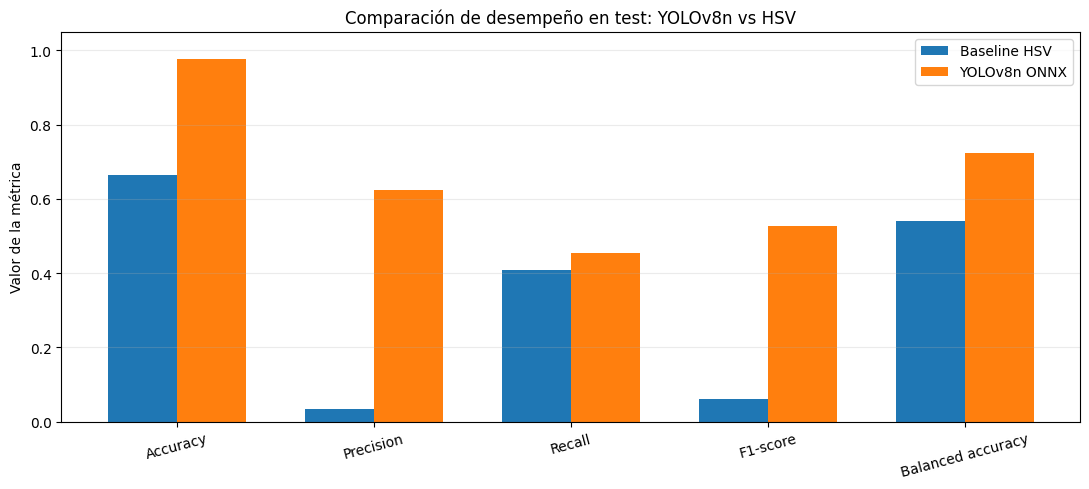

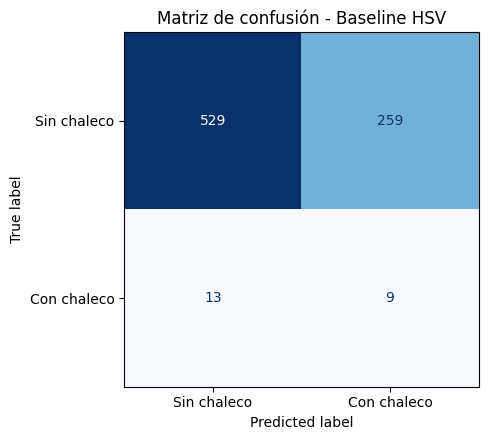

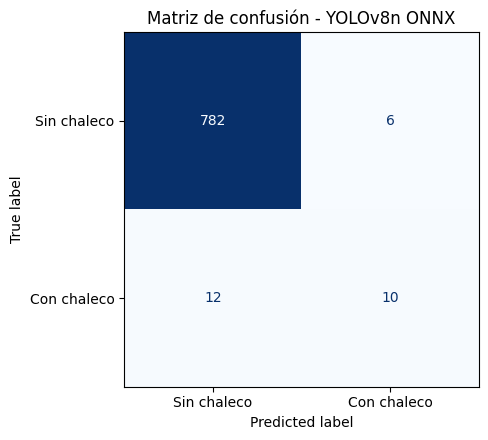


RESULTADO PRINCIPAL
---------------------------------------------
Mayor F1-score: YOLOv8n ONNX
Valor: 0.5263

Archivos guardados en: /content/drive/MyDrive/Certamen2_IA/Evaluacion_Baseline_Punto4
Comparación cuantitativa completada.
No se ejecutaron nuevas inferencias.


In [23]:

# ============================================================
# 4.5. COMPARACIÓN CUANTITATIVA YOLOv8n VS BASELINE HSV
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from IPython.display import display


# ------------------------------------------------------------
# 1. RECUPERAR PREDICCIONES GUARDADAS
# ------------------------------------------------------------

ARCHIVO_HSV = (
    SALIDA / "predicciones_baseline_test_v1_640.csv"
)

ARCHIVO_YOLO = (
    SALIDA / "predicciones_yolo_test_onnx_cpu_v1.csv"
)

if not ARCHIVO_HSV.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV HSV: {ARCHIVO_HSV}"
    )

if not ARCHIVO_YOLO.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV YOLO: {ARCHIVO_YOLO}"
    )

hsv = pd.read_csv(ARCHIVO_HSV)
yolo = pd.read_csv(ARCHIVO_YOLO)

columnas_hsv = {
    "imagen", "real", "pred_baseline",
    "fraccion_color", "segundos_baseline"
}

columnas_yolo = {
    "imagen", "real", "pred_yolo",
    "segundos_yolo"
}

assert columnas_hsv.issubset(hsv.columns)
assert columnas_yolo.issubset(yolo.columns)

assert len(hsv) == len(yolo) == 810

assert hsv["imagen"].is_unique
assert yolo["imagen"].is_unique


# ------------------------------------------------------------
# 2. UNIR RESULTADOS POR NOMBRE DE IMAGEN
# ------------------------------------------------------------

comparacion = hsv[
    [
        "imagen", "real", "pred_baseline",
        "fraccion_color", "segundos_baseline"
    ]
].merge(
    yolo[
        [
            "imagen", "real", "pred_yolo",
            "segundos_yolo"
        ]
    ],
    on="imagen",
    how="outer",
    suffixes=("_hsv", "_yolo"),
    validate="one_to_one",
    indicator=True
)

assert len(comparacion) == 810

assert comparacion["_merge"].eq("both").all(), (
    "Las imágenes no coinciden entre ambos métodos."
)

comparacion = comparacion.drop(columns="_merge")

# Verificar que las etiquetas sean idénticas
assert (
    comparacion["real_hsv"]
    == comparacion["real_yolo"]
).all(), "Existen discrepancias en las etiquetas reales."

comparacion["real"] = (
    comparacion["real_hsv"].astype(int)
)

comparacion = comparacion.drop(
    columns=["real_hsv", "real_yolo"]
)

# Verificar valores válidos
for columna in ["real", "pred_baseline", "pred_yolo"]:
    assert comparacion[columna].notna().all()
    assert comparacion[columna].isin([0, 1]).all()

for columna in ["segundos_baseline", "segundos_yolo"]:
    assert comparacion[columna].notna().all()
    assert comparacion[columna].ge(0).all()

assert comparacion["real"].sum() == 22

print("VERIFICACIÓN DE DATOS")
print("-" * 45)
print("Imágenes coincidentes:", len(comparacion))
print("Positivos reales:", int(comparacion["real"].sum()))
print("Etiquetas coincidentes: Sí")


# ------------------------------------------------------------
# 3. FUNCIÓN DE EVALUACIÓN BINARIA
# ------------------------------------------------------------

def calcular_metricas(y_real, y_pred, nombre, tiempos):

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_real, y_pred
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Positivos predichos": int(np.sum(y_pred)),
        "Tiempo promedio (s)": float(np.mean(tiempos)),
        "Tiempo total (s)": float(np.sum(tiempos))
    }


# ------------------------------------------------------------
# 4. CALCULAR MÉTRICAS DE AMBOS MÉTODOS
# ------------------------------------------------------------

y_real = comparacion["real"].to_numpy()

pred_hsv = comparacion["pred_baseline"].to_numpy()
pred_yolo = comparacion["pred_yolo"].to_numpy()

metricas_hsv = calcular_metricas(
    y_real,
    pred_hsv,
    "Baseline HSV",
    comparacion["segundos_baseline"].to_numpy()
)

metricas_yolo = calcular_metricas(
    y_real,
    pred_yolo,
    "YOLOv8n ONNX",
    comparacion["segundos_yolo"].to_numpy()
)

resumen = pd.DataFrame([
    metricas_hsv,
    metricas_yolo
])

print("\nCOMPARACIÓN DE MÉTRICAS")
print("-" * 45)

display(
    resumen[
        [
            "Modelo",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "Balanced accuracy"
        ]
    ].round(4)
)

print("\nMATRIZ DE RESULTADOS")
print("-" * 45)

display(
    resumen[
        [
            "Modelo", "TP", "FP", "FN", "TN",
            "Positivos predichos"
        ]
    ]
)

print("\nCOMPARACIÓN DE TIEMPOS")
print("-" * 45)

display(
    resumen[
        [
            "Modelo",
            "Tiempo promedio (s)",
            "Tiempo total (s)"
        ]
    ].round(4)
)

# Accuracy de referencia clasificando todo como negativo
accuracy_referencia = float(np.mean(y_real == 0))

print(
    "\nAccuracy de clasificar todo como negativo:",
    round(accuracy_referencia, 4)
)


# ------------------------------------------------------------
# 5. GUARDAR TABLAS DE RESULTADOS
# ------------------------------------------------------------

ARCHIVO_RESUMEN = (
    SALIDA / "comparacion_yolo_vs_hsv_test.csv"
)

ARCHIVO_DETALLE = (
    SALIDA / "detalle_comparacion_test.csv"
)

resumen.to_csv(
    ARCHIVO_RESUMEN, index=False
)

comparacion.to_csv(
    ARCHIVO_DETALLE, index=False
)

print("\nTablas guardadas correctamente.")


# ------------------------------------------------------------
# 6. GRÁFICO COMPARATIVO DE MÉTRICAS
# ------------------------------------------------------------

indicadores = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Balanced accuracy"
]

posiciones = np.arange(len(indicadores))
ancho_barra = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    posiciones - ancho_barra / 2,
    [metricas_hsv[c] for c in indicadores],
    width=ancho_barra,
    label="Baseline HSV"
)

ax.bar(
    posiciones + ancho_barra / 2,
    [metricas_yolo[c] for c in indicadores],
    width=ancho_barra,
    label="YOLOv8n ONNX"
)

ax.set_xticks(posiciones)
ax.set_xticklabels(indicadores, rotation=15)
ax.set_ylim(0, 1.05)

ax.set_ylabel("Valor de la métrica")
ax.set_title(
    "Comparación de desempeño en test: YOLOv8n vs HSV"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    SALIDA / "grafico_metricas_comparacion.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 7. MATRICES DE CONFUSIÓN
# ------------------------------------------------------------

modelos = [
    ("Baseline HSV", pred_hsv, "matriz_confusion_hsv.png"),
    ("YOLOv8n ONNX", pred_yolo, "matriz_confusion_yolo.png")
]

for nombre, predicciones, archivo in modelos:

    matriz = confusion_matrix(
        y_real,
        predicciones,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(5.5, 4.5))

    visualizador = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=[
            "Sin chaleco",
            "Con chaleco"
        ]
    )

    visualizador.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"Matriz de confusión - {nombre}")

    plt.tight_layout()

    plt.savefig(
        SALIDA / archivo,
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 8. IDENTIFICAR MEJOR F1-SCORE
# ------------------------------------------------------------

mejor = resumen.loc[
    resumen["F1-score"].idxmax()
]

print("\nRESULTADO PRINCIPAL")
print("-" * 45)

print("Mayor F1-score:", mejor["Modelo"])
print("Valor:", round(float(mejor["F1-score"]), 4))

print("\nArchivos guardados en:", SALIDA)
print("Comparación cuantitativa completada.")
print("No se ejecutaron nuevas inferencias.")



## 4.6. Análisis e interpretación de los resultados

### 4.6.1. Desempeño general de los métodos

La evaluación cuantitativa permitió comparar el desempeño de YOLOv8n ONNX y una alternativa simple basada en segmentación HSV para identificar la presencia de chalecos de seguridad en imágenes del dataset SH17.

Ambos métodos fueron evaluados sobre las mismas 810 imágenes del conjunto de test, de las cuales 22 contenían al menos un chaleco de seguridad según las anotaciones disponibles.

Los resultados muestran que **YOLOv8n obtuvo un desempeño superior al baseline HSV**, alcanzando una accuracy de 97,78 %, precision de 62,50 %, recall de 45,45 % y F1-score de 0,5263. Por su parte, HSV obtuvo una accuracy de 66,42 %, precision de 3,36 %, recall de 40,91 % y F1-score de 0,0621.

La diferencia es especialmente relevante en el F1-score, donde YOLOv8n obtuvo un valor aproximadamente 8,5 veces superior al del método tradicional.

### 4.6.2. Análisis de las matrices de confusión

Las matrices de confusión permiten comprender las diferencias entre ambos métodos.

El baseline HSV identificó correctamente 9 de las 22 imágenes positivas, pero generó 259 falsos positivos y 13 falsos negativos. Estos resultados reflejan las limitaciones de una estrategia basada exclusivamente en colores, ya que otras prendas, objetos o elementos presentes en las imágenes pueden contener tonalidades similares a las de los chalecos de alta visibilidad.

En contraste, YOLOv8n identificó correctamente 10 imágenes positivas, registrando 6 falsos positivos y 12 falsos negativos.

Esto representa una **reducción aproximada del 97,7 % en falsos positivos** respecto del baseline HSV. Esta diferencia es especialmente importante en un sistema de monitoreo, donde una cantidad elevada de falsas alertas puede dificultar la interpretación de los resultados.

Sin embargo, YOLOv8n no presentó una mejora considerable en recall, aumentando desde 40,91 % hasta 45,45 %. Esto demuestra que ambos métodos mantienen dificultades para identificar la totalidad de las imágenes que contienen chalecos.

### 4.6.3. Efecto del desbalance de clases

El conjunto de test presenta un desbalance considerable: solamente 22 de las 810 imágenes corresponden a casos positivos, equivalentes aproximadamente al 2,72 % del total.

Este desbalance requiere interpretar la accuracy con precaución. Un clasificador que predijera ausencia de chaleco en todas las imágenes obtendría una accuracy de 97,28 %, sin identificar correctamente ningún caso positivo.

Por esta razón, se utiliza el F1-score como principal indicador comparativo, complementado con precision, recall, balanced accuracy y las matrices de confusión.

YOLOv8n obtuvo una balanced accuracy de 72,35 %, frente al 54,02 % de HSV, lo que respalda su mejor desempeño considerando ambas clases.

### 4.6.4. Comparación de tiempos de procesamiento

Respecto del costo computacional, el baseline HSV registró un tiempo promedio de 0,3562 segundos por imagen, mientras que YOLOv8n ONNX requirió 0,5961 segundos.

Por lo tanto, YOLOv8n presentó un tiempo promedio aproximadamente 67,4 % mayor que el método HSV.

Esta diferencia es consistente con la mayor complejidad computacional de la inferencia mediante redes neuronales frente a operaciones tradicionales de procesamiento de imágenes.

No obstante, los tiempos fueron obtenidos durante ejecuciones en Google Colab y no constituyen una comparación controlada de rendimiento. Por ello, deben interpretarse como referencias operacionales del entorno utilizado.

### 4.6.5. Limitaciones de la evaluación

Aunque YOLOv8n presentó mejores resultados, existen limitaciones relevantes.

En primer lugar, el reducido número de imágenes positivas (22) limita la estabilidad de las estimaciones de desempeño. Una variación de pocas detecciones correctas puede modificar considerablemente las métricas.

En segundo lugar, la evaluación se realizó mediante clasificación binaria de presencia de chaleco a nivel de imagen, sin evaluar la precisión de las coordenadas de las detecciones ni calcular métricas de localización como mAP.

Adicionalmente, la implementación ONNX utilizó un criterio simplificado de presencia por imagen, sin aplicar NMS, por lo que los resultados corresponden específicamente al procedimiento de inferencia implementado.

Finalmente, el modelo YOLOv8n presentó 12 falsos negativos. Esto constituye una limitación importante si el sistema se utiliza para monitorear el cumplimiento de medidas de seguridad, ya que la ausencia de una detección no garantiza que una imagen carezca de chalecos.

### 4.6.6. Conclusión de la comparación

Los resultados permiten concluir que **YOLOv8n ONNX constituye una alternativa considerablemente más efectiva que la segmentación HSV para identificar chalecos de seguridad en el conjunto de test evaluado**.

Su principal ventaja se encuentra en la mayor precision y en la reducción de falsos positivos, lo que permite obtener predicciones más selectivas que las generadas mediante segmentación de colores.

Aunque el baseline HSV presentó un menor tiempo promedio de procesamiento, su elevado número de falsas detecciones limita su utilidad como método principal.

Por otra parte, el recall de YOLOv8n evidencia que todavía existe margen de mejora. Antes de utilizar el sistema como mecanismo autónomo de supervisión, sería necesario evaluar más imágenes positivas, estudiar los falsos negativos y validar su desempeño en condiciones reales.

En consecuencia, esta comparación respalda la elección de YOLOv8n sobre la alternativa simple HSV dentro del proyecto, sin afirmar que el modelo actual garantice una detección completa ni que pueda reemplazar la supervisión humana.
